# Sales Effectiveness: Lead Quality Prediction

## 1. Project Overview

This project analyzes the sales leads of **FicZon Inc.**, a company that receives leads from several channels (website, calls, chat, referrals and others) and hands them to a team of sales agents.

The objective is to understand what drives sales effectiveness and to build a machine learning model that predicts whether a lead is **High Potential** or **Low Potential**, so that the sales team can focus its effort during the conversation instead of only analysing results afterwards.

## 2. Problem Statement

Each lead ends with a recorded **Status** (for example `CONVERTED`, `Junk Lead` or `In Progress Positive`). Management wants two things:

1. **Insights** into sales effectiveness: which channels, products, locations, delivery modes and agents are associated with better outcomes.
2. **A prediction model** that assigns each lead a *Lead Category* (High Potential or Low Potential) so that leads are already categorized when the conversation starts.

The project covers the full analysis: data audit, exploratory analysis, SQL analysis, cleaning, leakage-safe feature engineering, model development, time-ordered evaluation, recommendations, a pilot design, a Power BI specification and a model comparison report.

## 3. Project Objectives

The main objectives of this project are:

1. Understand the business problem and define measurable success criteria.
2. Audit the lead data for quality problems, privacy risks and ambiguity in the target.
3. Perform exploratory data analysis and answer the sales effectiveness questions with evidence and uncertainty.
4. Confirm the meaning of `Status` and define the Lead Category target transparently.
5. Prevent target leakage and avoid using personal data (Mobile, EMAIL) as model features.
6. Build baseline and machine learning models inside scikit-learn pipelines.
7. Evaluate on **later months** than the training data, using cross-validation that respects time order and a test set that is used only once.
8. Report precision, recall, F1-score, ROC-AUC, PR-AUC and confusion matrices.
9. Translate the results into recommendations, a pilot design, and a Power BI specification.
10. Be honest about limitations: nothing is claimed that the data cannot support.

## 4. Dataset Description

The dataset is a lead export with **7,422 rows** and nine documented fields:

| Field | Meaning |
|---|---|
| `Created` | date and time the lead was created |
| `Product_ID` | product the lead is interested in |
| `Source` | acquisition channel |
| `Mobile` | contact phone number (personal data) |
| `EMAIL` | contact email (personal data) |
| `Sales_Agent` | agent who handled the lead |
| `Location` | delivery location |
| `Delivery_Mode` | delivery mode |
| `Status` | outcome of the lead, entered by the agent |

The file is delimited with semicolons and encoded as Windows-1252. The notebook detects the format automatically if your copy was re-saved differently.

**The dataset is proprietary training material and is not distributed with this notebook.** Place your copy next to the notebook as `sales_project.csv`.

### 4.1 What Status means, and how the target is defined

The brief does not define the Status values, so the mapping below is a **working assumption** that should be confirmed by the project owner. It is kept in one place (the configuration cell) so that it can be changed in a single edit.

| Lead Category | Status values |
|---|---|
| **High Potential** | `CONVERTED`, `In Progress Positive`, `Potential`, `Long Term` |
| **Low Potential** | `Junk Lead`, `Not Responding`, `Just Enquiry`, `LOST`, `In Progress Negative`, `Open` |

`Open` means unresolved; it is mapped to Low in the main run and tested the other way later. **No rows are dropped.**

Context supplied by the project owner, used in later decisions: sales agents were assigned whenever someone was free and when the lead placed an order on the website, with segmentation partly by delivery mode and location, and the Status was noted after contact.

### 4.2 Safeguards followed throughout

- No findings, model scores or business impact are invented: every number shown is computed in this notebook.
- `Mobile` and `EMAIL` are removed immediately after loading. They are never used as features and never exported.
- Leakage, class imbalance and high-cardinality features are checked explicitly.
- All preprocessing sits inside scikit-learn pipelines, and the test months are never used for tuning.
- No credentials appear in this notebook and no database is contacted.

## 5. Importing Libraries

In [1]:
import os
import sys
import json
import time
import sqlite3
import hashlib
import secrets
import shutil
import warnings
from pathlib import Path
from contextlib import closing

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import yaml
from scipy.stats import norm, spearmanr

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

print("Python :", sys.version.split()[0])
print("pandas :", pd.__version__, "| numpy:", np.__version__)
import sklearn
print("sklearn:", sklearn.__version__)
assert int(pd.__version__.split(".")[0]) >= 3, "Install pandas 3 or newer: pip install 'pandas>=3.0,<4'"

Python : 3.11.15
pandas : 3.0.2 | numpy: 2.4.4
sklearn: 1.8.0


## 6. Configuration

All project settings live in this one cell: the file location, the target mapping, the KPI definitions, the label merges for `Source`, the time-ordered split dates and the random seed. Keeping them together makes the notebook easy to audit.

- **Time-ordered split.** Training uses leads created up to 31 August 2018, validation uses September, and the test set is everything created from 1 October. Predicting later months from earlier ones is how the model would actually be used.
- **Random seed** is fixed so that results can be reproduced.
- **Hash salt** is random and used only to build an internal, non-reversible key for checking repeated contacts. Results do not depend on its value.

In [2]:
CSV_PATH = Path("sales_project.csv")          # place the dataset next to this notebook
if not CSV_PATH.exists() and Path("data/raw/sales_project.csv").exists():
    CSV_PATH = Path("data/raw/sales_project.csv")

SEED = 42
MIN_CATEGORY_COUNT = 30                       # rare category levels are pooled by the encoder
SALT = os.environ.get("FICZON_HASH_SALT") or secrets.token_hex(16)

CFG = {
    "high_potential": ["CONVERTED", "In Progress Positive", "Potential", "Long Term"],
    "low_potential": ["Junk Lead", "Not Responding", "Just Enquiry", "LOST", "In Progress Negative", "Open"],
    "kpi": {"converted": ["CONVERTED"], "no_engagement": ["Junk Lead", "Not Responding"], "unresolved": ["Open"]},
    "source_map": {
        # whitespace/spelling variants and obviously equivalent names only (confirm with the project owner)
        "Live Chat -PPC": "Live Chat-PPC",
        "Existing Customer": "Existing Client",
        "E-Mail Message": "Email",
        "E-mail Campaign": "Email",
        "Live Chat-Justdial": "Just Dial",
    },
    "train_end": pd.Timestamp("2018-08-31 23:59:59"),
    "val_end": pd.Timestamp("2018-09-30 23:59:59"),
}
for folder in ["outputs", "models", "powerbi"]:
    Path(folder).mkdir(exist_ok=True)

assert CSV_PATH.exists(), "Place sales_project.csv next to this notebook."
print("data file :", CSV_PATH)
print("High      :", CFG["high_potential"])
print("Low       :", CFG["low_potential"])

data file : sales_project.csv
High      : ['CONVERTED', 'In Progress Positive', 'Potential', 'Long Term']
Low       : ['Junk Lead', 'Not Responding', 'Just Enquiry', 'LOST', 'In Progress Negative', 'Open']


## 7. Loading the Dataset

The loader tries the expected format first (semicolon delimiter, Windows-1252 encoding) and falls back to other common formats. It then checks that all nine documented columns are present, so that a wrongly read file fails immediately with a clear message instead of producing confusing errors later.

In [3]:
EXPECTED_COLUMNS = ["Created", "Product_ID", "Source", "Mobile", "EMAIL",
                    "Sales_Agent", "Location", "Delivery_Mode", "Status"]


def load_raw(path):
    """Read the raw export, auto-detecting the delimiter and encoding, and validate its columns."""
    tried = []
    for enc in ["cp1252", "utf-8-sig", "latin-1"]:
        for sep in [";", ",", "\t", "|"]:
            try:
                df = pd.read_csv(path, sep=sep, encoding=enc)
            except Exception as exc:
                tried.append(f"sep={sep!r} enc={enc}: {type(exc).__name__}")
                continue
            df.columns = [str(c).replace("\ufeff", "").strip() for c in df.columns]
            if all(c in df.columns for c in EXPECTED_COLUMNS):
                print(f"Read with delimiter {sep!r} and encoding {enc}")
                return df[EXPECTED_COLUMNS]
            tried.append(f"sep={sep!r} enc={enc}: columns {list(df.columns)[:9]}")
    raise ValueError("Could not find the expected columns. Tried: " + " | ".join(tried[:6]))


raw = load_raw(CSV_PATH)
raw.shape

Read with delimiter ';' and encoding cp1252


(7422, 9)

In [4]:
raw.drop(columns=["Mobile", "EMAIL"]).head()      # personal-data columns are not displayed

,Created,Product_ID,Source,Sales_Agent,Location,Delivery_Mode,Status
0,14-11-2018 10:05,NaN,Website,Sales-Agent-11,NaN,Mode-5,Open
1,14-11-2018 09:22,NaN,Website,Sales-Agent-10,NaN,Mode-5,Open
2,14-11-2018 09:21,NaN,Website,Sales-Agent-10,NaN,Mode-5,Open
3,14-11-2018 08:46,NaN,Website,Sales-Agent-10,NaN,Mode-5,Open
4,14-11-2018 07:34,NaN,Website,Sales-Agent-10,NaN,Mode-5,Open


In [5]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7422 entries, 0 to 7421
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Created        7422 non-null   str    
 1   Product_ID     7364 non-null   float64
 2   Source         7405 non-null   str    
 3   Mobile         5612 non-null   str    
 4   EMAIL          7422 non-null   str    
 5   Sales_Agent    7399 non-null   str    
 6   Location       7364 non-null   str    
 7   Delivery_Mode  7422 non-null   str    
 8   Status         7422 non-null   str    
dtypes: float64(1), str(8)
memory usage: 522.0 KB


## 8. Initial Dataset Inspection

The first look at the raw data confirms the number of rows and columns and the data types. `Created` is stored as text and must be parsed as a date. `Product_ID` is stored as a decimal number because it contains missing values; it is an identifier, not a quantity, so it will be treated as a category later.

`Mobile` and `EMAIL` contain personal data. In this export they are already partially masked, and some values are placeholders. They are inspected only for quality and are removed in the next section.

In [6]:
print("Rows    :", len(raw))
print("Columns :", raw.shape[1])
print()
mobile = raw["Mobile"].astype("string")
email = raw["EMAIL"].astype("string")
print(f"Mobile: {mobile.isna().sum():,} missing; {mobile.str.contains('X', na=False).sum():,} partly masked with 'X'")
print(f"EMAIL : {email.str.contains('@', na=False).sum():,} contain '@'; {(email == '#VALUE!').sum():,} are the spreadsheet error '#VALUE!'")
print("(the values themselves are deliberately not displayed)")

Rows    : 7422
Columns : 9

Mobile: 1,810 missing; 5,611 partly masked with 'X'
EMAIL : 4,842 contain '@'; 1,701 are the spreadsheet error '#VALUE!'
(the values themselves are deliberately not displayed)


## 9. Privacy-Safe Working Copy

Before any analysis, `Mobile` and `EMAIL` are removed from the working data. Two things are kept from them because they are useful and not identifying:

- `email_valid`: whether the email field contains an "@" (a data-quality signal).
- `contact_key`: a salted SHA-256 hash of the email (or mobile when there is no valid email). It is **only** used to check how often the same contact appears. It is never used as a model feature and never exported.

The target is also created here from the working mapping in the configuration. Status values are normalized first, because the audit found case-only duplicates such as `converted` and `CONVERTED`.

In [7]:
def normalize_status(s):
    """Trim whitespace and merge case-only variants (for example 'converted' -> 'CONVERTED')."""
    s = s.astype("string").str.strip()
    canon = {v.lower(): v for v in s.dropna().unique() if v == v.upper() or v[0].isupper()}
    return s.map(lambda v: canon.get(v.lower(), v) if pd.notna(v) else v)


def make_contact_key(df, salt):
    """Non-reversible grouping key per contact: email if valid, otherwise mobile, otherwise missing."""
    email = df["EMAIL"].astype("string").str.strip().str.lower()
    mobile = df["Mobile"].astype("string").str.strip()
    raw_key = email.where(email.str.contains("@", na=False), mobile)
    hashed = lambda v: hashlib.sha256((salt + v).encode("utf-8")).hexdigest()[:16]
    return raw_key.map(lambda v: hashed(v) if pd.notna(v) and v != "" else pd.NA)


def parse_created(s):
    """Expected format dd-mm-YYYY HH:MM; falls back to day-first parsing for re-saved files."""
    try:
        return pd.to_datetime(s, format="%d-%m-%Y %H:%M")
    except (ValueError, TypeError):
        out = pd.to_datetime(s, dayfirst=True, errors="coerce", format="mixed")
        if out.isna().any():
            raise ValueError(f"{int(out.isna().sum())} Created values could not be parsed")
        return out


leads = raw.copy()
leads.insert(0, "lead_id", range(1, len(leads) + 1))
leads["Status"] = normalize_status(leads["Status"])
leads["Created"] = parse_created(leads["Created"])
leads["contact_key"] = make_contact_key(leads, SALT)
leads["mobile_missing"] = leads["Mobile"].isna().astype(int)
leads["email_valid"] = leads["EMAIL"].astype("string").str.contains("@", na=False).astype(int)

high_set = set(CFG["high_potential"])
leads["target_high"] = leads["Status"].isin(high_set).astype(int)
leads = leads.drop(columns=["Mobile", "EMAIL"])        # personal data leaves the working data here

assert not {"Mobile", "EMAIL"} & set(leads.columns)
assert set(leads["Status"].dropna()) <= high_set | set(CFG["low_potential"]), "A Status value is not mapped"
print("working data:", leads.shape, "| columns:", list(leads.columns))
del raw                                              # the raw frame (with personal data) is no longer needed

working data: (7422, 12) | columns: ['lead_id', 'Created', 'Product_ID', 'Source', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Status', 'contact_key', 'mobile_missing', 'email_valid', 'target_high']


## 10. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the structure, quality and behaviour of the lead data before building any model. Every rate shown is accompanied by its sample size, and rates are drawn with 95% Wilson confidence intervals so that small groups are not over-interpreted.

The analysis covers:

- Dataset structure and data quality
- Status values, the target and class balance
- Lead volume and outcomes over time
- Performance by source, product, location, delivery mode and agent
- How agents appear to have been assigned (routing)
- Time-of-day and weekday patterns
- Contact-identifier quality
- Which fields are most associated with the outcome

In [8]:
# Plotting helpers used in the EDA sections
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, BLUE_SOFT, ORANGE, GRAY = "#2a78d6", "#9cbfec", "#eb6834", "#8f8e88"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.dpi": 100,
})

MISSING = "(missing)"


def wilson(k, n, z=1.96):
    """95% Wilson score interval for a proportion k/n."""
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


def group_levels(s, min_n=30):
    """Missing values get an explicit label; levels with fewer than min_n rows are folded into 'Other'."""
    s = s.astype("string").fillna(MISSING)
    counts = s.value_counts()
    keep = set(counts[counts >= min_n].index) | {MISSING}
    return s.where(s.isin(keep), f"Other (<{min_n} rows each)")


def rate_table(df, by, target="target_high"):
    """Count, High Potential rate and Wilson interval for each level of `by`."""
    g = df.groupby(by, observed=True)[target].agg(n="size", k="sum")
    g["rate"] = g.k / g.n
    g["lo"], g["hi"] = wilson(g.k, g.n)
    return g.reset_index()


def plot_rate_bars(tbl, label_col, title, overall):
    """Horizontal bars of the High Potential rate with 95% intervals and n labels."""
    t = tbl.copy()
    other = t[label_col].astype(str).str.startswith("Other (")
    t = pd.concat([t[other], t[~other].sort_values("rate")])
    y = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(9, max(3, 0.38 * len(t) + 1.2)))
    ax.barh(y, t.rate * 100, color=[BLUE if n >= 100 else BLUE_SOFT for n in t.n], height=0.62, zorder=2)
    ax.errorbar(t.rate * 100, y, xerr=[(t.rate - t.lo) * 100, (t.hi - t.rate) * 100],
                fmt="none", ecolor=INK2, elinewidth=1, capsize=2.5, zorder=3)
    ax.axvline(overall * 100, color=GRAY, ls="--", lw=1.2)
    for yi, (r, hi, n) in enumerate(zip(t.rate, t.hi, t.n)):
        ax.text(min(hi * 100 + 1.5, 101), yi, f"{r*100:.0f}%  (n={n:,})", va="center", fontsize=8.5, color=INK2)
    ax.set_yticks(y); ax.set_yticklabels(t[label_col]); ax.set_xlim(0, 120)
    ax.set_xlabel("High Potential rate (%), whiskers: 95% interval; dashed line: overall rate")
    ax.grid(axis="y", visible=False); ax.set_title(title)
    ax.legend(handles=[Patch(color=BLUE, label="n >= 100"), Patch(color=BLUE_SOFT, label="n < 100 (wide uncertainty)")],
              loc="lower right", fontsize=8, frameon=False)
    plt.tight_layout(); plt.show()


def cramers_v(x, y):
    """Bias-corrected Cramer's V between two categorical series (0 = unrelated, 1 = perfectly related)."""
    ct = pd.crosstab(x, y).to_numpy().astype(float)
    n = ct.sum()
    expected = ct.sum(1, keepdims=True) @ ct.sum(0, keepdims=True) / n
    chi2 = ((ct - expected) ** 2 / expected).sum()
    r, k = ct.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / max(1e-12, min(kc - 1, rc - 1))))


OVERALL = leads["target_high"].mean()
print(f"Overall High Potential rate: {OVERALL:.4f}")

Overall High Potential rate: 0.3839


### 10.1 Dataset Overview

The working data has one row per lead. The date range shows how long the data covers, and the number of unique values per column shows which fields are low-cardinality (good for grouping) and which are high-cardinality.

In [9]:
print("Rows                :", len(leads))
print("Unique lead ids     :", leads["lead_id"].nunique())
print("Created from        :", leads["Created"].min())
print("Created to          :", leads["Created"].max())
print("Days covered        :", (leads["Created"].max() - leads["Created"].min()).days)
print()
pd.DataFrame({
    "unique values": leads[["Product_ID", "Source", "Sales_Agent", "Location", "Delivery_Mode", "Status"]].nunique(),
    "missing": leads[["Product_ID", "Source", "Sales_Agent", "Location", "Delivery_Mode", "Status"]].isna().sum(),
})

Rows                : 7422
Unique lead ids     : 7422
Created from        : 2018-04-28 07:54:00
Created to          : 2018-11-14 10:05:00
Days covered        : 200



,unique values,missing
Product_ID,29,58
Source,25,17
Sales_Agent,12,23
Location,17,58
Delivery_Mode,5,0
Status,10,0


### 10.2 Data Quality Checks

Missing values, duplicate rows and blank strings are checked for every column. Duplicates are checked on the lead content (everything except the generated `lead_id` and the hashed contact key).

In [10]:
missing = leads.isna().sum()
quality = pd.DataFrame({"missing": missing, "missing %": missing / len(leads) * 100})
quality[quality["missing"] > 0]

,missing,missing %
Product_ID,58,0.781461
Source,17,0.229049
Sales_Agent,23,0.309890
Location,58,0.781461
contact_key,584,7.868499


In [11]:
content_cols = ["Created", "Product_ID", "Source", "Sales_Agent", "Location", "Delivery_Mode", "Status", "contact_key"]
print("Exact duplicate leads (same time, product, source, agent, location, mode, status and contact):",
      int(leads.duplicated(subset=content_cols).sum()))
print("Rows with a blank-string Source / Location / Agent:",
      int((leads[["Source", "Location", "Sales_Agent"]].astype("string").apply(lambda c: c.str.strip() == "")).any(axis=1).sum()))

Exact duplicate leads (same time, product, source, agent, location, mode, status and contact): 2


Rows with a blank-string Source / Location / Agent: 0


### 10.3 Status Values and the Target

The target is built from Status, so the Status values are examined first. The raw file contains case-only duplicates (for example `converted` and `CONVERTED`); these were merged during loading.

In [12]:
status_counts = leads["Status"].value_counts()
status_table = pd.DataFrame({
    "Count": status_counts,
    "Percentage": status_counts / len(leads) * 100,
    "Lead Category": [("High Potential" if s in high_set else "Low Potential") for s in status_counts.index],
})
status_table

,Count,Percentage,Lead Category
Status,,,
Junk Lead,1536,20.695230,Low Potential
Not Responding,1129,15.211533,Low Potential
CONVERTED,852,11.479386,High Potential
Just Enquiry,760,10.239828,Low Potential
Potential,708,9.539208,High Potential
Long Term,646,8.703853,High Potential
In Progress Positive,643,8.663433,High Potential
In Progress Negative,626,8.434384,Low Potential
LOST,440,5.928321,Low Potential


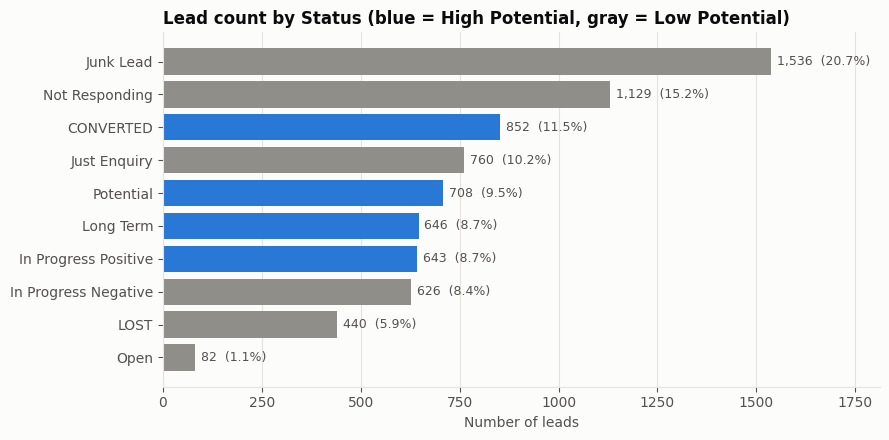

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = [BLUE if s in high_set else GRAY for s in status_counts.index[::-1]]
ax.barh(status_counts.index[::-1], status_counts.values[::-1], color=colors)
for i, v in enumerate(status_counts.values[::-1]):
    ax.text(v + 15, i, f"{v:,}  ({v / len(leads) * 100:.1f}%)", va="center", fontsize=9, color=INK2)
ax.set_xlim(0, status_counts.max() * 1.18); ax.grid(axis="y", visible=False)
ax.set_title("Lead count by Status (blue = High Potential, gray = Low Potential)"); ax.set_xlabel("Number of leads")
plt.tight_layout(); plt.show()

In [14]:
n_high = int(leads["target_high"].sum())
print(f"High Potential : {n_high:,} ({n_high / len(leads) * 100:.2f}%)")
print(f"Low Potential  : {len(leads) - n_high:,} ({(1 - n_high / len(leads)) * 100:.2f}%)")
print(f"Accuracy of always predicting Low Potential: {(1 - n_high / len(leads)) * 100:.2f}%")

High Potential : 2,849 (38.39%)
Low Potential  : 4,573 (61.61%)
Accuracy of always predicting Low Potential: 61.61%



**Findings:**

The working data contains 7,422 unique leads created between 28 April and 14 November 2018 (200 days). The data is clean in structure: no blank strings, only small amounts of missing values (58 leads each without Product and without Location, 23 without a Sales Agent, 17 without a Source), and 2 exact duplicate leads, which are kept because no row may be dropped.

- `Junk Lead` is the largest status (20.7%), followed by `Not Responding` (15.2%) and `CONVERTED` (11.5%).
- The working High Potential group (`CONVERTED`, `In Progress Positive`, `Potential`, `Long Term`) contains **2,849 leads (38.39%)** and the Low Potential group 4,573 leads (61.61%).
- A model that always predicts Low Potential would already be **61.61% accurate**, which is why accuracy is not used as the main metric.
- The imbalance is moderate, not severe, so no resampling is used. Balanced class weights and ranking metrics (ROC-AUC, PR-AUC, lift) are used instead.


### 10.4 Cleaning Category Labels

The audit of `Source` shows label variants that refer to the same channel (for example `Live Chat -PPC` and `Live Chat-PPC`). Only spelling and whitespace variants and obviously equivalent names are merged, using the mapping in the configuration. Blank strings become missing values, `Product_ID` becomes a category label such as `P18`, and three simple creation-time features are derived: month, hour-of-day bucket and weekday.

The cleaning function asserts that **no row is dropped**.

In [15]:
def clean_leads(df, cfg):
    """Standardize labels and types without dropping any row."""
    n_before = len(df)
    out = df.copy()
    for col in ["Source", "Sales_Agent", "Location", "Delivery_Mode", "Status"]:
        s = out[col].astype("object")
        s = s.where(s.isna(), s.astype(str).str.strip())
        out[col] = s.replace({"": np.nan})
    out["Source_clean"] = out["Source"].replace(cfg["source_map"])
    out["Product"] = out["Product_ID"].map(lambda v: f"P{int(v)}" if pd.notna(v) else np.nan)
    out["month"] = out["Created"].dt.strftime("%Y-%m")
    hour = out["Created"].dt.hour
    out["created_hour_bucket"] = pd.cut(hour, [-1, 8, 12, 16, 20, 24],
                                        labels=["00-08", "09-12", "13-16", "17-20", "21-23"]).astype(object)
    out["created_dow"] = out["Created"].dt.day_name()
    assert len(out) == n_before, "cleaning must not drop rows"
    return out


data = clean_leads(leads, CFG)
print("rows before / after cleaning:", len(leads), "/", len(data))
print("distinct Source labels before / after:", leads["Source"].nunique(), "/", data["Source_clean"].nunique())

rows before / after cleaning: 7422 / 7422
distinct Source labels before / after: 25 / 22


In [16]:
merged = {k: v for k, v in CFG["source_map"].items()}
pd.DataFrame({
    "raw label": list(merged.keys()),
    "rows": [int((leads["Source"] == k).sum()) for k in merged],
    "merged into": list(merged.values()),
})

,raw label,rows,merged into
0,Live Chat -PPC,249,Live Chat-PPC
1,Existing Customer,22,Existing Client
2,E-Mail Message,1,Email
3,E-mail Campaign,12,Email
4,Live Chat-Justdial,1,Just Dial


### 10.5 High Potential Rate by Source

The most important business question about channels is whether some bring better leads than others. Sources with fewer than 30 leads are pooled into one "Other" group so that tiny groups do not dominate the chart.

In [17]:
data["Source_g"] = group_levels(data["Source_clean"], 30)
source_tbl = rate_table(data, "Source_g")
source_tbl.sort_values("n", ascending=False)

,Source_g,n,k,rate,lo,hi
2,Call,2547,917,0.360031,0.341613,0.378871
8,Live Chat-Direct,1834,716,0.390403,0.368328,0.412938
14,Website,1594,568,0.356336,0.333196,0.380167
9,Live Chat-Google Organic,274,120,0.437956,0.380469,0.497159
10,Live Chat-PPC,249,95,0.381526,0.323423,0.443229
6,Live Chat-Blog,237,76,0.320675,0.264519,0.382552
3,Customer Referral,180,161,0.894444,0.841027,0.931378
13,US Website,137,2,0.014599,0.004013,0.051664
11,Other (<30 rows each),91,32,0.351648,0.261371,0.453944
4,Existing Client,73,68,0.931507,0.849477,0.970391


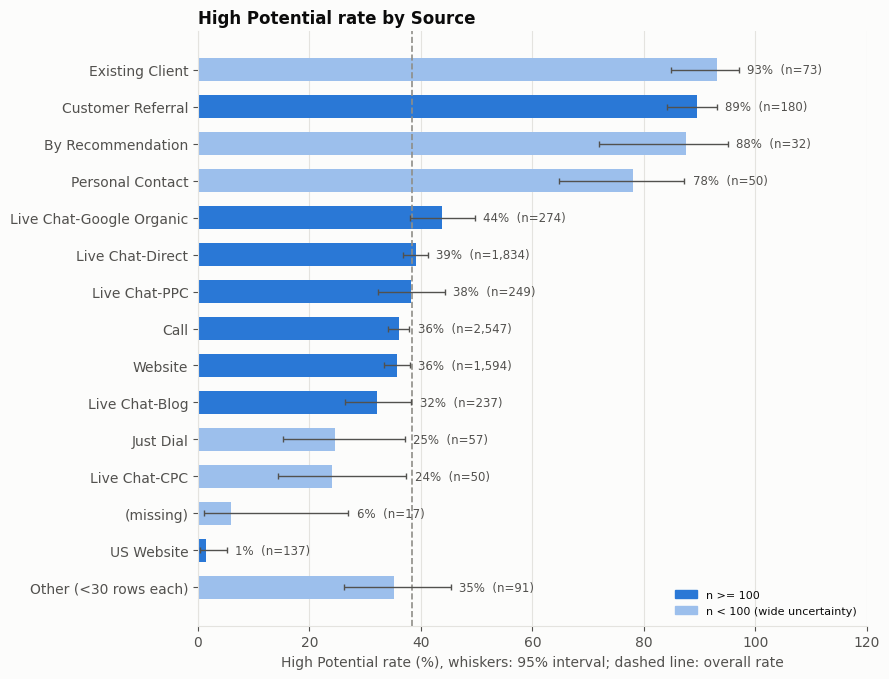

In [18]:
plot_rate_bars(source_tbl, "Source_g", "High Potential rate by Source", OVERALL)


**Findings:**

- The three largest sources are close to each other: `Live Chat-Direct` 39.0% High Potential (n=1,834), `Call` 36.0% (n=2,547) and `Website` 35.6% (n=1,594). Their intervals overlap, so the largest channels do not separate lead quality much.
- The big differences are in small sources. `Existing Client` (93.2%, n=73), `Customer Referral` (89.4%, n=180) and `By Recommendation` (87.5%, n=32) are very high, which is natural because referred and existing customers are high-intent.
- `US Website` is the opposite: only **2 of 137** leads (1.5%) are High Potential.
- Other small sources such as `Just Dial` (24.6%, n=57) and `Live Chat-CPC` (24.0%, n=50) are below average, but their intervals are wide.
- The 17 leads with a missing Source are nearly all Low Potential (1 of 17), which is too few to interpret.


### 10.6 Lead Volume and Outcomes Over Time

Lead volume and outcomes are tracked by creation month. Because Status is the final outcome entered by agents, **recent leads have had less time to reach a final status**. The status mix by month shows whether that is happening.

In [19]:
monthly = data.groupby("month").apply(lambda g: pd.Series({
    "leads": len(g),
    "High %": g["target_high"].mean() * 100,
    "CONVERTED %": (g["Status"] == "CONVERTED").mean() * 100,
    "Potential + In Progress Positive %": g["Status"].isin(["Potential", "In Progress Positive"]).mean() * 100,
    "Long Term + LOST %": g["Status"].isin(["Long Term", "LOST"]).mean() * 100,
    "Open %": (g["Status"] == "Open").mean() * 100,
}))
monthly

,leads,High %,CONVERTED %,Potential + In Progress Positive %,Long Term + LOST %,Open %
month,,,,,,
2018-04,115.0,40.869565,21.739130,4.347826,28.695652,0.869565
2018-05,1260.0,33.968254,16.031746,6.507937,24.920635,0.079365
2018-06,1285.0,34.474708,14.396887,10.038911,16.186770,1.011673
2018-07,1157.0,34.917891,11.495246,13.569576,16.248920,0.345722
2018-08,1119.0,36.461126,10.723861,17.873101,12.779267,1.161752
2018-09,1103.0,44.333636,9.700816,25.022665,12.601995,0.362647
2018-10,1000.0,45.300000,6.600000,34.000000,5.800000,0.700000
2018-11,383.0,46.214099,3.655352,42.297650,0.783290,10.182768


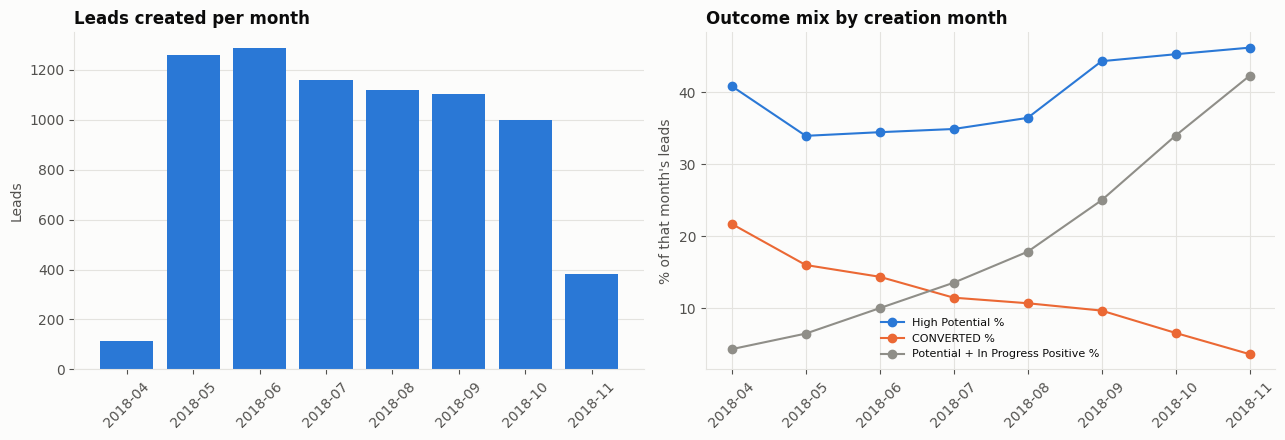

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(monthly.index, monthly["leads"], color=BLUE)
axes[0].set_title("Leads created per month"); axes[0].set_ylabel("Leads"); axes[0].grid(axis="x", visible=False)
axes[1].plot(monthly.index, monthly["High %"], marker="o", color=BLUE, label="High Potential %")
axes[1].plot(monthly.index, monthly["CONVERTED %"], marker="o", color=ORANGE, label="CONVERTED %")
axes[1].plot(monthly.index, monthly["Potential + In Progress Positive %"], marker="o", color=GRAY, label="Potential + In Progress Positive %")
axes[1].set_title("Outcome mix by creation month"); axes[1].set_ylabel("% of that month's leads"); axes[1].legend(frameon=False, fontsize=8)
for ax in axes: ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()


**Findings:**

- Lead volume was stable at about 1,100 to 1,300 leads per month from May to September, then 1,000 in October. November has 383 leads because the data stops on 14 November. April has only 115 leads because the data starts on 28 April.
- The High Potential rate rises from about 34% (May to July) to 44% to 46% (September to November).
- **The CONVERTED share moves the opposite way:** it falls steadily from 16.0% of May leads to 3.7% of November leads, while `Potential` plus `In Progress Positive` rises from 6.5% to 42.3%.
- This is a **label-maturity effect**. Recent leads have had less time to reach a final status, so they are still in progress, and the working label counts in-progress states as High Potential. **The rising High Potential rate is therefore partly unresolved leads, not better leads.** November also has 10.2% of leads still `Open`.
- Conversion claims need outcomes measured at a fixed lead age. This is carried into the limitations and the recommendations.


### 10.7 High Potential Rate by Product, Location and Delivery Mode

These three fields describe *what* the lead wants and *where* it is delivered. They are examined together because later sections show they carry most of the predictive signal.

In [21]:
data["Product_g"] = group_levels(data["Product"], 30)
product_tbl = rate_table(data, "Product_g")
product_tbl.sort_values("n", ascending=False).head(12)

,Product_g,n,k,rate,lo,hi
6,P18,1711,834,0.487434,0.463804,0.511120
5,P15,1518,80,0.052701,0.042547,0.065113
7,P19,1189,659,0.554247,0.525865,0.582281
15,P9,992,492,0.495968,0.464929,0.527037
13,P27,739,330,0.446549,0.411074,0.482577
14,P5,487,154,0.316222,0.276497,0.358823
3,P10,168,96,0.571429,0.495823,0.643841
2,P1,105,19,0.180952,0.119016,0.265411
9,P20,102,60,0.588235,0.491216,0.678850
1,Other (<30 rows each),92,14,0.152174,0.092865,0.239367


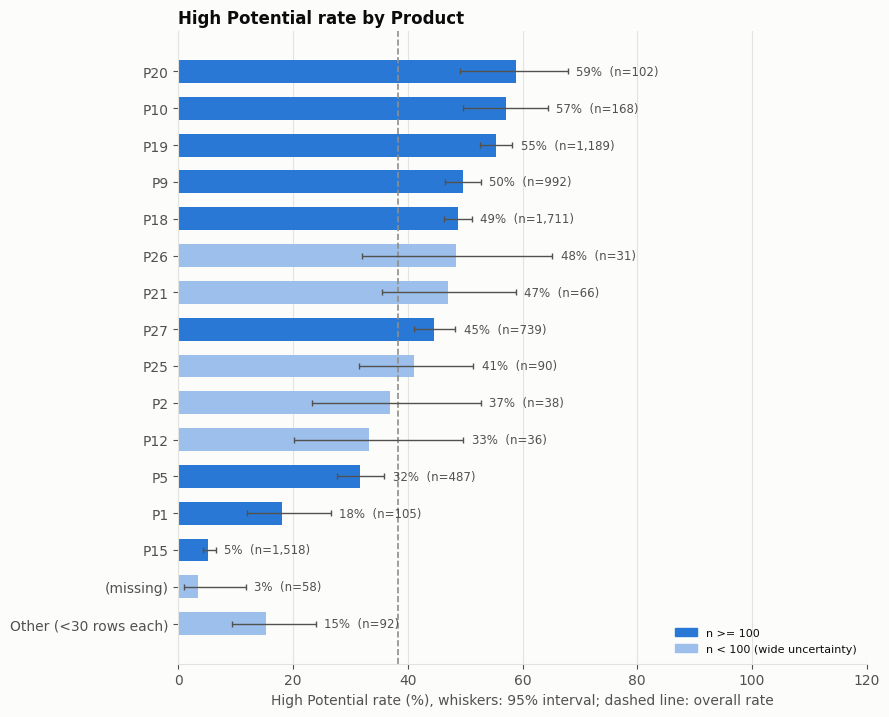

In [22]:
plot_rate_bars(product_tbl, "Product_g", "High Potential rate by Product", OVERALL)

In [23]:
data["Location_g"] = group_levels(data["Location"], 30)
location_tbl = rate_table(data, "Location_g")
location_tbl.sort_values("n", ascending=False)

,Location_g,n,k,rate,lo,hi
8,Other Locations,2500,429,0.171600,0.157327,0.186881
1,Bangalore,2084,1269,0.608925,0.587791,0.629658
2,Chennai,909,460,0.506051,0.473591,0.538459
4,Hyderabad,528,206,0.390152,0.349481,0.432409
3,Delhi,471,165,0.350318,0.308602,0.394457
6,Mumbai,402,140,0.348259,0.303321,0.396069
9,Pune,142,43,0.302817,0.233258,0.382764
11,UAE,79,38,0.481013,0.374295,0.589491
10,Trivandrum,58,22,0.379310,0.265641,0.507974
0,(missing),58,1,0.017241,0.003050,0.091411


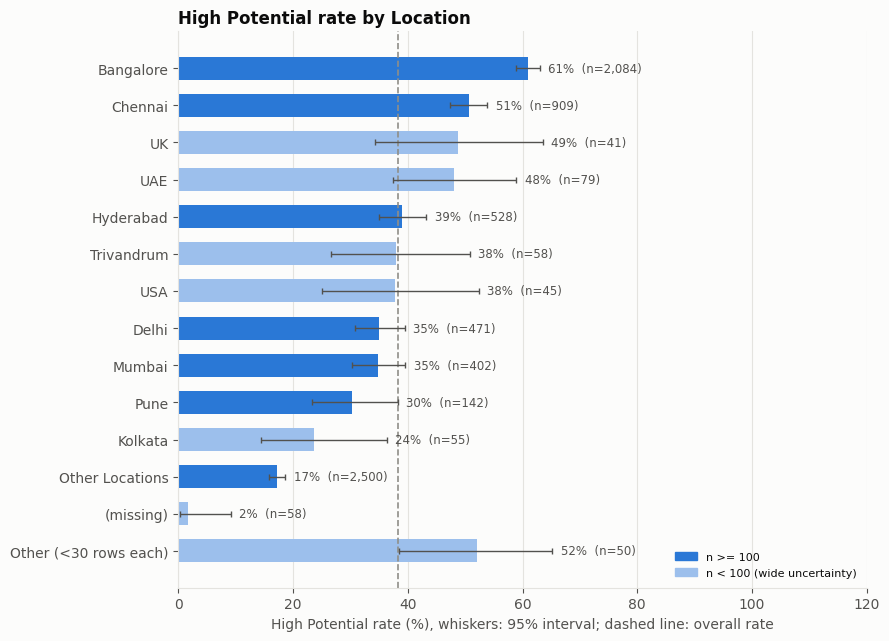

In [24]:
plot_rate_bars(location_tbl, "Location_g", "High Potential rate by Location", OVERALL)

In [25]:
data["Mode_g"] = group_levels(data["Delivery_Mode"], 30)
mode_tbl = rate_table(data, "Mode_g")
mode_tbl.sort_values("n", ascending=False)

,Mode_g,n,k,rate,lo,hi
3,Mode-5,2975,733,0.246387,0.231236,0.262192
0,Mode-1,2627,1331,0.506662,0.487547,0.525757
1,Mode-3,1688,698,0.413507,0.390236,0.437171
2,Mode-4,121,81,0.669421,0.581523,0.746893
4,Other (<30 rows each),11,6,0.545455,0.280088,0.787290


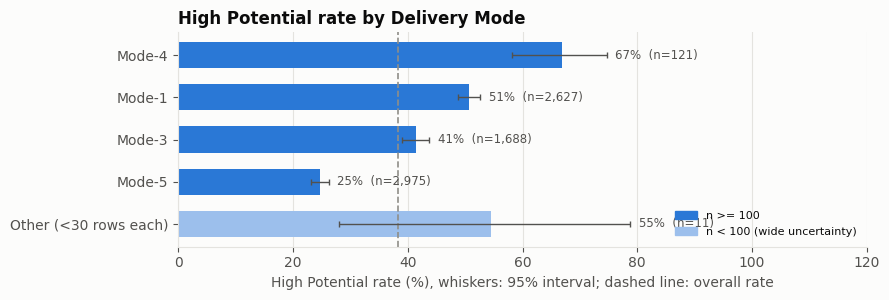

In [26]:
plot_rate_bars(mode_tbl, "Mode_g", "High Potential rate by Delivery Mode", OVERALL)


**Findings:**

Product, Location and Delivery Mode separate outcomes much more than Source does.

- **Product:** `P15` has only **5.3%** High Potential (80 of 1,518 leads) while `P19` has 55.4%, `P9` 49.6% and `P18` 48.7%. Small products vary widely (for example `P20` 58.8% with n=102 and `P1` 18.1% with n=105), with wide intervals.
- **Location:** `Other Locations` (a catch-all with 2,500 leads, a third of the data) has **17.2%** High Potential, versus `Bangalore` 60.9% and `Chennai` 50.6%. `Hyderabad` (39.0%), `Delhi` (35.0%) and `Mumbai` (34.8%) are lower. The 58 leads with a missing Location have almost no High Potential (1 of 58).
- **Delivery Mode:** `Mode-5` (the biggest, 2,975 leads) has **24.6%**, `Mode-3` 41.4% and `Mode-1` 50.7%. `Mode-4` is higher (66.9%) but small (n=121).

Because the catch-all "Other Locations" holds a third of all leads and the lowest rate, replacing it with real values at capture would likely reveal the largest quality differences.


### 10.8 No-Engagement Leads by Segment

Business teams also care about leads that never engage. The KPI "no engagement" is defined as `Junk Lead` or `Not Responding`. This table shows which segments hold a disproportionate share of such leads.

In [27]:
data["no_engagement"] = data["Status"].isin(CFG["kpi"]["no_engagement"]).astype(int)
total_ne = data["no_engagement"].sum()
rows = []
for col, label in [("Product_g", "Product"), ("Location_g", "Location"), ("Mode_g", "Delivery_Mode")]:
    g = data.groupby(col).agg(leads=("lead_id", "size"), no_eng=("no_engagement", "sum"), high=("target_high", "mean"))
    g["share of all leads %"] = g["leads"] / len(data) * 100
    g["share of all no-engagement leads %"] = g["no_eng"] / total_ne * 100
    g["High %"] = g["high"] * 100
    g.insert(0, "field", label)
    rows.append(g.sort_values("share of all no-engagement leads %", ascending=False).head(3))
pd.concat(rows)[["field", "leads", "share of all leads %", "share of all no-engagement leads %", "High %"]]

,field,leads,share of all leads %,share of all no-engagement leads %,High %
P15,Product,1518,20.452708,42.363977,5.270092
P18,Product,1711,23.053085,16.322702,48.743425
P19,Product,1189,16.019941,9.681051,55.424727
Other Locations,Location,2500,33.683643,54.896811,17.160000
Bangalore,Location,2084,28.078685,16.210131,60.892514
Chennai,Location,909,12.247373,8.067542,50.605061
Mode-5,Delivery_Mode,2975,40.083535,55.347092,24.638655
Mode-1,Delivery_Mode,2627,35.394772,24.803002,50.666159
Mode-3,Delivery_Mode,1688,22.743196,19.061914,41.350711



**Findings:**

Leads that never engage (`Junk Lead` or `Not Responding`) are concentrated in the same weak segments.

- Product `P15` holds 20.5% of all leads but **42.4%** of all no-engagement leads.
- `Other Locations` holds 33.7% of leads but **54.9%** of no-engagement leads.
- `Mode-5` holds 40.1% of leads but **55.3%** of no-engagement leads.

This segment pattern is the basis of the simple no-model rule tested in section 22 and of the recommendation to investigate what these segments actually are (non-target geography, support requests, spam, or a form default).


### 10.9 Sales Agents and How Leads Were Routed

The project owner explained that agents were assigned **whenever someone was free and when the lead placed an order on the website**, and that segmentation was planned by delivery mode and location. This matters because if agents were routed by segment, a raw comparison of agents mixes agent skill with segment difficulty.

First the raw agent view, then a check of how consistently each agent was tied to a delivery mode.

In [28]:
data["Agent_g"] = group_levels(data["Sales_Agent"], 30)
agent_tbl = rate_table(data, "Agent_g")
agent_tbl.sort_values("n", ascending=False)

,Agent_g,n,k,rate,lo,hi
7,Sales-Agent-4,1500,547,0.364667,0.340682,0.389343
3,Sales-Agent-11,1420,496,0.349296,0.324935,0.374469
8,Sales-Agent-5,1190,311,0.261345,0.237177,0.287048
12,Sales-Agent-9,879,558,0.634812,0.602459,0.665992
6,Sales-Agent-3,781,279,0.357234,0.324401,0.391465
10,Sales-Agent-7,736,319,0.433424,0.398059,0.469480
5,Sales-Agent-2,389,173,0.444730,0.396126,0.494415
4,Sales-Agent-12,269,82,0.304833,0.252888,0.362273
9,Sales-Agent-6,114,60,0.526316,0.435302,0.615614
11,Sales-Agent-8,68,22,0.323529,0.224374,0.441557


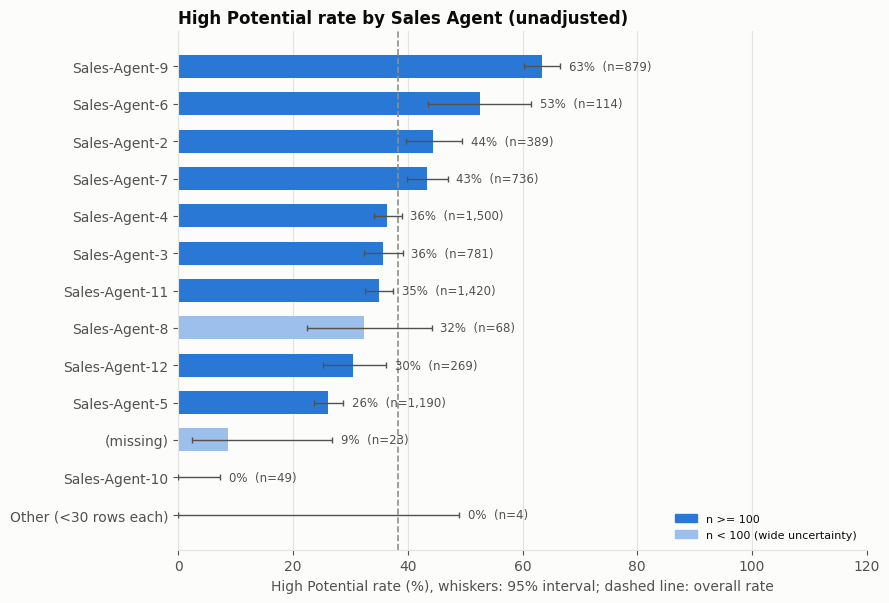

In [29]:
plot_rate_bars(agent_tbl, "Agent_g", "High Potential rate by Sales Agent (unadjusted)", OVERALL)

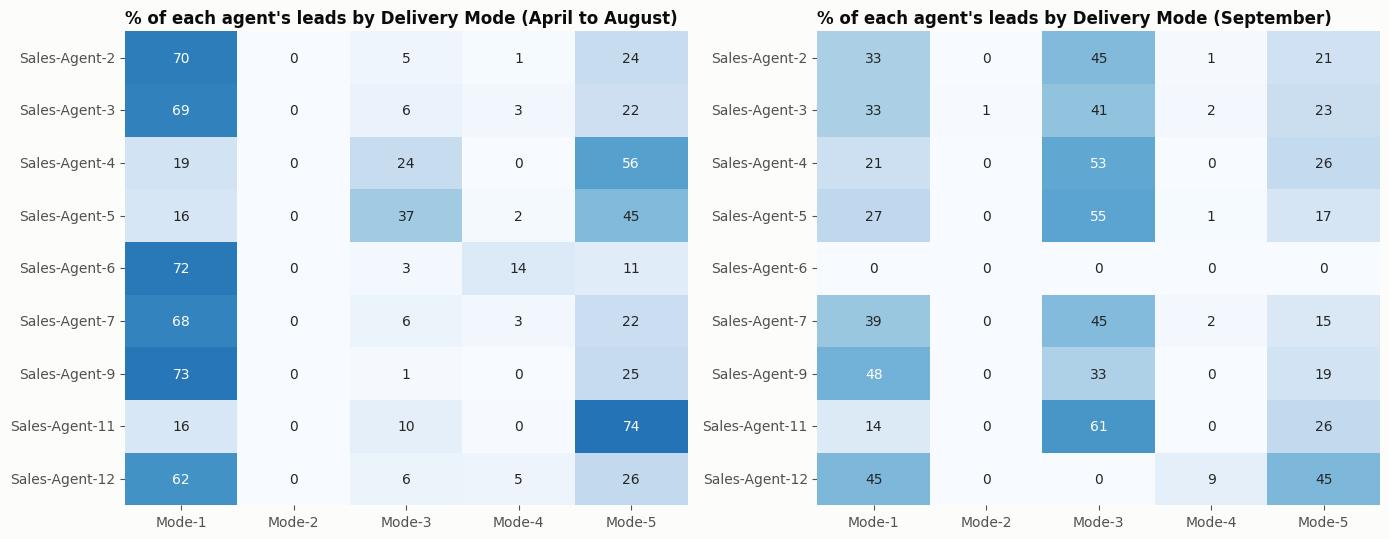

In [30]:
# Share of each agent's leads handled in each Delivery Mode, before September and in September
agents_sorted = sorted(data["Sales_Agent"].value_counts()[lambda s: s >= 100].index, key=lambda a: int(a.split("-")[-1]))
modes = sorted(data["Delivery_Mode"].dropna().unique())
periods = {"April to August": data["month"] < "2018-09", "September": data["month"] == "2018-09"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, mask) in zip(axes, periods.items()):
    sub = data[mask & data["Sales_Agent"].isin(agents_sorted)]
    ct = (pd.crosstab(sub["Sales_Agent"], sub["Delivery_Mode"], normalize="index") * 100).reindex(index=agents_sorted, columns=modes).fillna(0)
    sns.heatmap(ct, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar=False, vmin=0, vmax=100)
    ax.set_title(f"% of each agent's leads by Delivery Mode ({name})"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()


**Findings:**

Raw agent rates differ widely: `Sales-Agent-9` has 63.5% High Potential (n=879), while `Sales-Agent-5` has 26.1% (n=1,190) and `Sales-Agent-10` has 0 of 49. Before treating that as skill, the routing matters.

- From **April to August** the agents were clearly tied to delivery modes. Agents 2, 3, 7, 9 and 11 handled about 68% to 73% of their leads in Mode-1; Agent 12 handled 74% of its leads in Mode-5; Agent 4 (56%) and Agent 5 (45%) were concentrated in Mode-5, with Agent 5 also handling 37% in Mode-3.
- In **September** the pattern changes: most agents handled a mix of Mode-1 (14% to 48%), Mode-3 (33% to 61%, except Agent 12 with none) and Mode-5, which looks much closer to assignment by availability.

This confirms what the project owner described: assignment followed mode and location in part, and followed availability at other times. Since Mode-5 and Mode-1 have very different outcome rates (24.6% vs 50.7%), **raw agent rates mix agent differences with segment differences**. Section 21 therefore compares agents only within the same segment and month.


### 10.10 Time-of-Day and Weekday Patterns

Creation time is the one piece of information available the instant a lead arrives, so its relationship with the outcome is checked directly.

In [31]:
hour_tbl = rate_table(data, "created_hour_bucket")
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow_tbl = rate_table(data, "created_dow").set_index("created_dow").loc[dow_order].reset_index()
display(hour_tbl)
dow_tbl

,created_hour_bucket,n,k,rate,lo,hi
0,00-08,393,105,0.267176,0.225835,0.313023
1,09-12,3128,1126,0.359974,0.343334,0.376958
2,13-16,2238,977,0.436550,0.416128,0.457190
3,17-20,1364,541,0.396628,0.370991,0.422845
4,21-23,299,100,0.334448,0.283369,0.389728


,created_dow,n,k,rate,lo,hi
0,Monday,1513,579,0.382683,0.358519,0.407443
1,Tuesday,1319,535,0.405610,0.379423,0.432346
2,Wednesday,1272,487,0.382862,0.356539,0.409890
3,Thursday,1096,416,0.379562,0.351299,0.408666
4,Friday,1066,414,0.388368,0.359560,0.417977
5,Saturday,758,268,0.353562,0.320344,0.388257
6,Sunday,398,150,0.376884,0.330664,0.425458


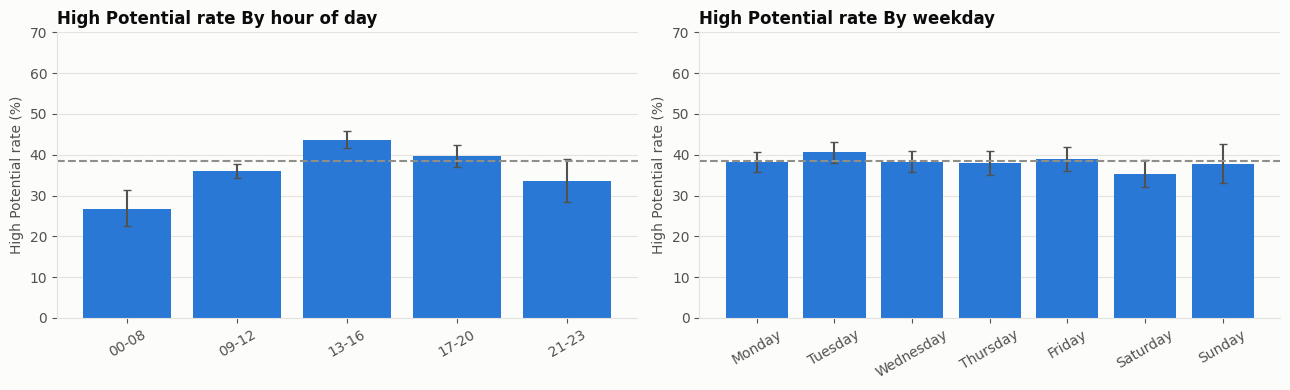

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, tbl, col, title in [(axes[0], hour_tbl, "created_hour_bucket", "By hour of day"), (axes[1], dow_tbl, "created_dow", "By weekday")]:
    ax.bar(tbl[col], tbl["rate"] * 100, color=BLUE, yerr=[(tbl.rate - tbl.lo) * 100, (tbl.hi - tbl.rate) * 100], ecolor=INK2, capsize=3)
    ax.axhline(OVERALL * 100, color=GRAY, ls="--"); ax.set_ylim(0, 70); ax.set_title(f"High Potential rate {title}")
    ax.set_ylabel("High Potential rate (%)"); ax.grid(axis="x", visible=False); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()


**Findings:**

- **Hour of day matters a little.** Leads created between midnight and 08:59 have the lowest High Potential rate (26.7%, n=393), and the 13:00 to 16:59 window has the highest (43.7%, n=2,238). The overall rate is 38.4%.
- **Weekday does not matter.** Rates range only from 35.4% (Saturday) to 40.6% (Tuesday) with overlapping intervals, and the association with the outcome is effectively zero.

Creation-time information is the only information available the instant a lead arrives, and it carries only a weak signal. This foreshadows the modelling result.


### 10.11 Contact Identifier Quality

The contact fields are partly masked or filled with placeholders in this export. That affects two things: whether leads from the same contact can be tracked, and whether statistical intervals that treat leads as independent are too narrow. The check uses the hashed contact key (no raw personal data).

In [33]:
key_counts = data["contact_key"].value_counts()
print("Rows with a contact key              :", int(data["contact_key"].notna().sum()))
print("Distinct contact keys                :", int(data["contact_key"].nunique()))
print("Most common single key covers        :", f"{key_counts.iloc[0]:,} rows ({key_counts.iloc[0] / len(data) * 100:.1f}% of all leads)")
print("Keys that appear more than once      :", int((key_counts > 1).sum()))
print(f"Rows with a valid-looking email      : {data['email_valid'].mean() * 100:.1f}%")
print(f"Rows with no email and no mobile     : {data['contact_key'].isna().mean() * 100:.1f}%")

Rows with a contact key              : 6838
Distinct contact keys                : 631
Most common single key covers        : 851 rows (11.5% of all leads)
Keys that appear more than once      : 297
Rows with a valid-looking email      : 65.2%
Rows with no email and no mobile     : 7.9%


In [34]:
by_month = data.groupby("month").agg(mobile_missing=("mobile_missing", "mean"), email_valid=("email_valid", "mean")) * 100
by_month.round(1)

,mobile_missing,email_valid
month,,
2018-04,100.0,70.4
2018-05,100.0,67.9
2018-06,33.9,66.0
2018-07,0.0,69.5
2018-08,0.0,58.4
2018-09,0.0,68.8
2018-10,0.0,63.2
2018-11,0.0,54.6



**Findings:**

- The contact identifiers are mostly **placeholders**. Only 631 distinct hashed keys exist for 6,838 leads that have a key, and the single most common key covers **851 leads (11.5%)**. 297 keys appear more than once.
- 65.2% of leads have a valid-looking email, and 7.9% have neither an email nor a mobile value.
- `mobile_missing` is a **time artifact**: it is 100% in April and May, 33.9% in June, and 0% from July onward. It reflects when the mobile field started being filled in, not lead quality. It is excluded from the models.
- Because many leads share the same placeholder identifier, leads are **not independent**, so confidence intervals that resample leads as independent understate the true uncertainty. This is stated as a limitation.


### 10.12 Association Strength

To see which fields matter most, the bias-corrected Cramér's V is computed between each categorical field and the target. A value of 0 means no relationship and 1 a perfect one. This is a descriptive ranking, not proof of causation, and `month` is included to show how much the outcome label moves with time.

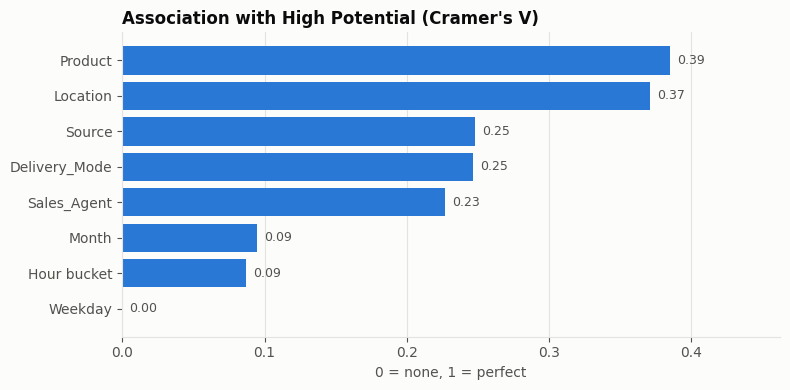

,Cramer's V
Product,0.385531
Location,0.371168
Source,0.248346
Delivery_Mode,0.246367
Sales_Agent,0.227087
Month,0.094504
Hour bucket,0.087229
Weekday,0.000000


In [35]:
assoc_fields = {"Location": "Location_g", "Product": "Product_g", "Delivery_Mode": "Mode_g", "Sales_Agent": "Agent_g",
                "Source": "Source_g", "Month": "month", "Hour bucket": "created_hour_bucket", "Weekday": "created_dow"}
assoc = pd.Series({name: cramers_v(data[col].astype(str), data["target_high"]) for name, col in assoc_fields.items()}).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(assoc.index, assoc.values, color=BLUE)
for i, v in enumerate(assoc.values): ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=9, color=INK2)
ax.set_xlim(0, assoc.max() * 1.2); ax.grid(axis="y", visible=False)
ax.set_title("Association with High Potential (Cramer's V)"); ax.set_xlabel("0 = none, 1 = perfect")
plt.tight_layout(); plt.show()
assoc.sort_values(ascending=False).to_frame("Cramer's V")


**Findings:**

- **Product (0.39) and Location (0.37)** are the most strongly associated fields with the outcome, followed by Source (0.25), Delivery Mode (0.25) and Sales Agent (0.23).
- The Source value is inflated by a few small, extreme sources (referrals, US Website), which the earlier tables showed. The three large sources are close together.
- Month (0.09) and hour of day (0.09) are weak, and weekday is 0.00.

This ranking, together with the earlier tables, already suggests that *what the customer wants and where it goes* matters more than *how the lead arrived*.



### 10.13 Key EDA Findings

The exploratory analysis produced the following key findings:

1. The dataset has 7,422 leads created from 28 April to 14 November 2018. It is structurally clean, with small amounts of missing values and 2 exact duplicates (kept).
2. The working High Potential group is 38.39% of leads. A model that always says Low would be 61.61% accurate, so ranking metrics are used.
3. The three largest sources (Call, Live Chat-Direct, Website) have similar High Potential rates (35.6% to 39.0%). Very high rates occur only in small referral and existing-client sources, and `US Website` is almost entirely Low.
4. **Product, Location and Delivery Mode** separate outcomes strongly: `P15` (5.3%), `Other Locations` (17.2%) and `Mode-5` (24.6%) are weak segments that hold more than half of all no-engagement leads.
5. Agents were tied to delivery modes from April to August and much less so in September, so raw agent comparisons are confounded.
6. Hour of day has a small effect and weekday none.
7. **Label maturity:** the CONVERTED share falls from 16.0% (May) to 3.7% (November) while in-progress statuses rise, so the rising High Potential rate is partly unresolved leads.
8. Contact identifiers are mostly placeholders, so leads are not independent; `mobile_missing` is a time artifact.

These findings drive the cleaning, the leakage audit and the feature ladder in the next sections.


## 11. SQL Analysis

The business questions are also answered in **SQL**, as required by the project. The privacy-safe working data (no Mobile, no EMAIL, no contact key) is loaded into a local SQLite database, and each query below answers a specific question. The same logic can be run on the company's MySQL table; the only dialect difference is date formatting (`strftime` in SQLite, `DATE_FORMAT` in MySQL).

No remote database is contacted in this notebook.

In [36]:
sql_cols = ["lead_id", "Created", "Product", "Source_clean", "Sales_Agent", "Location", "Delivery_Mode", "Status", "target_high", "month"]
sql_frame = data[sql_cols].copy()
sql_frame["Created"] = sql_frame["Created"].dt.strftime("%Y-%m-%d %H:%M:%S")
sql_frame["is_converted"] = (sql_frame["Status"] == "CONVERTED").astype(int)
sql_frame["is_no_engagement"] = sql_frame["Status"].isin(CFG["kpi"]["no_engagement"]).astype(int)

con = sqlite3.connect(":memory:")
sql_frame.to_sql("leads", con, index=False)


def q(sql):
    """Run a SQL query against the lead table and return a DataFrame."""
    return pd.read_sql_query(sql, con)


q("SELECT COUNT(*) AS rows_total, COUNT(DISTINCT lead_id) AS distinct_ids, MIN(Created) AS first_lead, MAX(Created) AS last_lead FROM leads")

,rows_total,distinct_ids,first_lead,last_lead
0,7422,7422,2018-04-28 07:54:00,2018-11-14 10:05:00


### 11.1 Data Audit Queries

Missing values per column, and the status mix with its Lead Category.

In [37]:
q("""
SELECT SUM(Product IS NULL)       AS product_missing,
       SUM(Source_clean IS NULL)  AS source_missing,
       SUM(Sales_Agent IS NULL)   AS agent_missing,
       SUM(Location IS NULL)      AS location_missing
FROM leads
""")

,product_missing,source_missing,agent_missing,location_missing
0,58,17,23,58


In [38]:
q("""
SELECT Status,
       COUNT(*)                                   AS leads,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM leads), 2) AS pct_of_leads,
       MAX(target_high)                           AS is_high_potential
FROM leads
GROUP BY Status
ORDER BY leads DESC
""")

,Status,leads,pct_of_leads,is_high_potential
0,Junk Lead,1536,20.70,0
1,Not Responding,1129,15.21,0
2,CONVERTED,852,11.48,1
3,Just Enquiry,760,10.24,0
4,Potential,708,9.54,1
5,Long Term,646,8.70,1
6,In Progress Positive,643,8.66,1
7,In Progress Negative,626,8.43,0
8,LOST,440,5.93,0
9,Open,82,1.10,0


### 11.2 Sales Effectiveness Queries

Source performance, monthly trend, and agent workload. Groups with fewer than 30 leads are excluded with `HAVING`, because their rates are too uncertain to compare.

In [39]:
q("""
SELECT Source_clean                      AS source,
       COUNT(*)                          AS leads,
       ROUND(100.0 * AVG(target_high), 1)   AS high_pct,
       ROUND(100.0 * AVG(is_converted), 1)  AS converted_pct,
       ROUND(100.0 * AVG(is_no_engagement), 1) AS no_engagement_pct
FROM leads
GROUP BY Source_clean
HAVING COUNT(*) >= 30
ORDER BY leads DESC
""")

,source,leads,high_pct,converted_pct,no_engagement_pct
0,Call,2547,36.0,9.5,40.8
1,Live Chat-Direct,1834,39.0,10.0,34.2
2,Website,1594,35.6,9.2,34.9
3,Live Chat-Google Organic,274,43.8,14.2,28.5
4,Live Chat-PPC,249,38.2,4.4,32.5
5,Live Chat-Blog,237,32.1,4.6,39.7
6,Customer Referral,180,89.4,66.7,5.0
7,US Website,137,1.5,0.0,68.6
8,Existing Client,73,93.2,65.8,2.7
9,Just Dial,57,24.6,1.8,36.8


In [40]:
q("""
SELECT month,
       COUNT(*)                              AS leads,
       ROUND(100.0 * AVG(target_high), 1)       AS high_pct,
       ROUND(100.0 * AVG(is_converted), 1)      AS converted_pct,
       ROUND(100.0 * AVG(is_no_engagement), 1)  AS no_engagement_pct
FROM leads
GROUP BY month
ORDER BY month
""")

,month,leads,high_pct,converted_pct,no_engagement_pct
0,2018-04,115,40.9,21.7,26.1
1,2018-05,1260,34.0,16.0,35.3
2,2018-06,1285,34.5,14.4,38.0
3,2018-07,1157,34.9,11.5,40.0
4,2018-08,1119,36.5,10.7,40.0
5,2018-09,1103,44.3,9.7,33.5
6,2018-10,1000,45.3,6.6,32.0
7,2018-11,383,46.2,3.7,26.4


In [41]:
q("""
SELECT Sales_Agent                       AS agent,
       COUNT(*)                          AS leads,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM leads WHERE Sales_Agent IS NOT NULL), 1) AS share_of_workload_pct,
       ROUND(100.0 * AVG(target_high), 1)   AS high_pct,
       ROUND(100.0 * AVG(is_converted), 1)  AS converted_pct
FROM leads
WHERE Sales_Agent IS NOT NULL
GROUP BY Sales_Agent
ORDER BY leads DESC
""")

,agent,leads,share_of_workload_pct,high_pct,converted_pct
0,Sales-Agent-4,1500,20.3,36.5,8.7
1,Sales-Agent-11,1420,19.2,34.9,8.4
2,Sales-Agent-5,1190,16.1,26.1,6.6
3,Sales-Agent-9,879,11.9,63.5,13.3
4,Sales-Agent-3,781,10.6,35.7,15.7
5,Sales-Agent-7,736,9.9,43.3,12.1
6,Sales-Agent-2,389,5.3,44.5,15.7
7,Sales-Agent-12,269,3.6,30.5,30.5
8,Sales-Agent-6,114,1.5,52.6,32.5
9,Sales-Agent-8,68,0.9,32.4,22.1


### 11.3 Segment Queries

Which product / location / delivery-mode segments hold the most no-engagement leads, and how the three biggest sources differ by delivery mode (a window function gives each mode's share within its source).

In [42]:
q("""
SELECT Product                           AS product,
       COUNT(*)                          AS leads,
       SUM(is_no_engagement)             AS no_engagement_leads,
       ROUND(100.0 * SUM(is_no_engagement) / (SELECT SUM(is_no_engagement) FROM leads), 1) AS share_of_all_no_engagement_pct,
       ROUND(100.0 * AVG(target_high), 1)   AS high_pct
FROM leads
GROUP BY Product
HAVING COUNT(*) >= 100
ORDER BY no_engagement_leads DESC
LIMIT 6
""")

,product,leads,no_engagement_leads,share_of_all_no_engagement_pct,high_pct
0,P15,1518,1129,42.4,5.3
1,P18,1711,435,16.3,48.7
2,P19,1189,258,9.7,55.4
3,P9,992,214,8.0,49.6
4,P27,739,209,7.8,44.7
5,P5,487,170,6.4,31.6


In [43]:
q("""
SELECT Source_clean AS source, Delivery_Mode AS mode, COUNT(*) AS leads,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY Source_clean), 1) AS pct_within_source,
       ROUND(100.0 * AVG(target_high), 1) AS high_pct
FROM leads
WHERE Source_clean IN ('Call', 'Live Chat-Direct', 'Website')
GROUP BY Source_clean, Delivery_Mode
HAVING COUNT(*) >= 30
ORDER BY Source_clean, leads DESC
""")

,source,mode,leads,pct_within_source,high_pct
0,Call,Mode-5,1551,61.0,22.1
1,Call,Mode-1,664,26.1,63.3
2,Call,Mode-3,283,11.1,44.5
3,Call,Mode-4,44,1.7,59.1
4,Live Chat-Direct,Mode-1,726,40.2,45.7
5,Live Chat-Direct,Mode-5,552,30.5,28.8
6,Live Chat-Direct,Mode-3,530,29.3,40.2
7,Website,Mode-5,568,35.8,28.2
8,Website,Mode-1,528,33.2,41.9
9,Website,Mode-3,492,31.0,37.0



**Findings from the SQL queries:**

The SQL results reproduce the pandas results exactly (7,422 leads, the same status counts and the same source and month rates), which confirms that the two analyses agree.

- Source performance: `Call` has the highest no-engagement share among the big sources (40.8%).
- Within a source, **delivery mode changes the outcome a lot.** For `Call`, 61.0% of leads are Mode-5 and have a High Potential rate of 22.1%, while the 26.1% in Mode-1 reach 63.3%. For `Website` the mix is balanced across modes (35.8%, 33.2%, 31.0%). So part of the difference between channels is really a difference in mode mix.
- Agent workload is concentrated: Agents 4, 11 and 5 handle 55.6% of the leads that have an agent.
- Product `P15` alone accounts for 42.4% of all no-engagement leads.


## 12. Feature Engineering and Leakage Audit

A model is only useful if it can use information that is **available when the prediction is needed**. Using information that is only known after the outcome (leakage) would make the results look excellent but would be useless in practice. This section decides which fields may be used, and why.

### 12.1 When is each field known?

| Field | Believed known when... | Treatment |
|---|---|---|
| Source, creation time | the lead is created | allowed (creation-time features) |
| Delivery_Mode, Location | the lead is assigned (the owner says agents were routed on them); **whether the customer enters them is not confirmed** | allowed in a separate, clearly labelled feature set |
| Product, email validity | possibly entered by a rep after contact (**not confirmed**) | allowed only in the "post-contact" feature set |
| Sales_Agent | the lead is assigned, but routing was partly by segment and the label is agent-entered | **excluded** from main models; sensitivity run only |
| Status | after the conversation | **the target, never a feature** |
| Mobile, EMAIL | at creation | **personal data, never used** |

Because the timing of several fields is unconfirmed, the project does not use one model and one claim. It builds a **ladder of three feature sets** and reports each separately.

In [44]:
def add_features(df):
    """Add completeness flags and a strictly-backward-looking contact-history count.

    prior_contact_leads counts EARLIER leads with the same hashed contact key (strictly before this lead
    in time), so it never uses future rows. It is created here only to test it for leakage.
    """
    out = df.copy()
    out["product_missing"] = out["Product"].isna().astype(int)
    out["source_missing"] = out["Source"].isna().astype(int)
    out["agent_missing"] = out["Sales_Agent"].isna().astype(int)
    out["location_missing"] = out["Location"].isna().astype(int)
    order = out.sort_values(["Created", "lead_id"]).index
    ck = out.loc[order, "contact_key"]
    prior = ck.groupby(ck).cumcount().where(ck.notna(), 0)
    out["prior_contact_leads"] = prior.reindex(out.index).astype(float)
    return out


feat = add_features(data).sort_values(["Created", "lead_id"]).reset_index(drop=True)
print("rows:", len(feat))
feat[["lead_id", "Created", "Source_clean", "created_hour_bucket", "created_dow", "Product", "Location", "Delivery_Mode",
      "email_valid", "mobile_missing", "prior_contact_leads", "target_high"]].head()

rows: 7422


,lead_id,Created,Source_clean,created_hour_bucket,created_dow,Product,Location,Delivery_Mode,email_valid,mobile_missing,prior_contact_leads,target_high
0,7422,2018-04-28 07:54:00,Website,00-08,Saturday,P25,Chennai,Mode-1,1,1,0.0,1
1,7421,2018-04-28 08:04:00,CRM form,00-08,Saturday,P21,Other Locations,Mode-1,1,1,0.0,0
2,7420,2018-04-28 09:20:00,Live Chat-Direct,09-12,Saturday,P5,Bangalore,Mode-1,1,1,0.0,0
3,7419,2018-04-28 09:43:00,Call,09-12,Saturday,P15,Other Locations,Mode-5,0,1,0.0,0
4,7418,2018-04-28 09:45:00,Call,09-12,Saturday,P9,Mumbai,Mode-4,1,1,0.0,0


### 12.2 The Preprocessing Pipeline

All fitting steps live inside the scikit-learn pipeline so that they are fitted **on training rows only**:

- **Categorical fields:** missing values become the label `Unknown`, then one-hot encoding. Levels with fewer than 30 rows are pooled into an "infrequent" group, which controls high-cardinality fields (there are 29 products and 17 locations). Unseen levels at prediction time are also handled.
- **Numeric count:** log transform and scaling.
- **Binary flags:** passed through.

In [45]:
CATEGORICAL = ["Source_clean", "created_hour_bucket", "created_dow", "Product", "Location", "Delivery_Mode", "Sales_Agent"]
NUMERIC = ["prior_contact_leads"]
BINARY = ["email_valid", "mobile_missing", "product_missing", "source_missing", "agent_missing", "location_missing"]


def make_preprocessor(columns, min_count=MIN_CATEGORY_COUNT):
    """ColumnTransformer for a subset of the known columns. Unfitted: fit it inside a Pipeline."""
    cat = [c for c in columns if c in CATEGORICAL]
    num = [c for c in columns if c in NUMERIC]
    binary = [c for c in columns if c in BINARY]
    unknown = set(columns) - set(cat) - set(num) - set(binary)
    if unknown:
        raise ValueError(f"Unknown feature columns: {sorted(unknown)}")
    parts = []
    if cat:
        parts.append(("cat", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_count, sparse_output=False)),
        ]), cat))
    if num:
        parts.append(("num", Pipeline([("log", __import__("sklearn.preprocessing", fromlist=["FunctionTransformer"]).FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                                       ("scale", StandardScaler())]), num))
    if binary:
        parts.append(("bin", "passthrough", binary))
    return ColumnTransformer(parts, remainder="drop", sparse_threshold=0.0)


print("Cardinality of categorical fields:")
feat[CATEGORICAL].nunique().to_frame("distinct values")

Cardinality of categorical fields:


,distinct values
Source_clean,22
created_hour_bucket,5
created_dow,7
Product,29
Location,17
Delivery_Mode,5
Sales_Agent,12


### 12.3 Time-Ordered Split

The data is split by **creation time**, never randomly. Random splitting would let the model learn from leads that were created after the ones it is tested on, which is not how it would be used.

- **Train:** created up to 31 August 2018
- **Validation:** September 2018 (used for comparing models)
- **Test:** 1 October to 14 November 2018 (used **once**, at the end)

In [46]:
def temporal_masks(created):
    """Boolean masks for train, validation and test. They are disjoint and cover every row."""
    train = created <= CFG["train_end"]
    val = (created > CFG["train_end"]) & (created <= CFG["val_end"])
    test = created > CFG["val_end"]
    assert ((train.astype(int) + val.astype(int) + test.astype(int)) == 1).all(), "split must be disjoint and exhaustive"
    return {"train": train, "val": val, "test": test}


masks = temporal_masks(feat["Created"])
train, val, test = feat[masks["train"]], feat[masks["val"]], feat[masks["test"]]
assert train["Created"].max() < val["Created"].min() < test["Created"].min()

pd.DataFrame({
    "rows": [len(train), len(val), len(test)],
    "from": [d["Created"].min().date() for d in (train, val, test)],
    "to": [d["Created"].max().date() for d in (train, val, test)],
    "High Potential %": [d["target_high"].mean() * 100 for d in (train, val, test)],
}, index=["train", "validation", "test"])

,rows,from,to,High Potential %
train,4936,2018-04-28,2018-08-31,35.048622
validation,1103,2018-09-01,2018-09-30,44.333636
test,1383,2018-10-01,2018-11-14,45.553145



**Findings:**

The split contains 4,936 training leads (28 April to 31 August), 1,103 validation leads (September) and 1,383 test leads (1 October to 14 November). The masks are disjoint, cover every lead, and are ordered in time (asserted in the code).

The High Potential rate is **35.0% in training, 44.3% in validation and 45.6% in test**. The label mix therefore moves between periods, which is partly the maturity effect described in section 10.6. It also means that threshold-based metrics cannot be expected to transfer unchanged from one period to another, while ranking metrics are more stable.


### 12.4 Leakage and Feature-Group Screening

Each group of candidate fields is tested by adding it to the always-allowed creation-time features (Source, hour bucket, weekday) and measuring how much better a logistic regression ranks the **validation month** (September) when trained on April to August only. The test months are not touched.

A large gain means the group carries signal. A group that gains a lot but whose timing is doubtful is a **leakage risk**, and a group that gains nothing is simply dropped.

In [47]:
TIER_A = ["Source_clean", "created_hour_bucket", "created_dow"]
GROUPS = {
    "Product": ["Product"],
    "Location": ["Location"],
    "Delivery_Mode": ["Delivery_Mode"],
    "Sales_Agent": ["Sales_Agent"],
    "email_valid": ["email_valid"],
    "mobile_missing": ["mobile_missing"],
    "field-missing flags": ["product_missing", "source_missing", "agent_missing", "location_missing"],
    "prior_contact_leads": ["prior_contact_leads"],
}
y_train, y_val = train["target_high"].to_numpy(), val["target_high"].to_numpy()


def screen(columns):
    pipe = Pipeline([("prep", make_preprocessor(columns)), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])
    pipe.fit(train[columns], y_train)
    s = pipe.predict_proba(val[columns])[:, 1]
    return roc_auc_score(y_val, s), average_precision_score(y_val, s)


base_roc, base_pr = screen(TIER_A)
rows = [{"feature group added": "(none: creation-time only)", "ROC-AUC": base_roc, "PR-AUC": base_pr, "PR-AUC gain": 0.0}]
for name, cols in GROUPS.items():
    r, p = screen(TIER_A + cols)
    rows.append({"feature group added": name, "ROC-AUC": r, "PR-AUC": p, "PR-AUC gain": p - base_pr})
screen_tbl = pd.DataFrame(rows)
print(f"Validation base rate (random-guess PR-AUC): {y_val.mean():.3f}")
screen_tbl.round(3)

Validation base rate (random-guess PR-AUC): 0.443


,feature group added,ROC-AUC,PR-AUC,PR-AUC gain
0,(none: creation-time only),0.563,0.506,0.000
1,Product,0.715,0.630,0.124
2,Location,0.709,0.632,0.126
3,Delivery_Mode,0.635,0.567,0.061
4,Sales_Agent,0.630,0.586,0.079
5,email_valid,0.653,0.603,0.097
6,mobile_missing,0.563,0.508,0.001
7,field-missing flags,0.564,0.509,0.003
8,prior_contact_leads,0.636,0.584,0.078


In [48]:
rho_t, _ = spearmanr(feat["prior_contact_leads"], feat["Created"].astype("int64"))
rho_y, _ = spearmanr(feat["prior_contact_leads"], feat["target_high"])
print(f"prior_contact_leads vs creation time : Spearman rho = {rho_t:.2f}")
print(f"prior_contact_leads vs target        : Spearman rho = {rho_y:.2f}")
print()
print("mobile_missing by month (percent of leads):")
(feat.groupby("month")["mobile_missing"].mean() * 100).round(1).to_frame("% mobile missing").T

prior_contact_leads vs creation time : Spearman rho = 0.36
prior_contact_leads vs target        : Spearman rho = 0.19

mobile_missing by month (percent of leads):


month,2018-04,2018-05,2018-06,2018-07,2018-08,2018-09,2018-10,2018-11
% mobile missing,100.0,100.0,33.9,0.0,0.0,0.0,0.0,0.0



**Findings:**

With only creation-time features the model has a validation ROC-AUC of 0.563 and a PR-AUC of 0.506, against 0.443 for random guessing.

| Field added | PR-AUC gain | Decision |
|---|---|---|
| Location | +0.126 | **Use** (assignment_time set) |
| Product | +0.124 | **Use** (post_contact set) |
| email_valid | +0.097 | **Use** (post_contact set) |
| Delivery_Mode | +0.061 | **Use** (assignment_time set) |
| Sales_Agent | +0.079 | **Exclude** from main models: agents were routed by segment, and the label is agent-entered, so this partly measures routing and recording habits |
| prior_contact_leads | +0.078 | **Exclude**: it correlates with time (Spearman 0.36) and is built on placeholder identifiers, so it counts identifier frequency, not real contact history |
| mobile_missing | +0.001 | **Exclude**: a pure time artifact (100% missing in April and May, 0% from July) |
| field-missing flags | +0.003 | **Exclude**: no ranking signal |

The strongest gains come from Location, Product, email validity and Delivery Mode, which matches the EDA.


### 12.5 The Three Feature Sets (the Ladder)

Based on the screening and the owner's context, three feature sets are defined. Each adds fields whose timing is less certain, so each result can be judged against what is actually known at the moment of prediction.

| Feature set | Columns | Timing |
|---|---|---|
| `creation_time` | Source, hour bucket, weekday | known when the lead is created |
| `assignment_time` | + Delivery_Mode, Location | known when routed (customer entry unconfirmed) |
| `post_contact` | + Product, email_valid | possibly rep-entered after contact |

A fourth variant per set adds `Sales_Agent` and is used **only as a sensitivity check**, never as a headline result.

**Excluded features and why**

| Feature | Reason |
|---|---|
| `mobile_missing` | Pure time artifact (always missing in April and May, never from July) |
| `prior_contact_leads` | Time proxy; identifiers are mostly shared placeholders, so it counts identifier frequency and not real contact history |
| missing-value flags | No ranking signal; each covers under 1% of rows |
| `Sales_Agent` | Routing and label confound; kept for sensitivity only |
| `Status`, `Mobile`, `EMAIL`, `contact_key` | target or personal data |

In [49]:
FEATURE_SETS = {
    "creation_time": list(TIER_A),
    "assignment_time": TIER_A + ["Delivery_Mode", "Location"],
    "post_contact": TIER_A + ["Delivery_Mode", "Location", "Product", "email_valid"],
}
HANDLER_AWARE_SETS = {f"{name}+agent": cols + ["Sales_Agent"] for name, cols in FEATURE_SETS.items()}

forbidden = {"Status", "target_high", "Mobile", "EMAIL", "contact_key", "Sales_Agent", "mobile_missing", "prior_contact_leads"}
for name, cols in FEATURE_SETS.items():
    assert not forbidden & set(cols), f"{name} contains an excluded field"
    print(f"{name:16s}", cols)

creation_time    ['Source_clean', 'created_hour_bucket', 'created_dow']
assignment_time  ['Source_clean', 'created_hour_bucket', 'created_dow', 'Delivery_Mode', 'Location']
post_contact     ['Source_clean', 'created_hour_bucket', 'created_dow', 'Delivery_Mode', 'Location', 'Product', 'email_valid']



**Findings:**

The three feature sets satisfy the assertion that none of them contains the target, a personal-data field, or an excluded feature. They are used in every model in the following sections, so each result can be read against what is actually known at the moment of prediction.


## 13. Model Evaluation Framework

A consistent evaluation framework is created so that all models are assessed with the same metrics and can be compared fairly.

**Why not accuracy?** High Potential is 38.4% of leads, so a model that always predicts Low Potential is already about 62% accurate. Accuracy would hide whether the model finds the leads that matter.

The framework reports:

- **ROC-AUC**: how well the model ranks High leads above Low leads (0.5 = random, 1.0 = perfect).
- **PR-AUC**: the same idea focused on the High class; a random model scores about the High rate, so it must be read against that base rate.
- **Precision, recall, F1-score** for the High class at a stated cut-off, with the confusion matrix.
- **Precision and lift in the top 20%**: if reps worked only the 20% of leads with the highest scores, how many would be High? Lift is that precision divided by the overall High rate.
- **95% bootstrap intervals** for ROC-AUC and PR-AUC, because a single test window is a small sample.

Ties in scores are broken with a seeded random permutation, never by row order, so results cannot depend on how the data happens to be sorted.

In [50]:
def _ranked_order(score, seed):
    """Indices sorted by descending score; exact ties are broken randomly (seeded), never by row order."""
    rng = np.random.default_rng(seed)
    perm = rng.permutation(len(score))
    return perm[np.argsort(-score[perm], kind="stable")]


def topk_flags(score, frac=0.2, seed=SEED):
    """0/1 vector flagging the top `frac` of leads by score."""
    score = np.asarray(score, dtype=float)
    k = max(1, int(round(frac * len(score))))
    flags = np.zeros(len(score), dtype=int)
    flags[_ranked_order(score, seed)[:k]] = 1
    return flags


def topk_metrics(y, score, frac=0.2, seed=SEED):
    """Precision, recall and lift if reps work only the top `frac` of leads by score."""
    y, score = np.asarray(y), np.asarray(score, dtype=float)
    k = max(1, int(round(frac * len(y))))
    top = _ranked_order(score, seed)[:k]
    precision = float(y[top].mean())
    recall = float(y[top].sum() / y.sum()) if y.sum() else float("nan")
    return {"precision_at_k": precision, "recall_at_k": recall, "lift_at_k": precision / float(y.mean())}


def bootstrap_ci(y, score, metric, n_boot=300, seed=SEED):
    """95% percentile interval of metric(y, score) over resampled rows."""
    y, score = np.asarray(y), np.asarray(score, dtype=float)
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        b = rng.integers(0, len(y), len(y))
        if y[b].min() != y[b].max():
            vals.append(metric(y[b], score[b]))
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return float(lo), float(hi)


def threshold_metrics(y, score, threshold):
    """Confusion matrix and precision/recall/F1 when leads with score >= threshold are flagged High."""
    y = np.asarray(y).astype(int)
    pred = (np.asarray(score, dtype=float) >= threshold).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    precision = tp / (tp + fp) if tp + fp else float("nan")
    recall = tp / (tp + fn) if tp + fn else float("nan")
    f1 = 2 * precision * recall / (precision + recall) if tp else 0.0
    return {"tn": tn, "fp": fp, "fn": fn, "tp": tp, "precision": precision, "recall": recall, "f1": f1, "flag_rate": float(pred.mean())}


def evaluate_scores(y, score, frac=0.2, seed=SEED):
    """Threshold-free metrics with bootstrap intervals, plus top-`frac` precision, recall and lift."""
    lo, hi = bootstrap_ci(y, score, roc_auc_score, seed=seed)
    plo, phi = bootstrap_ci(y, score, average_precision_score, seed=seed)
    out = {"roc_auc": roc_auc_score(y, score), "roc_lo": lo, "roc_hi": hi,
           "pr_auc": average_precision_score(y, score), "pr_lo": plo, "pr_hi": phi}
    out.update(topk_metrics(y, score, frac, seed))
    return out


# Validation-stage results are collected here so that all models can be compared in one table.
VAL_RESULTS, VAL_SCORES = [], {}
TRAIN_RATE = float(y_train.mean())


def evaluate_on_validation(model_name, feature_set, estimator, columns):
    """Fit on the training months, score the validation month, store ROC/PR/lift and a prevalence-matched cut-off.

    The cut-off flags the top-scoring share of leads equal to the training High rate (a model-agnostic choice that
    does not depend on how a model's probabilities are calibrated).
    """
    t0 = time.time()
    estimator.fit(train[columns], y_train)
    fit_s = time.time() - t0
    score = estimator.predict_proba(val[columns])[:, 1]
    m = evaluate_scores(y_val, score)
    flags = topk_flags(score, TRAIN_RATE)
    c = threshold_metrics(y_val, flags, 0.5)
    row = {"model": model_name, "feature_set": feature_set, "roc_auc": m["roc_auc"], "pr_auc": m["pr_auc"],
           "precision@top20%": m["precision_at_k"], "lift@top20%": m["lift_at_k"],
           "precision": c["precision"], "recall": c["recall"], "f1": c["f1"], "train_seconds": fit_s}
    VAL_RESULTS.append(row)
    VAL_SCORES[(model_name, feature_set)] = score
    return row


def get_val_results():
    return pd.DataFrame(VAL_RESULTS)


def plot_confusion(model_name, feature_set, title_note="prevalence-matched cut-off"):
    """Confusion matrix for the validation month at the prevalence-matched cut-off."""
    flags = topk_flags(VAL_SCORES[(model_name, feature_set)], TRAIN_RATE)
    cm = confusion_matrix(y_val, flags)
    fig, ax = plt.subplots(figsize=(4.6, 3.8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Low", "High"], yticklabels=["Low", "High"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"{model_name}, {feature_set}\n({title_note})", fontsize=10)
    plt.tight_layout(); plt.show()


def show_report(model_name, feature_set):
    flags = topk_flags(VAL_SCORES[(model_name, feature_set)], TRAIN_RATE)
    print(classification_report(y_val, flags, target_names=["Low Potential", "High Potential"], digits=3))


print("evaluation framework ready; training High rate (used for the cut-off): %.3f" % TRAIN_RATE)

evaluation framework ready; training High rate (used for the cut-off): 0.350


## 14. Baseline Models

Two simple baselines show how much a machine learning model must beat to be worth using.

1. **Majority class (prior):** predicts the same score for every lead. It has ROC-AUC 0.5 by construction and PR-AUC equal to the High rate.
2. **Source-rate rule:** a transparent rule that scores a lead by the historical High rate of its Source (smoothed so that tiny sources cannot give extreme scores). This is what a manager could do with a pivot table, so it is the baseline that matters.

In [51]:
class SourceRateBaseline(ClassifierMixin, BaseEstimator):
    """Score a lead by the smoothed training High rate of its Source. Unseen or missing sources get the overall rate."""

    def __init__(self, column="Source_clean", smoothing=20.0):
        self.column = column
        self.smoothing = smoothing

    def fit(self, X, y):
        y = np.asarray(y)
        self.classes_ = np.array([0, 1])
        self.prior_ = float(y.mean())
        g = pd.DataFrame({"k": X[self.column].astype("object").fillna("Unknown").to_numpy(), "y": y}).groupby("k")["y"].agg(["sum", "count"])
        self.rates_ = ((g["sum"] + self.smoothing * self.prior_) / (g["count"] + self.smoothing)).to_dict()
        return self

    def predict_proba(self, X):
        keys = X[self.column].astype("object").fillna("Unknown")
        p = keys.map(self.rates_).fillna(self.prior_).to_numpy(dtype=float)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


baselines = {
    "Majority class (prior)": Pipeline([("clf", DummyClassifier(strategy="prior"))]),
    "Source-rate rule": Pipeline([("clf", SourceRateBaseline())]),
}
for name, est in baselines.items():
    evaluate_on_validation(name, "Source only" if "Source" in name else "n/a", est, ["Source_clean"])
get_val_results().round(3)

,model,feature_set,roc_auc,pr_auc,precision@top20%,lift@top20%,precision,recall,f1,train_seconds
0,Majority class (prior),n/a,0.500,0.443,0.475,1.072,0.452,0.358,0.40,0.002
1,Source-rate rule,Source only,0.541,0.495,0.538,1.215,0.509,0.403,0.45,0.003



**Findings:**

- The **majority-class** model has ROC-AUC 0.500 and a PR-AUC of 0.443, which equals the September High rate. That is the floor for ranking.
- The **Source-rate rule** reaches ROC-AUC 0.541 and PR-AUC 0.495, with a lift of 1.21 in the top 20%. It is only a small improvement over random guessing, which confirms that the channel alone says little about lead quality.

Any model must be judged against this Source-rate rule, not only against random guessing.


## 15. Candidate Models

Three algorithms of increasing flexibility are trained on each of the three feature sets, inside pipelines:

| Algorithm | Why it is included |
|---|---|
| Logistic Regression | interpretable linear baseline; `class_weight="balanced"` so the 38% High class is not ignored |
| Random Forest | handles interactions between fields (for example Location × Product) with no tuning of encodings |
| Gradient Boosting (`HistGradientBoostingClassifier`) | a strong general-purpose tabular model |

At this stage the hyperparameters are fixed, reasonable defaults. **Tuning is done later with time-ordered cross-validation**, so the validation month is not tuned on directly.

In [52]:
def build_candidates(columns, min_count=MIN_CATEGORY_COUNT, seed=SEED):
    """The three candidate models over one feature set. The preprocessor is part of each pipeline."""
    def prep():
        return make_preprocessor(columns, min_count)

    return {
        "Logistic regression": Pipeline([("prep", prep()),
                                         ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
        "Random forest": Pipeline([("prep", prep()),
                                   ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced_subsample",
                                                                  n_jobs=-1, random_state=seed))]),
        "Gradient boosting": Pipeline([("prep", prep()),
                                       ("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_depth=3,
                                                                              min_samples_leaf=40, l2_regularization=1.0,
                                                                              random_state=seed))]),
    }


def build_estimator(name, params, columns, min_count=MIN_CATEGORY_COUNT, seed=SEED):
    """One candidate pipeline with `params` applied to its classifier step."""
    pipe = build_candidates(columns, min_count, seed)[name]
    pipe.set_params(**{f"clf__{k}": v for k, v in params.items()})
    return pipe


def run_model(model_name):
    """Train one algorithm on all three feature sets and return its validation results."""
    for fset, cols in FEATURE_SETS.items():
        evaluate_on_validation(model_name, fset, build_candidates(cols)[model_name], cols)
    r = get_val_results()
    return r[r["model"] == model_name].drop(columns="model").reset_index(drop=True)

### 15.1 Logistic Regression

Logistic Regression is the simplest model. Its three results show how much each added group of fields helps.

In [53]:
run_model("Logistic regression").round(3)

,feature_set,roc_auc,pr_auc,precision@top20%,lift@top20%,precision,recall,f1,train_seconds
0,creation_time,0.563,0.506,0.475,1.072,0.486,0.384,0.429,0.028
1,assignment_time,0.719,0.642,0.679,1.531,0.661,0.524,0.584,0.057
2,post_contact,0.761,0.697,0.769,1.735,0.674,0.534,0.596,0.046


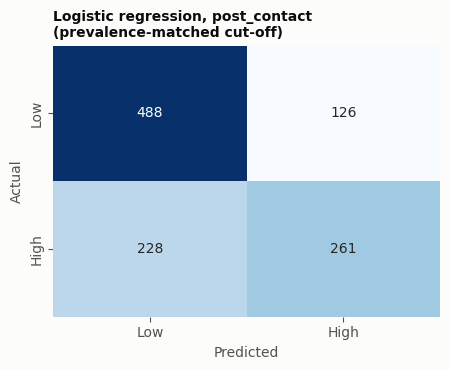

In [54]:
plot_confusion("Logistic regression", "post_contact")

In [55]:
show_report("Logistic regression", "post_contact")

                precision    recall  f1-score   support

 Low Potential      0.682     0.795     0.734       614
High Potential      0.674     0.534     0.596       489

      accuracy                          0.679      1103
     macro avg      0.678     0.664     0.665      1103
  weighted avg      0.678     0.679     0.673      1103




**Findings:**

- On the validation month, Logistic Regression improves steadily as fields are added: ROC-AUC **0.563 → 0.719 → 0.761** and PR-AUC 0.506 → 0.642 → 0.697 across `creation_time`, `assignment_time` and `post_contact`.
- The creation-time version (PR-AUC 0.506) is only 0.011 above the Source-rate rule (0.495), so time and source add very little.
- At the prevalence-matched cut-off (flagging the top 35% of leads) the `post_contact` model reaches a High-class precision of 0.674, recall of 0.534 and F1 of 0.596, with an overall accuracy of 0.679.
- The confusion matrix shows more errors on the High class (recall 0.534) than on the Low class (recall 0.795). A cut-off lower than the one used here would find more High leads at the price of more false alarms. The final evaluation uses a frozen, F1-optimal threshold for exactly that reason.
- Training takes well under a second.


### 15.2 Random Forest

A Random Forest can learn interactions, for example that a given product behaves differently in different locations.

In [56]:
run_model("Random forest").round(3)

,feature_set,roc_auc,pr_auc,precision@top20%,lift@top20%,precision,recall,f1,train_seconds
0,creation_time,0.552,0.503,0.475,1.072,0.491,0.389,0.434,0.911
1,assignment_time,0.705,0.635,0.692,1.562,0.649,0.513,0.573,0.967
2,post_contact,0.755,0.701,0.742,1.674,0.677,0.536,0.598,0.955


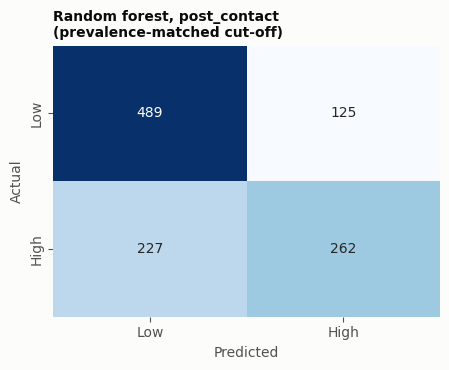

In [57]:
plot_confusion("Random forest", "post_contact")

In [58]:
show_report("Random forest", "post_contact")

                precision    recall  f1-score   support

 Low Potential      0.683     0.796     0.735       614
High Potential      0.677     0.536     0.598       489

      accuracy                          0.681      1103
     macro avg      0.680     0.666     0.667      1103
  weighted avg      0.680     0.681     0.675      1103




**Findings:**

- Random Forest gives almost the same ranking as Logistic Regression: ROC-AUC 0.552 → 0.705 → 0.755 and PR-AUC 0.503 → 0.635 → 0.701 across the three sets.
- With the `post_contact` fields it reaches precision 0.677, recall 0.536 and F1 0.598 at the cut-off, and a lift of 1.67 in the top 20%.
- It does not beat the much simpler Logistic Regression on the same features, which suggests that the interactions between fields add little beyond what the one-hot encoded fields already capture.
- It is slower (about one second to train) but still fast.


### 15.3 Gradient Boosting

In [59]:
run_model("Gradient boosting").round(3)

,feature_set,roc_auc,pr_auc,precision@top20%,lift@top20%,precision,recall,f1,train_seconds
0,creation_time,0.566,0.506,0.480,1.082,0.496,0.393,0.438,0.146
1,assignment_time,0.690,0.629,0.665,1.500,0.630,0.499,0.557,0.204
2,post_contact,0.755,0.702,0.778,1.756,0.687,0.544,0.607,0.306


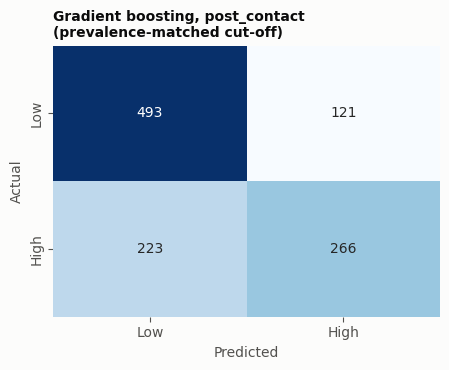

In [60]:
plot_confusion("Gradient boosting", "post_contact")

In [61]:
show_report("Gradient boosting", "post_contact")

                precision    recall  f1-score   support

 Low Potential      0.689     0.803     0.741       614
High Potential      0.687     0.544     0.607       489

      accuracy                          0.688      1103
     macro avg      0.688     0.673     0.674      1103
  weighted avg      0.688     0.688     0.682      1103




**Findings:**

- Gradient Boosting reaches ROC-AUC 0.566 → 0.690 → 0.755 and PR-AUC 0.506 → 0.629 → 0.702.
- For `post_contact` it has the highest validation PR-AUC (0.702) and the highest top-20% lift (1.76), with precision 0.687, recall 0.544 and F1 0.607 at the cut-off.
- The margin over Logistic Regression and Random Forest is tiny (PR-AUC 0.702 vs 0.697 and 0.701), well inside what one month of 1,103 leads can distinguish.
- With `assignment_time` it is slightly weaker (PR-AUC 0.629) than Logistic Regression (0.642).


## 16. Model Comparison on the Validation Month

All models are compared on September 2018, which none of them were trained on. The table is sorted by PR-AUC. Random guessing would score a PR-AUC equal to the September High rate.

In [62]:
validation_results = get_val_results().sort_values("pr_auc", ascending=False).reset_index(drop=True)
print(f"September High rate (PR-AUC of random guessing): {y_val.mean():.3f}")
validation_results.round(3)

September High rate (PR-AUC of random guessing): 0.443


,model,feature_set,roc_auc,pr_auc,precision@top20%,lift@top20%,precision,recall,f1,train_seconds
0,Gradient boosting,post_contact,0.755,0.702,0.778,1.756,0.687,0.544,0.607,0.306
1,Random forest,post_contact,0.755,0.701,0.742,1.674,0.677,0.536,0.598,0.955
2,Logistic regression,post_contact,0.761,0.697,0.769,1.735,0.674,0.534,0.596,0.046
3,Logistic regression,assignment_time,0.719,0.642,0.679,1.531,0.661,0.524,0.584,0.057
4,Random forest,assignment_time,0.705,0.635,0.692,1.562,0.649,0.513,0.573,0.967
5,Gradient boosting,assignment_time,0.690,0.629,0.665,1.500,0.630,0.499,0.557,0.204
6,Logistic regression,creation_time,0.563,0.506,0.475,1.072,0.486,0.384,0.429,0.028
7,Gradient boosting,creation_time,0.566,0.506,0.480,1.082,0.496,0.393,0.438,0.146
8,Random forest,creation_time,0.552,0.503,0.475,1.072,0.491,0.389,0.434,0.911
9,Source-rate rule,Source only,0.541,0.495,0.538,1.215,0.509,0.403,0.450,0.003


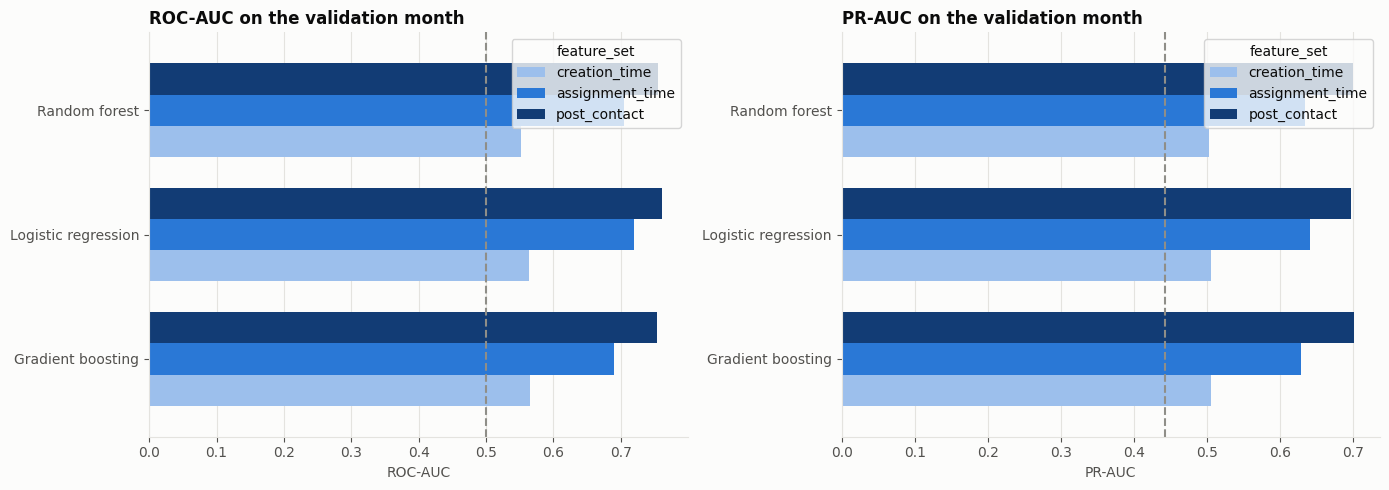

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pivot_roc = validation_results.pivot(index="model", columns="feature_set", values="roc_auc")
pivot_pr = validation_results.pivot(index="model", columns="feature_set", values="pr_auc")
order = ["creation_time", "assignment_time", "post_contact"]
for ax, piv, title in [(axes[0], pivot_roc, "ROC-AUC"), (axes[1], pivot_pr, "PR-AUC")]:
    piv = piv[[c for c in order if c in piv.columns]].dropna(how="all")
    piv.plot.barh(ax=ax, color=[BLUE_SOFT, BLUE, "#123c75"][: piv.shape[1]], width=0.75)
    ax.set_title(f"{title} on the validation month"); ax.set_xlabel(title); ax.set_ylabel(""); ax.grid(axis="y", visible=False)
axes[1].axvline(y_val.mean(), color=GRAY, ls="--"); axes[0].axvline(0.5, color=GRAY, ls="--")
plt.tight_layout(); plt.show()


**Findings:**

- **The feature set matters far more than the algorithm.** The top three rows are all `post_contact` models with PR-AUC of 0.697 to 0.702 and ROC-AUC of 0.755 to 0.761. The three `assignment_time` models follow at PR-AUC 0.629 to 0.642, and the `creation_time` models, the Source-rate rule and the majority class are at the bottom (0.443 to 0.506).
- Differences between algorithms on the same feature set are small (at most 0.013 in PR-AUC), so a single validation month cannot rank them. That is why the final choice uses cross-validation across four months and a parsimony rule.
- `creation_time` models (PR-AUC 0.503 to 0.506) are barely above the Source-rate rule (0.495).
- All models train in about a second or less, so computation cost is not a deciding factor.


## 17. Cross-Validation, Tuning and Freezing the Final Configuration

The validation month gave a first comparison, but a single month is a noisy basis for choosing models. A more reliable procedure is used here, with **time-ordered cross-validation** on the development data (training + validation, April to September):

- **Expanding-window folds.** For each of June, July, August and September, train on all earlier months and validate on that month. No fold ever trains on the month it is tested on or on later months.
- **Selection metric:** mean PR-AUC across the four folds.
- **Parsimony rule:** choose the *simplest* model class whose best score is within 0.01 PR-AUC of the overall best (order: logistic regression, gradient boosting, random forest). A more complex model must earn its place.
- **Threshold:** the F1-optimal threshold is picked from the pooled out-of-fold predictions.
- **Freezing:** the chosen models, parameters and thresholds are written to a configuration file **before the test months are touched**.

The hyperparameter grids are deliberately small and coarse: the data is one noisy window, so a fine search would only fit noise.

In [64]:
CV_MONTHS = ["2018-06", "2018-07", "2018-08", "2018-09"]
PARSIMONY_TOLERANCE = 0.01
SIMPLICITY_ORDER = ["Logistic regression", "Gradient boosting", "Random forest"]
PARAM_GRIDS = {
    "Logistic regression": {"C": [0.01, 0.1, 1.0, 10.0]},
    "Random forest": {"min_samples_leaf": [10, 30], "max_depth": [4, 8]},
    "Gradient boosting": {"learning_rate": [0.03, 0.1], "max_depth": [2, 3], "max_iter": [100, 250]},
}

dev = feat[masks["train"] | masks["val"]].reset_index(drop=True)      # April to September only
ydev = dev["target_high"].to_numpy()
assert dev["Created"].max() <= CFG["val_end"], "test rows must not be used for tuning"


def expanding_month_folds(created, val_months):
    """For each month M: train on rows created before M, validate on rows created in M. Returns index arrays."""
    month = created.dt.strftime("%Y-%m").to_numpy()
    folds = []
    for m in val_months:
        val_idx = np.flatnonzero(month == m)
        first_day = pd.Period(m).start_time.to_datetime64()
        train_idx = np.flatnonzero(created.to_numpy() < first_day)
        folds.append((train_idx, val_idx))
    return folds


def cv_scores(make_pipe, X, y, folds):
    """Fit on each expanding window, score the next month. Returns per-fold metrics and out-of-fold scores."""
    oof = np.full(len(y), np.nan)
    rows = []
    for (tr, va), month in zip(folds, CV_MONTHS):
        pipe = make_pipe().fit(X.iloc[tr], y[tr])
        s = pipe.predict_proba(X.iloc[va])[:, 1]
        oof[va] = s
        rows.append({"month": month, "n_train": len(tr), "n_val": len(va), "base_rate": float(y[va].mean()),
                     "roc_auc": roc_auc_score(y[va], s), "pr_auc": average_precision_score(y[va], s)})
    return rows, oof


def f1_best_threshold(y, s):
    """Threshold maximizing F1 on pooled out-of-fold scores."""
    cands = np.unique(np.quantile(s, np.linspace(0.02, 0.98, 97)))
    f1s = [f1_score(y, (s >= t).astype(int), zero_division=0) for t in cands]
    return float(cands[int(np.argmax(f1s))])


folds = expanding_month_folds(dev["Created"], CV_MONTHS)
pd.DataFrame([{"month": m, "train rows": len(tr), "validation rows": len(va),
               "latest training row": dev["Created"].iloc[tr].max().date(), "validation from": dev["Created"].iloc[va].min().date()}
              for (tr, va), m in zip(folds, CV_MONTHS)])

,month,train rows,validation rows,latest training row,validation from
0,2018-06,1375,1285,2018-05-31,2018-06-01
1,2018-07,2660,1157,2018-06-30,2018-07-01
2,2018-08,3817,1119,2018-07-31,2018-08-01
3,2018-09,4936,1103,2018-08-31,2018-09-01


### 17.1 Grid Search

Every parameter combination is scored on the four expanding-window folds, for each feature set. This is the slowest cell in the notebook (about a minute).

In [65]:
grid_rows, fold_detail = [], {}
for fset, cols in FEATURE_SETS.items():
    for model, grid in PARAM_GRIDS.items():
        for params in ParameterGrid(grid):
            rows, _ = cv_scores(lambda: build_estimator(model, params, cols), dev[cols], ydev, folds)
            r = pd.DataFrame(rows)
            grid_rows.append({"feature_set": fset, "model": model, "params": json.dumps(params, sort_keys=True),
                              "cv_pr_auc": r.pr_auc.mean(), "cv_roc_auc": r.roc_auc.mean(),
                              "pr_auc_sd": r.pr_auc.std(ddof=0), "worst_fold_pr_auc": r.pr_auc.min()})
cv_grid = pd.DataFrame(grid_rows)
print("parameter combinations scored:", len(cv_grid))
best_per_model = cv_grid.loc[cv_grid.groupby(["feature_set", "model"]).cv_pr_auc.idxmax()].reset_index(drop=True)
best_per_model.round(3)

parameter combinations scored: 48


,feature_set,model,params,cv_pr_auc,cv_roc_auc,pr_auc_sd,worst_fold_pr_auc
0,assignment_time,Gradient boosting,"{""learning_rate"": 0.1, ""max_depth"": 2, ""max_it...",0.590,0.721,0.063,0.480
1,assignment_time,Logistic regression,"{""C"": 10.0}",0.607,0.728,0.033,0.554
2,assignment_time,Random forest,"{""max_depth"": 4, ""min_samples_leaf"": 10}",0.618,0.735,0.025,0.578
3,creation_time,Gradient boosting,"{""learning_rate"": 0.1, ""max_depth"": 3, ""max_it...",0.473,0.582,0.051,0.391
4,creation_time,Logistic regression,"{""C"": 10.0}",0.495,0.587,0.024,0.464
5,creation_time,Random forest,"{""max_depth"": 4, ""min_samples_leaf"": 10}",0.498,0.593,0.020,0.468
6,post_contact,Gradient boosting,"{""learning_rate"": 0.1, ""max_depth"": 3, ""max_it...",0.646,0.767,0.067,0.533
7,post_contact,Logistic regression,"{""C"": 10.0}",0.661,0.772,0.036,0.601
8,post_contact,Random forest,"{""max_depth"": 8, ""min_samples_leaf"": 10}",0.660,0.770,0.036,0.605


### 17.2 Applying the Parsimony Rule and Freezing the Configuration

In [66]:
frozen = {"cv_months": CV_MONTHS, "parsimony_tolerance": PARSIMONY_TOLERANCE, "sets": {}}
for fset, cols in FEATURE_SETS.items():
    best = best_per_model[best_per_model.feature_set == fset].set_index("model")
    top = best.cv_pr_auc.max()
    chosen = [m for m in SIMPLICITY_ORDER if best.loc[m, "cv_pr_auc"] >= top - PARSIMONY_TOLERANCE][0]
    params = json.loads(best.loc[chosen, "params"])
    rows, oof = cv_scores(lambda: build_estimator(chosen, params, cols), dev[cols], ydev, folds)
    ok = ~np.isnan(oof)
    r = pd.DataFrame(rows)
    fold_detail[fset] = r
    frozen["sets"][fset] = {"columns": cols, "model": chosen, "params": params,
                            "threshold": f1_best_threshold(ydev[ok], oof[ok]),
                            "cv_pr_auc": float(r.pr_auc.mean()), "cv_roc_auc": float(r.roc_auc.mean()),
                            "best_per_model": {m: float(v) for m, v in best.cv_pr_auc.items()}}

# Sensitivity sets that add Sales_Agent reuse the base set's model and parameters (no separate tuning)
frozen["handler_aware"] = {}
for hname, hcols in HANDLER_AWARE_SETS.items():
    base = frozen["sets"][hname.removesuffix("+agent")]
    rows, oof = cv_scores(lambda: build_estimator(base["model"], base["params"], hcols), dev[hcols], ydev, folds)
    ok = ~np.isnan(oof); r = pd.DataFrame(rows)
    frozen["handler_aware"][hname] = {"columns": hcols, "model": base["model"], "params": base["params"],
                                      "threshold": f1_best_threshold(ydev[ok], oof[ok]),
                                      "cv_pr_auc": float(r.pr_auc.mean()), "cv_roc_auc": float(r.roc_auc.mean())}

# Source-rate rule under the same CV, for context
rows, _ = cv_scores(lambda: Pipeline([("clf", SourceRateBaseline())]), dev[["Source_clean"]], ydev, folds)
rule_cv = pd.DataFrame(rows)
frozen["baselines_cv"] = {"random_pr_auc_mean_of_fold_base_rates": float(rule_cv.base_rate.mean()),
                          "source_rule_cv_pr_auc": float(rule_cv.pr_auc.mean()), "source_rule_cv_roc_auc": float(rule_cv.roc_auc.mean())}

Path("models/frozen_config.json").write_text(json.dumps(frozen, indent=2), encoding="utf-8")
cv_grid.to_csv("outputs/cv_grid.csv", index=False)

pd.DataFrame([{"feature_set": k, "chosen model": v["model"], "parameters": v["params"], "CV PR-AUC": v["cv_pr_auc"],
               "CV ROC-AUC": v["cv_roc_auc"], "F1-optimal threshold": v["threshold"]} for k, v in frozen["sets"].items()]).round(3)

,feature_set,chosen model,parameters,CV PR-AUC,CV ROC-AUC,F1-optimal threshold
0,creation_time,Logistic regression,{'C': 10.0},0.495,0.587,0.350
1,assignment_time,Random forest,"{'max_depth': 4, 'min_samples_leaf': 10}",0.618,0.735,0.475
2,post_contact,Logistic regression,{'C': 10.0},0.661,0.772,0.414


In [67]:
print("Cross-validated PR-AUC for comparison:")
print("  random guess (mean fold base rate):", round(frozen["baselines_cv"]["random_pr_auc_mean_of_fold_base_rates"], 3))
print("  Source-rate rule                   :", round(frozen["baselines_cv"]["source_rule_cv_pr_auc"], 3))
print()
print("Per-fold results of the chosen models:")
pd.concat(fold_detail, names=["feature_set"]).reset_index(level=0).round(3)

Cross-validated PR-AUC for comparison:
  random guess (mean fold base rate): 0.375
  Source-rate rule                   : 0.468

Per-fold results of the chosen models:


,feature_set,month,n_train,n_val,base_rate,roc_auc,pr_auc
0,creation_time,2018-06,1375,1285,0.345,0.593,0.482
1,creation_time,2018-07,2660,1157,0.349,0.620,0.527
2,creation_time,2018-08,3817,1119,0.365,0.570,0.464
3,creation_time,2018-09,4936,1103,0.443,0.564,0.508
0,assignment_time,2018-06,1375,1285,0.345,0.734,0.578
1,assignment_time,2018-07,2660,1157,0.349,0.742,0.621
2,assignment_time,2018-08,3817,1119,0.365,0.746,0.629
3,assignment_time,2018-09,4936,1103,0.443,0.720,0.645
0,post_contact,2018-06,1375,1285,0.345,0.768,0.601
1,post_contact,2018-07,2660,1157,0.349,0.783,0.675


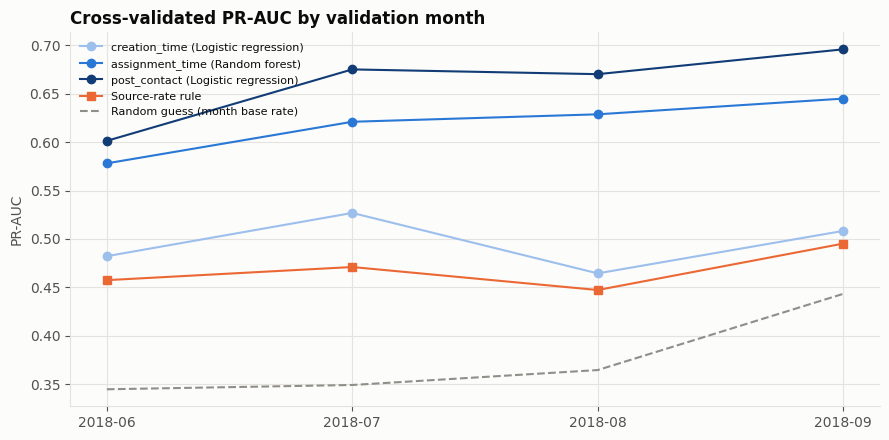

In [68]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for (fset, r), color in zip(fold_detail.items(), [BLUE_SOFT, BLUE, "#123c75"]):
    ax.plot(r["month"], r["pr_auc"], marker="o", color=color, label=f"{fset} ({frozen['sets'][fset]['model']})")
ax.plot(rule_cv["month"], rule_cv["pr_auc"], marker="s", color=ORANGE, label="Source-rate rule")
ax.plot(rule_cv["month"], rule_cv["base_rate"], ls="--", color=GRAY, label="Random guess (month base rate)")
ax.set_title("Cross-validated PR-AUC by validation month"); ax.set_ylabel("PR-AUC"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()


**Findings:**

- 48 parameter combinations were scored on four expanding-window folds. The selected configuration is:
  - `creation_time`: Logistic Regression (C=10), CV PR-AUC **0.495**, threshold 0.350
  - `assignment_time`: Random Forest (depth 4, min leaf 10), CV PR-AUC **0.618**, threshold 0.475
  - `post_contact`: Logistic Regression (C=10), CV PR-AUC **0.661**, threshold 0.414
- For comparison, random guessing scores 0.375 and the Source-rate rule 0.468 under the same folds. The creation-time model (0.495) is only 0.027 above the rule.
- For `post_contact`, Logistic Regression (0.661), Random Forest (0.660) and Gradient Boosting (0.646) are within 0.015, so the **parsimony rule picks the simplest**, Logistic Regression.
- The best C for Logistic Regression is at the edge of the grid (10), but C=1 gives 0.6606 against 0.6607 for C=10, so the choice does not matter.
- Performance improves in later folds as more training months become available (`post_contact` PR-AUC 0.601 in June to 0.696 in September), and in every fold the `assignment_time` and `post_contact` models are far above the month's base rate (for example 0.578 against 0.345 in June).
- The configuration has now been saved to `models/frozen_config.json`. **The test months have not been used yet.**


## 18. Final Evaluation on the Test Set

The configuration is frozen, so the test months can now be used, **once**. Each frozen model is refitted on all development rows (April to September) and scores October 1 to November 14. Nothing in this section changes a model, a parameter or a threshold.

Two operating points are reported, because they answer different questions:

1. **The F1-optimal threshold** chosen in cross-validation: how well the model classifies every lead.
2. **Working only the top 20% of leads by score:** how well the score prioritizes effort when time is limited.

In [69]:
test = feat[masks["test"]].reset_index(drop=True)
ytest = test["target_high"].to_numpy()
assert dev["Created"].max() < test["Created"].min()
print(f"test leads: {len(test):,} | High Potential rate: {ytest.mean():.3f} | training-period rate: {ydev.mean():.3f}")

specs = {**frozen["sets"], **frozen["handler_aware"]}
final_models, test_scores = {}, {}
for name, sp in specs.items():
    pipe = build_estimator(sp["model"], sp["params"], sp["columns"]).fit(dev[sp["columns"]], ydev)
    final_models[name] = pipe
    test_scores[name] = pipe.predict_proba(test[sp["columns"]])[:, 1]

rule = SourceRateBaseline().fit(dev[["Source_clean"]], ydev)
test_scores["Source-rate rule"] = rule.predict_proba(test[["Source_clean"]])[:, 1]
test_scores["Majority class"] = np.full(len(test), ydev.mean())
print("models scored:", list(test_scores))

test leads: 1,383 | High Potential rate: 0.456 | training-period rate: 0.367


models scored: ['creation_time', 'assignment_time', 'post_contact', 'creation_time+agent', 'assignment_time+agent', 'post_contact+agent', 'Source-rate rule', 'Majority class']


In [70]:
TOP_FRAC = 0.2
rows = []
for name, s in test_scores.items():
    m = evaluate_scores(ytest, s, TOP_FRAC)
    thr = specs.get(name, {}).get("threshold")
    t = threshold_metrics(ytest, s, thr) if thr is not None else {k: np.nan for k in ["tn", "fp", "fn", "tp", "precision", "recall", "f1", "flag_rate"]}
    rows.append({"model": name, "algorithm": specs[name]["model"] if name in specs else "-", "threshold": thr, **m, **t})
test_results = pd.DataFrame(rows)
test_results.to_csv("outputs/test_results.csv", index=False)
primary = ["Majority class", "Source-rate rule", "creation_time", "assignment_time", "post_contact"]
r = test_results.set_index("model")
pd.DataFrame({
    "algorithm": [r.loc[n, "algorithm"] for n in primary],
    "ROC-AUC (95% CI)": [f"{r.loc[n,'roc_auc']:.3f} ({r.loc[n,'roc_lo']:.3f}-{r.loc[n,'roc_hi']:.3f})" for n in primary],
    "PR-AUC (95% CI)": [f"{r.loc[n,'pr_auc']:.3f} ({r.loc[n,'pr_lo']:.3f}-{r.loc[n,'pr_hi']:.3f})" for n in primary],
}, index=primary)

,algorithm,ROC-AUC (95% CI),PR-AUC (95% CI)
Majority class,-,0.500 (0.500-0.500),0.456 (0.429-0.480)
Source-rate rule,-,0.545 (0.516-0.572),0.510 (0.474-0.540)
creation_time,Logistic regression,0.559 (0.526-0.590),0.542 (0.504-0.583)
assignment_time,Random forest,0.764 (0.739-0.789),0.713 (0.673-0.747)
post_contact,Logistic regression,0.795 (0.772-0.817),0.748 (0.707-0.781)


### 18.1 Classification Metrics at the F1-Optimal Threshold

Precision, recall and F1-score for the High Potential class, with the confusion-matrix counts, at the threshold frozen in cross-validation.

In [71]:
ladder = ["creation_time", "assignment_time", "post_contact"]
pd.DataFrame({
    "threshold": [r.loc[n, "threshold"] for n in ladder],
    "flagged as High %": [r.loc[n, "flag_rate"] * 100 for n in ladder],
    "precision": [r.loc[n, "precision"] for n in ladder],
    "recall": [r.loc[n, "recall"] for n in ladder],
    "F1": [r.loc[n, "f1"] for n in ladder],
    "TP": [r.loc[n, "tp"] for n in ladder], "FP": [r.loc[n, "fp"] for n in ladder],
    "FN": [r.loc[n, "fn"] for n in ladder], "TN": [r.loc[n, "tn"] for n in ladder],
}, index=ladder).round(3)

,threshold,flagged as High %,precision,recall,F1,TP,FP,FN,TN
creation_time,0.350,99.494,0.455,0.994,0.624,626.0,750.0,4.0,3.0
assignment_time,0.475,57.267,0.634,0.797,0.706,502.0,290.0,128.0,463.0
post_contact,0.414,64.931,0.612,0.873,0.720,550.0,348.0,80.0,405.0


### 18.2 Prioritization: Working Only the Top 20% of Leads

In [72]:
top_names = primary[1:]
pd.DataFrame({
    "precision@top20%": [r.loc[n, "precision_at_k"] for n in top_names],
    "recall@top20%": [r.loc[n, "recall_at_k"] for n in top_names],
    "lift@top20%": [r.loc[n, "lift_at_k"] for n in top_names],
}, index=top_names).round(3)

,precision@top20%,recall@top20%,lift@top20%
Source-rate rule,0.538,0.237,1.181
creation_time,0.552,0.243,1.213
assignment_time,0.744,0.327,1.633
post_contact,0.791,0.348,1.736


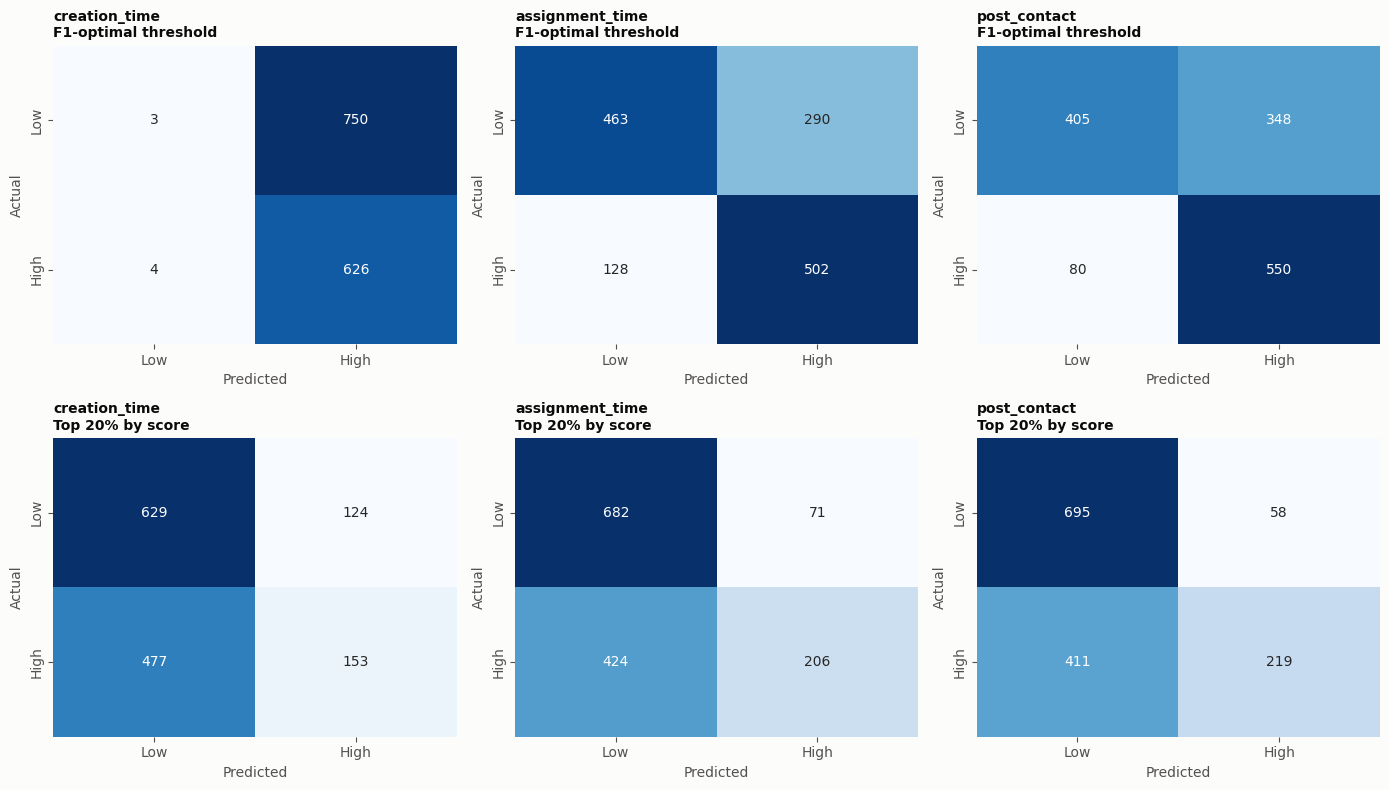

In [73]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for j, n in enumerate(ladder):
    for i, (title, flags) in enumerate([("F1-optimal threshold", (test_scores[n] >= specs[n]["threshold"]).astype(int)),
                                        ("Top 20% by score", topk_flags(test_scores[n], TOP_FRAC))]):
        cm = confusion_matrix(ytest, flags)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i, j], xticklabels=["Low", "High"], yticklabels=["Low", "High"])
        axes[i, j].set_title(f"{n}\n{title}", fontsize=10); axes[i, j].set_xlabel("Predicted"); axes[i, j].set_ylabel("Actual")
plt.tight_layout(); plt.show()


**Findings:**

On 1,383 test leads, with a High Potential rate of 45.6%:

| Model | ROC-AUC (95% CI) | PR-AUC | Lift in top 20% |
|---|---|---|---|
| Source-rate rule | 0.545 (0.516-0.572) | 0.510 | 1.18 |
| `creation_time` | 0.559 (0.526-0.590) | 0.542 | 1.21 |
| `assignment_time` | **0.764** (0.739-0.789) | 0.713 | 1.63 |
| `post_contact` | **0.795** (0.772-0.817) | 0.748 | 1.74 |

- **`creation_time` is not clearly better than the Source-rate rule:** its interval (0.526 to 0.590) overlaps the rule's (0.516 to 0.572). Time and source information alone are weak.
- **`assignment_time` and `post_contact` are clearly better** than both baselines, with intervals that do not overlap theirs. Their intervals partly overlap each other, so the gain from adding Product and email validity is not clearly proven.
- **At the frozen F1-optimal threshold** `assignment_time` flags 57.3% of leads with precision 0.634, recall 0.797 and F1 0.706; `post_contact` flags 64.9% with precision 0.612, recall 0.873 and F1 0.720.
- For `creation_time` this threshold rule **degenerates**: it flags 99.5% of leads (precision 0.455, recall 0.994), which is just "call everyone" and says nothing about usefulness. This is why the top-20% operating point is also reported.
- **Working only the top 20%** of leads gives a precision of 0.744 (`assignment_time`) and 0.791 (`post_contact`), against a base rate of 45.6%, and finds 32.7% and 34.8% of all High leads.
- The F1-optimal threshold was chosen for balanced precision and recall. A business that prefers fewer false alarms or more recall can choose another point on the precision-recall curve.


### 18.3 ROC Curves, Precision-Recall Curves and Cumulative Gains

The curves show the whole range of operating points, not only the two selected above. The cumulative-gains chart shows what share of all High leads is found when working the best-scored leads first; the diagonal is random ordering.

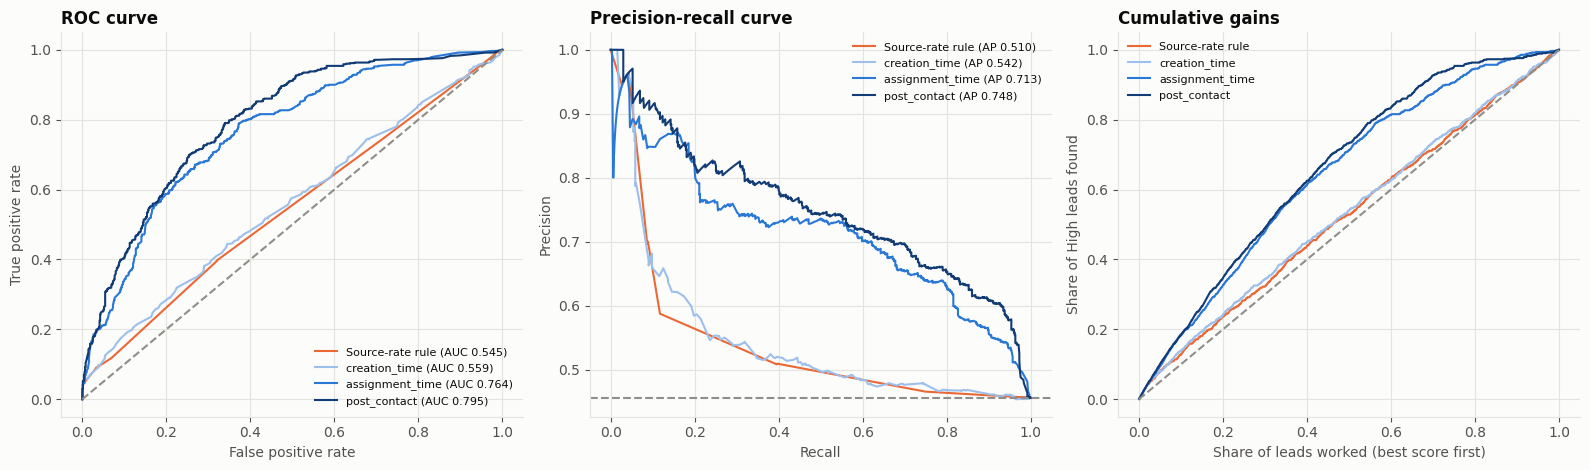

In [74]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
palette = {"Source-rate rule": ORANGE, "creation_time": BLUE_SOFT, "assignment_time": BLUE, "post_contact": "#123c75"}
for n, c in palette.items():
    fpr, tpr, _ = roc_curve(ytest, test_scores[n]); axes[0].plot(fpr, tpr, color=c, label=f"{n} (AUC {r.loc[n, 'roc_auc']:.3f})")
    p, rc, _ = precision_recall_curve(ytest, test_scores[n]); axes[1].plot(rc, p, color=c, label=f"{n} (AP {r.loc[n, 'pr_auc']:.3f})")
    order_ = _ranked_order(test_scores[n], SEED)
    gains = np.cumsum(ytest[order_]) / ytest.sum(); axes[2].plot(np.arange(1, len(ytest) + 1) / len(ytest), gains, color=c, label=n)
axes[0].plot([0, 1], [0, 1], "--", color=GRAY); axes[0].set_title("ROC curve"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[1].axhline(ytest.mean(), ls="--", color=GRAY); axes[1].set_title("Precision-recall curve"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[2].plot([0, 1], [0, 1], "--", color=GRAY); axes[2].set_title("Cumulative gains"); axes[2].set_xlabel("Share of leads worked (best score first)"); axes[2].set_ylabel("Share of High leads found")
for ax in axes: ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### 18.4 Which Fields Drive the Predictions? (Permutation Importance)

Permutation importance shuffles one field at a time on the **test** data and measures how much PR-AUC falls. A large drop means the model relies on that field. It is computed on the original columns (not the one-hot columns) so that each field has one importance.

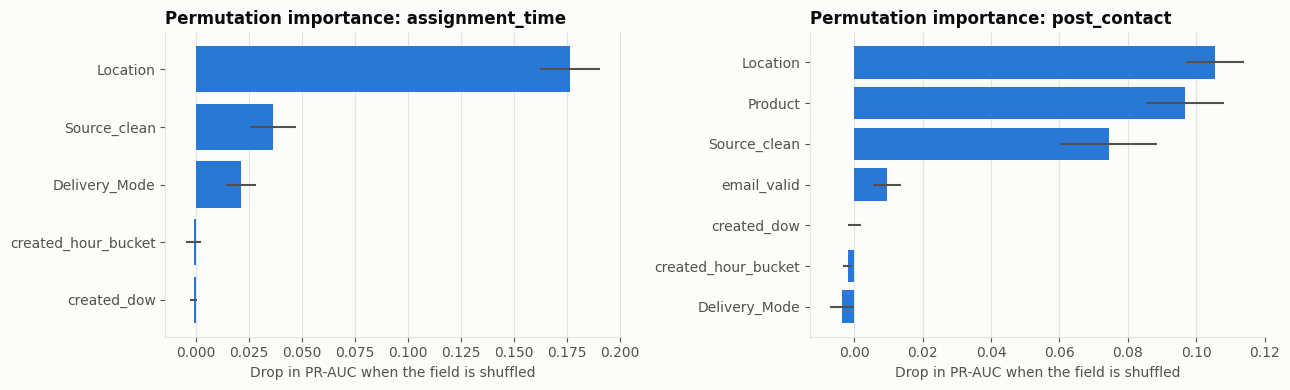

model,assignment_time,post_contact
field,,
Delivery_Mode,0.021,-0.004
Location,0.176,0.106
Product,NaN,0.097
Source_clean,0.036,0.074
created_dow,-0.001,-0.000
created_hour_bucket,-0.001,-0.002
email_valid,NaN,0.010


In [75]:
imp_rows = []
for n in ["assignment_time", "post_contact"]:
    cols = specs[n]["columns"]
    res = permutation_importance(final_models[n], test[cols], ytest, scoring="average_precision", n_repeats=15, random_state=SEED)
    for c, m, s in zip(cols, res.importances_mean, res.importances_std):
        imp_rows.append({"model": n, "field": c, "PR-AUC drop": m, "std": s})
importance = pd.DataFrame(imp_rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, n in zip(axes, ["assignment_time", "post_contact"]):
    t = importance[importance.model == n].sort_values("PR-AUC drop")
    ax.barh(t["field"], t["PR-AUC drop"], xerr=t["std"], color=BLUE, ecolor=INK2)
    ax.set_title(f"Permutation importance: {n}"); ax.set_xlabel("Drop in PR-AUC when the field is shuffled"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
importance.pivot(index="field", columns="model", values="PR-AUC drop").round(3)


**Findings:**

- **Location is the most important field** (PR-AUC drop of 0.176 in `assignment_time` and 0.106 in `post_contact`), followed by **Product** (0.097) and **Source** (0.036 and 0.074).
- Delivery Mode matters in `assignment_time` (0.021) but adds nothing once Location and Product are present in `post_contact` (-0.004).
- `email_valid` has a small effect (0.010). Hour of day and weekday are about zero.

The model's predictions rest almost entirely on *where* the lead is and *what* it wants, and very little on when it arrived. This matches the EDA and the screening.


### 18.5 Do the Scores Separate Outcomes? (Score Quintiles)

A prioritization score is only useful if leads in the top band really do better. Test leads are sorted by the `post_contact` score and split into five equal bands. For each band the table shows the High Potential rate and the **CONVERTED** rate, which is the strictest outcome.

In [76]:
qt = test[["Status", "target_high"]].copy()
qt["score"] = test_scores["post_contact"]
qt["band"] = pd.qcut(qt["score"].rank(method="first", ascending=False), 5, labels=["Q1 (top 20%)", "Q2", "Q3", "Q4", "Q5 (bottom 20%)"])
quint = qt.groupby("band", observed=True).agg(leads=("score", "size"), mean_score=("score", "mean"),
                                              high_rate=("target_high", "mean"),
                                              converted_rate=("Status", lambda s: (s == "CONVERTED").mean()),
                                              high_leads=("target_high", "sum"),
                                              converted_leads=("Status", lambda s: (s == "CONVERTED").sum()))
quint["share of all High %"] = quint["high_leads"] / quint["high_leads"].sum() * 100
quint["share of all CONVERTED %"] = quint["converted_leads"] / quint["converted_leads"].sum() * 100
quint.round(3)

,leads,mean_score,high_rate,converted_rate,high_leads,converted_leads,share of all High %,share of all CONVERTED %
band,,,,,,,,
Q1 (top 20%),277,0.763,0.791,0.177,219,49,34.762,61.25
Q2,276,0.625,0.634,0.072,175,20,27.778,25.00
Q3,277,0.515,0.477,0.036,132,10,20.952,12.50
Q4,276,0.345,0.293,0.004,81,1,12.857,1.25
Q5 (bottom 20%),277,0.081,0.083,0.000,23,0,3.651,0.00


In [77]:
top40 = quint.iloc[:2][["share of all High %", "share of all CONVERTED %"]].sum()
bottom40 = quint.iloc[3:][["share of all High %", "share of all CONVERTED %"]].sum()
print(f"Top 40% of leads hold    : {top40.iloc[0]:.1f}% of High leads and {top40.iloc[1]:.1f}% of CONVERTED leads")
print(f"Bottom 40% of leads hold : {bottom40.iloc[0]:.1f}% of High leads and {bottom40.iloc[1]:.1f}% of CONVERTED leads")
print(f"CONVERTED leads in the test months: {int(quint['converted_leads'].sum())}")
print(f"CONVERTED leads in the bottom 40%: {int(quint.iloc[3:]['converted_leads'].sum())}")

Top 40% of leads hold    : 62.5% of High leads and 86.2% of CONVERTED leads
Bottom 40% of leads hold : 16.5% of High leads and 1.2% of CONVERTED leads
CONVERTED leads in the test months: 80
CONVERTED leads in the bottom 40%: 1



**Findings:**

The score separates outcomes in a clean, monotonic way on the test months:

- The **top 20%** of leads are High Potential **79.1%** of the time and CONVERTED 17.7%; the bottom 20% are High 8.3% and never CONVERTED.
- **The top 40%** of leads hold **62.5% of all High leads and 86.2% of all CONVERTED leads**.
- **The bottom 40%** of leads hold only 16.5% of High leads and **1 of the 80 CONVERTED leads** (1.2%).

This is a retrospective ranking result. It shows that working the best-scored leads first would have reached most of the conversions, but it does not say how much revenue that would add (there is no revenue data) and it rests on only 80 CONVERTED leads with immature labels.


## 19. Robustness Checks

A single test result can depend on choices that were made along the way. Three checks show how much the conclusions depend on them. None of them changes the frozen models.

1. **Alternative target definitions.** The mapping of Status to Lead Category is an assumption, so the models are refitted under three alternatives.
2. **Each test month separately.** Does the result hold in both October and the partial November?
3. **Adding Sales_Agent.** What happens if the handler is allowed as a feature (sensitivity only)?

### 19.1 Alternative Target Definitions

Each alternative relabels the training **and** test data, refits the frozen model, and scores the test months. `CONVERTED only` is the strictest outcome (about 6% of leads).

In [78]:
alts = {
    "Open mapped to High": lambda s: s.isin(high_set | {"Open"}),
    "Long Term mapped to Low": lambda s: s.isin(high_set - {"Long Term"}),
    "CONVERTED only": lambda s: s.isin({"CONVERTED"}),
}
sens = []
for alt, fn in alts.items():
    ya_dev, ya_test = fn(dev["Status"]).astype(int).to_numpy(), fn(test["Status"]).astype(int).to_numpy()
    for name in ladder:
        sp = specs[name]
        p = build_estimator(sp["model"], sp["params"], sp["columns"]).fit(dev[sp["columns"]], ya_dev)
        s = p.predict_proba(test[sp["columns"]])[:, 1]
        tk = topk_metrics(ya_test, s, TOP_FRAC)
        sens.append({"target definition": alt, "feature_set": name, "test base rate %": ya_test.mean() * 100,
                     "ROC-AUC": roc_auc_score(ya_test, s), "PR-AUC": average_precision_score(ya_test, s), "lift@top20%": tk["lift_at_k"]})
sens = pd.DataFrame(sens)
sens.round(3)

,target definition,feature_set,test base rate %,ROC-AUC,PR-AUC,lift@top20%
0,Open mapped to High,creation_time,48.879,0.555,0.572,1.160
1,Open mapped to High,assignment_time,48.879,0.748,0.718,1.521
2,Open mapped to High,post_contact,48.879,0.783,0.749,1.610
3,Long Term mapped to Low,creation_time,42.082,0.581,0.523,1.304
4,Long Term mapped to Low,assignment_time,42.082,0.750,0.675,1.716
5,Long Term mapped to Low,post_contact,42.082,0.768,0.680,1.716
6,CONVERTED only,creation_time,5.785,0.633,0.155,1.685
7,CONVERTED only,assignment_time,5.785,0.806,0.236,2.996
8,CONVERTED only,post_contact,5.785,0.826,0.252,2.871


### 19.2 Each Test Month Separately

In [79]:
test_month = test["Created"].dt.strftime("%Y-%m").to_numpy()
pm = []
for mth in sorted(set(test_month)):
    sel = test_month == mth
    for name in ladder:
        pm.append({"month": mth, "feature_set": name, "leads": int(sel.sum()), "base rate %": ytest[sel].mean() * 100,
                   "ROC-AUC": roc_auc_score(ytest[sel], test_scores[name][sel]),
                   "PR-AUC": average_precision_score(ytest[sel], test_scores[name][sel])})
pd.DataFrame(pm).round(3)

,month,feature_set,leads,base rate %,ROC-AUC,PR-AUC
0,2018-10,creation_time,1000,45.300,0.559,0.541
1,2018-10,assignment_time,1000,45.300,0.742,0.692
2,2018-10,post_contact,1000,45.300,0.766,0.725
3,2018-11,creation_time,383,46.214,0.555,0.542
4,2018-11,assignment_time,383,46.214,0.818,0.772
5,2018-11,post_contact,383,46.214,0.865,0.817


### 19.3 Sensitivity: Adding Sales_Agent

The handler is added to each feature set, keeping the same algorithm and parameters. Because agents were routed partly by segment and the Status is entered by the agent, this is **not** used for headline results.

In [80]:
rows = []
for name in ladder:
    for variant in [name, f"{name}+agent"]:
        m = evaluate_scores(ytest, test_scores[variant], TOP_FRAC)
        rows.append({"feature_set": name, "with Sales_Agent": variant.endswith("+agent"), "ROC-AUC": m["roc_auc"],
                     "PR-AUC": m["pr_auc"], "lift@top20%": m["lift_at_k"]})
pd.DataFrame(rows).round(3)

,feature_set,with Sales_Agent,ROC-AUC,PR-AUC,lift@top20%
0,creation_time,False,0.559,0.542,1.213
1,creation_time,True,0.616,0.592,1.434
2,assignment_time,False,0.764,0.713,1.633
3,assignment_time,True,0.776,0.735,1.728
4,post_contact,False,0.795,0.748,1.736
5,post_contact,True,0.809,0.764,1.744



**Findings:**

- **Alternative targets:** the ranking is stable. For `post_contact` the ROC-AUC is 0.783 when `Open` is counted as High, 0.768 when `Long Term` is counted as Low, and 0.826 for CONVERTED only. The order of the three feature sets is the same in every case.
- **The strict CONVERTED-only target** (5.8% of test leads) gives larger lifts: **3.00** for `assignment_time` and 2.87 for `post_contact` in the top 20%.
- **By month:** the result holds in both test months: `post_contact` ROC-AUC is 0.766 in October (1,000 leads) and 0.865 in the partial November (383 leads). `creation_time` stays weak in both (0.559 and 0.555).
- **Adding Sales_Agent** raises scores mostly for the weak creation-time set (ROC-AUC 0.559 → 0.616), where the agent partly stands in for segment, and only a little for the others (0.764 → 0.776 and 0.795 → 0.809). Because routing and labels are agent-related, these stay as sensitivity results.


## 20. Error Analysis

Metrics say how often the model is wrong, not **where** or **why**. This section examines the errors of the `post_contact` model at its frozen threshold, in the same spirit as a misclassification review:

1. How do scores differ across the ten Status values?
2. In which segments are errors concentrated?
3. What do the most confident mistakes look like?

In [81]:
err = test[["lead_id", "Status", "target_high", "Location", "Product", "Source_clean", "Delivery_Mode"]].copy()
err["score"] = test_scores["post_contact"]
err["flagged_high"] = (err["score"] >= specs["post_contact"]["threshold"]).astype(int)
err["error"] = (err["flagged_high"] != err["target_high"]).astype(int)
err["error_type"] = np.select([(err.flagged_high == 1) & (err.target_high == 0), (err.flagged_high == 0) & (err.target_high == 1)],
                              ["false positive", "false negative"], default="correct")
by_status = err.groupby("Status").agg(leads=("score", "size"), mean_score=("score", "mean"), flagged_high_pct=("flagged_high", lambda s: s.mean() * 100)) \
              .sort_values("mean_score", ascending=False)
by_status["actual category"] = ["High" if s in high_set else "Low" for s in by_status.index]
by_status.round(3)

,leads,mean_score,flagged_high_pct,actual category
Status,,,,
CONVERTED,80,0.728,98.750,High
Potential,233,0.605,87.983,High
Long Term,48,0.577,89.583,High
In Progress Positive,269,0.565,82.900,High
LOST,13,0.515,76.923,Low
In Progress Negative,66,0.419,57.576,Low
Just Enquiry,207,0.386,55.072,Low
Not Responding,237,0.373,49.789,Low
Junk Lead,184,0.282,35.326,Low


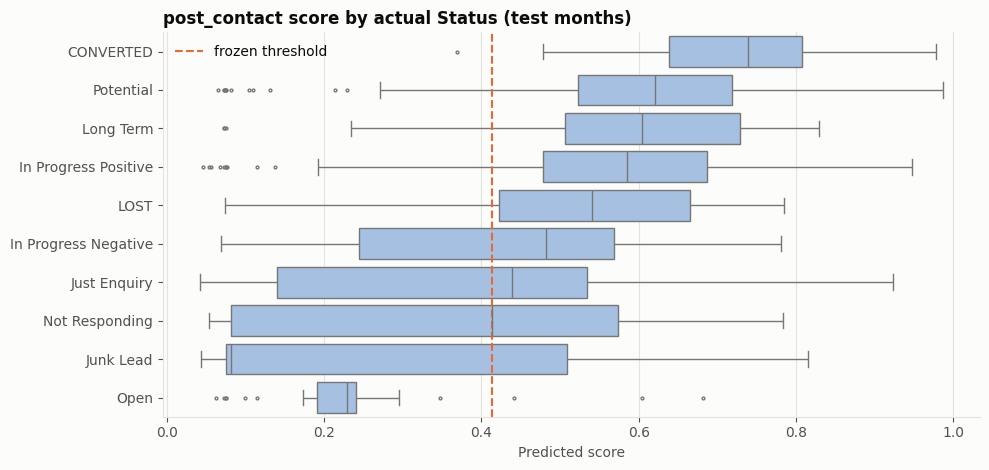

In [82]:
fig, ax = plt.subplots(figsize=(10, 4.8))
order_ = by_status.index.tolist()
sns.boxplot(data=err, y="Status", x="score", order=order_, color=BLUE_SOFT, fliersize=2, ax=ax)
ax.axvline(specs["post_contact"]["threshold"], color=ORANGE, ls="--", label="frozen threshold")
ax.set_title("post_contact score by actual Status (test months)"); ax.set_xlabel("Predicted score"); ax.set_ylabel(""); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

In [83]:
print(err["error_type"].value_counts().to_string())
print()
seg_rows = []
for col in ["Location", "Product", "Delivery_Mode", "Source_clean"]:
    g = err.groupby(col).agg(leads=("error", "size"), errors=("error", "sum"), fp=("error_type", lambda s: (s == "false positive").sum()),
                             fn=("error_type", lambda s: (s == "false negative").sum()))
    g["error rate %"] = g["errors"] / g["leads"] * 100
    g.insert(0, "field", col)
    seg_rows.append(g[g["leads"] >= 50].sort_values("errors", ascending=False).head(4).reset_index().rename(columns={col: "segment"}))
pd.concat(seg_rows).round(1)

error_type
correct           955
false positive    348
false negative     80



,segment,field,leads,errors,fp,fn,error rate %
0,Other Locations,Location,498,139,85,54,27.9
1,Bangalore,Location,350,89,84,5,25.4
2,Chennai,Location,170,46,44,2,27.1
3,Hyderabad,Location,90,41,39,2,45.6
0,P18,Product,358,131,120,11,36.6
1,P19,Product,225,89,87,2,39.6
2,P9,Product,173,62,52,10,35.8
3,P27,Product,134,56,48,8,41.8
0,Mode-3,Delivery_Mode,368,173,150,23,47.0
1,Mode-1,Delivery_Mode,491,149,135,14,30.3


In [84]:
conf_fp = err[err.target_high == 0].nlargest(100, "score")
conf_fn = err[err.target_high == 1].nsmallest(100, "score")
print("Statuses of the 100 highest-scored LOW Potential leads (most confident false alarms):")
print(conf_fp["Status"].value_counts().to_string())
print()
print("Statuses of the 100 lowest-scored HIGH Potential leads (most confident misses):")
print(conf_fn["Status"].value_counts().to_string())

Statuses of the 100 highest-scored LOW Potential leads (most confident false alarms):
Status
Not Responding          37
Just Enquiry            28
Junk Lead               20
In Progress Negative    10
LOST                     4
Open                     1

Statuses of the 100 lowest-scored HIGH Potential leads (most confident misses):
Status
In Progress Positive    56
Potential               37
Long Term                6
CONVERTED                1



**Findings:**

**Scores follow the status ordering.** CONVERTED leads have the highest mean score (0.728, 98.8% flagged as High), followed by `Potential` (0.605), `Long Term` (0.577) and `In Progress Positive` (0.565). Among Low statuses, `Open` (0.234) and `Junk Lead` (0.282) are lowest. `LOST` (0.515) is scored like a High lead: leads that engage and are then lost look like good leads in terms of segment.

**Errors:** 955 leads are classified correctly, with **348 false positives and 80 false negatives**. The model errs on the side of flagging, as the F1-optimal threshold favours recall.

**Where errors concentrate:**
- Highest error rates: `Mode-3` (47.0%), `Hyderabad` (45.6%), `Live Chat-Direct` (42.0%) and `P27` (41.8%). Lowest: `Call` (19.5%) and `Mode-5` (19.7%).
- In segments such as `Bangalore` and `Chennai`, nearly all errors are false positives (84 of 89 and 44 of 46): good segments contain many leads that did not engage.

**What the confident mistakes are:**
- Of the 100 highest-scored Low leads, 85 are `Not Responding`, `Just Enquiry` or `Junk Lead`: leads that look good by segment but did not engage. Segment information cannot tell who will respond.
- Of the 100 lowest-scored High leads, 93 are `In Progress Positive` or `Potential` and only 1 is `CONVERTED`. The misses are mostly **in-progress leads**, which fits the label-maturity effect: their final status is not known yet.

The model finds good *segments*, not individual intent. Adding information on the customer's behaviour in the conversation would be the next improvement.


## 21. Sales Agent Comparison (Segment-Adjusted)

A raw comparison of agents is unfair because leads were **routed by delivery mode and location** and the mix of segments differs between agents. This section compares each agent only with **other agents handling leads in the same segment and month**.

- Each lead is compared with the High Potential rate of *other* agents' leads in the same Delivery_Mode × Location × month stratum (leave-agent-out), so an agent is never compared with their own results.
- The agent's gap is the observed High rate minus the rate expected from those peers, in percentage points, with a 95% bootstrap interval.
- Strata with fewer than 20 peer leads are excluded and counted, not guessed, and agents with fewer than 30 comparable leads get no estimate.
- Only development months (April to September) are used.

**What this can and cannot say:** a positive gap means the agent's leads reached High Potential more often than comparable leads handled by others. It does not separate better selling from a different habit of recording Status, and it only adjusts for mode, location and month.

In [85]:
def adjusted_agent_gaps(df, strata, agent="Sales_Agent", target="target_high", min_peer_leads=20, n_boot=500, seed=SEED):
    """Leave-agent-out indirect standardization of High rate within strata, with bootstrap intervals."""
    d = df.dropna(subset=[agent]).copy()
    g_all = d.groupby(strata)[target].agg(S="sum", N="size")
    g_agent = d.groupby(strata + [agent])[target].agg(s="sum", n="size")
    d = d.join(g_all, on=strata).join(g_agent, on=strata + [agent])
    d["peer_n"] = d["N"] - d["n"]
    d["expected"] = np.where(d["peer_n"] >= min_peer_leads, (d["S"] - d["s"]) / d["peer_n"].where(d["peer_n"] > 0), np.nan)
    rng = np.random.default_rng(seed)
    rows = []
    for a, sub in d.groupby(agent):
        comp = sub.dropna(subset=["expected"])
        row = {"agent": a, "n_leads": len(sub), "n_comparable": len(comp), "comparable_%": len(comp) / len(sub) * 100,
               "unadjusted_high_%": sub[target].mean() * 100}
        if len(comp) >= 30:
            y_, e_ = comp[target].to_numpy(), comp["expected"].to_numpy()
            boots = [(y_[b] - e_[b]).mean() * 100 for b in (rng.integers(0, len(y_), len(y_)) for _ in range(n_boot))]
            lo, hi = np.percentile(boots, [2.5, 97.5])
            row.update({"observed_%": y_.mean() * 100, "expected_%": e_.mean() * 100, "gap_pp": (y_ - e_).mean() * 100, "gap_lo": lo, "gap_hi": hi})
        else:
            row.update({"observed_%": np.nan, "expected_%": np.nan, "gap_pp": np.nan, "gap_lo": np.nan, "gap_hi": np.nan})
        rows.append(row)
    return pd.DataFrame(rows).sort_values("n_leads", ascending=False).reset_index(drop=True)


dev_agents = data[data["Created"] <= CFG["val_end"]].copy()
strata = ["Mode_g", "Location_g", "month"]
gaps_all = adjusted_agent_gaps(dev_agents, strata)
agent_cols = ["agent", "n_leads", "n_comparable", "comparable_%", "unadjusted_high_%", "observed_%", "expected_%", "gap_pp", "gap_lo", "gap_hi"]
gaps_all[agent_cols].round(1)

,agent,n_leads,n_comparable,comparable_%,unadjusted_high_%,observed_%,expected_%,gap_pp,gap_lo,gap_hi
0,Sales-Agent-4,1255,981,78.2,33.6,31.4,29.4,2.0,-0.7,4.4
1,Sales-Agent-11,1203,961,79.9,32.3,31.6,25.1,6.5,3.7,9.6
2,Sales-Agent-5,1149,830,72.2,25.5,22.2,31.5,-9.4,-11.9,-6.6
3,Sales-Agent-9,589,541,91.9,63.8,63.6,44.4,19.2,15.6,22.6
4,Sales-Agent-3,536,477,89.0,38.1,36.5,45.5,-9.1,-13.5,-4.9
5,Sales-Agent-7,484,420,86.8,42.6,42.6,47.9,-5.3,-10.2,-0.6
6,Sales-Agent-2,362,324,89.5,46.4,47.2,45.5,1.7,-3.2,6.6
7,Sales-Agent-12,269,224,83.3,30.5,25.4,42.1,-16.7,-22.1,-11.0
8,Sales-Agent-6,114,88,77.2,52.6,50.0,40.4,9.6,-0.5,19.6
9,Sales-Agent-8,44,38,86.4,40.9,39.5,33.3,6.2,-8.0,21.7


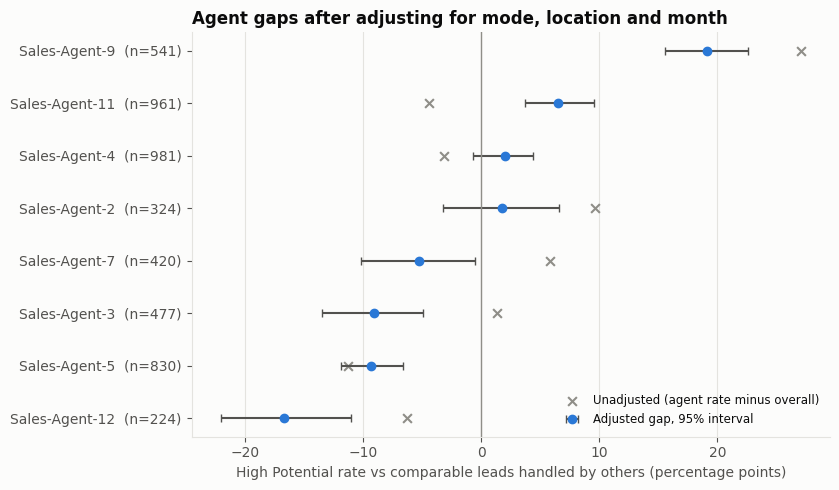

In [86]:
fig, ax = plt.subplots(figsize=(8.5, 5))
p = gaps_all[gaps_all.n_comparable >= 150].dropna(subset=["gap_pp"]).sort_values("gap_pp")
y_pos = np.arange(len(p))
ax.errorbar(p.gap_pp, y_pos, xerr=[p.gap_pp - p.gap_lo, p.gap_hi - p.gap_pp], fmt="o", color=BLUE, ecolor=INK2, capsize=3, ms=6, label="Adjusted gap, 95% interval")
ax.scatter(p["unadjusted_high_%"] - dev_agents.target_high.mean() * 100, y_pos, marker="x", color=GRAY, s=40, label="Unadjusted (agent rate minus overall)")
ax.axvline(0, color=GRAY, lw=1); ax.set_yticks(y_pos); ax.set_yticklabels([f"{a}  (n={int(n):,})" for a, n in zip(p.agent, p.n_comparable)])
ax.set_xlabel("High Potential rate vs comparable leads handled by others (percentage points)")
ax.set_title("Agent gaps after adjusting for mode, location and month"); ax.grid(axis="y", visible=False); ax.legend(frameon=False, fontsize=8.5, loc="lower right")
plt.tight_layout(); plt.show()

### 21.1 Robustness: Does One Strong Agent Distort the Others?

Gaps are measured against peers, so a very strong agent raises everyone else's benchmark. The largest positive outlier is removed from the peer pool and the gaps are recomputed. September alone is also shown, because assignment looked closer to random then.

In [87]:
top_agent = gaps_all.dropna(subset=["gap_pp"]).sort_values("gap_pp").iloc[-1]["agent"]
gaps_no_top = adjusted_agent_gaps(dev_agents[dev_agents.Sales_Agent != top_agent], strata)
gaps_sep = adjusted_agent_gaps(dev_agents[dev_agents.month == "2018-09"], strata)
print("largest positive outlier removed from the peer pool:", top_agent)
display(gaps_no_top[agent_cols].round(1))
print("September only:")
gaps_sep[agent_cols].round(1)

largest positive outlier removed from the peer pool: Sales-Agent-9


,agent,n_leads,n_comparable,comparable_%,unadjusted_high_%,observed_%,expected_%,gap_pp,gap_lo,gap_hi
0,Sales-Agent-4,1255,970,77.3,33.6,30.7,27.4,3.3,0.7,5.9
1,Sales-Agent-11,1203,931,77.4,32.3,31.7,24.0,7.7,5.2,10.5
2,Sales-Agent-5,1149,808,70.3,25.5,22.0,29.7,-7.7,-10.1,-4.8
3,Sales-Agent-3,536,474,88.4,38.1,36.5,41.8,-5.3,-9.5,-0.9
4,Sales-Agent-7,484,413,85.3,42.6,42.9,44.2,-1.3,-6.6,3.1
5,Sales-Agent-2,362,316,87.3,46.4,47.8,41.8,6.0,1.2,11.3
6,Sales-Agent-12,269,223,82.9,30.5,25.6,39.1,-13.5,-19.1,-7.8
7,Sales-Agent-6,114,88,77.2,52.6,50.0,36.3,13.7,3.5,23.7
8,Sales-Agent-8,44,38,86.4,40.9,39.5,31.8,7.7,-6.3,23.2
9,Sales-Agent-10,16,3,18.8,0.0,NaN,NaN,NaN,NaN,NaN


September only:


,agent,n_leads,n_comparable,comparable_%,unadjusted_high_%,observed_%,expected_%,gap_pp,gap_lo,gap_hi
0,Sales-Agent-5,207,182,87.9,30.4,30.8,43.3,-12.5,-18.4,-6.5
1,Sales-Agent-4,184,158,85.9,50.0,48.1,41.9,6.2,-0.3,12.9
2,Sales-Agent-9,174,158,90.8,66.1,64.6,47.8,16.8,10.2,23.0
3,Sales-Agent-11,170,154,90.6,38.2,36.4,38.4,-2.0,-9.1,5.0
4,Sales-Agent-7,137,120,87.6,48.9,50.8,45.3,5.6,-2.9,14.4
5,Sales-Agent-3,132,124,93.9,35.6,35.5,46.3,-10.8,-18.9,-2.5
6,Sales-Agent-2,78,66,84.6,42.3,42.4,46.3,-3.9,-13.4,6.1
7,Sales-Agent-12,11,9,81.8,18.2,NaN,NaN,NaN,NaN,NaN
8,Sales-Agent-8,8,8,100.0,50.0,NaN,NaN,NaN,NaN,NaN


In [88]:
def clear_gaps(t):
    t = t.dropna(subset=["gap_pp"])
    return t[(t.gap_lo > 0) | (t.gap_hi < 0)]


c1, c2 = clear_gaps(gaps_all), clear_gaps(gaps_no_top)
robust = sorted(set(c1.agent) & set(c2.agent))
print("Intervals excluding zero, all agents      :", ", ".join(f"{r.agent} ({r.gap_pp:+.1f})" for r in c1.itertuples()))
print("Intervals excluding zero, top agent out   :", ", ".join(f"{r.agent} ({r.gap_pp:+.1f})" for r in c2.itertuples()))
print("Present in both runs                      :", ", ".join(robust))
print(f"Share of leads with a comparable peer group: {gaps_all.n_comparable.sum() / gaps_all.n_leads.sum() * 100:.0f}%")

Intervals excluding zero, all agents      : Sales-Agent-11 (+6.5), Sales-Agent-5 (-9.4), Sales-Agent-9 (+19.2), Sales-Agent-3 (-9.1), Sales-Agent-7 (-5.3), Sales-Agent-12 (-16.7)
Intervals excluding zero, top agent out   : Sales-Agent-4 (+3.3), Sales-Agent-11 (+7.7), Sales-Agent-5 (-7.7), Sales-Agent-3 (-5.3), Sales-Agent-2 (+6.0), Sales-Agent-12 (-13.5), Sales-Agent-6 (+13.7)
Present in both runs                      : Sales-Agent-11, Sales-Agent-12, Sales-Agent-3, Sales-Agent-5
Share of leads with a comparable peer group: 81%



**Findings:**

After adjusting for delivery mode, location and month (81% of leads have a comparable peer group):

- **Above peers:** `Sales-Agent-11` (+6.5 points, interval +3.7 to +9.6) and `Sales-Agent-9` (+19.2, +15.6 to +22.6).
- **Below peers:** `Sales-Agent-5` (-9.4), `Sales-Agent-3` (-9.1), `Sales-Agent-12` (-16.7) and `Sales-Agent-7` (-5.3), all with intervals that exclude zero.
- **Not distinguishable from peers:** `Sales-Agent-4`, `Sales-Agent-2`, `Sales-Agent-6` and `Sales-Agent-8`.
- The raw numbers overstate several differences: in the development months Agent 5's raw rate is 25.5% but the adjusted gap is -9.4 points, because part of the raw gap came from the segments Agent 5 was routed.

**Robustness:** removing the largest outlier (`Sales-Agent-9`) from the peer pool shifts the others by a few points. Four agents remain clearly different in both runs: `Sales-Agent-11` (above), and `Sales-Agent-12`, `Sales-Agent-3` and `Sales-Agent-5` (below). `Sales-Agent-4`, `-2` and `-6` appear above peers only when Agent 9 is removed, and `Sales-Agent-7` loses its significance, so those are not stable. September alone gives smaller samples with mostly wider intervals.

**What this does not mean:** a gap is not a performance ranking. The Status is entered by the agent, so a gap can reflect recording habits as much as selling, and agents may differ in ways that mode, location and month do not capture. The recommendation is a **label audit before any coaching or staffing decision**.


## 22. Business Recommendations

The recommendations below follow from the evidence computed earlier in this notebook. Each one states how strong the evidence is and what would change it. **The dataset has no revenue, deal value, cost or rep-hours, so no monetary impact is claimed.** Where a benefit is measured, it is a retrospective ranking result on historical leads and not a forecast.

Before the recommendations, one more piece of evidence is computed: how much of the benefit can be obtained **without any model**, using a simple rule. The rule (Product P15 or Location "Other Locations") was chosen from the EDA on development data and is applied unchanged to the test months.

In [89]:
def low_segment(d):
    return (d["Product"] == "P15") | (d["Location"] == "Other Locations")


rows = []
for label, d in [("development (Apr-Sep)", dev), ("test (Oct-Nov)", test)]:
    flag = low_segment(d)
    f, g = d[flag], d[~flag]
    rows.append({"period": label, "flagged % of leads": flag.mean() * 100, "High % (flagged)": f["target_high"].mean() * 100,
                 "High % (not flagged)": g["target_high"].mean() * 100,
                 "share of all High in flagged %": f["target_high"].sum() / d["target_high"].sum() * 100,
                 "CONVERTED % (flagged)": (f["Status"] == "CONVERTED").mean() * 100,
                 "share of all CONVERTED in flagged %": (f["Status"] == "CONVERTED").sum() / (d["Status"] == "CONVERTED").sum() * 100})
pd.DataFrame(rows).round(1)

,period,flagged % of leads,High % (flagged),High % (not flagged),share of all High in flagged %,CONVERTED % (flagged),share of all CONVERTED in flagged %
0,development (Apr-Sep),35.7,15.1,48.8,14.6,3.6,10.1
1,test (Oct-Nov),37.5,22.2,59.6,18.3,1.0,6.2



**Findings:**

A rule with no model at all, "Product P15 or Location Other Locations", flags 37.5% of test leads. Those leads are High Potential only **22.2%** of the time, against **59.6%** for the other leads, and they hold 18.3% of all High leads and only 6.2% of all CONVERTED leads (their CONVERTED rate is 1.0%). The pattern was almost the same in the development months (35.7% flagged; 15.1% vs 48.8% High), so it was stable.

This simple rule captures part of the benefit with no model, and is the natural fallback if the model is not adopted.


### 22.1 Recommendations

| # | Recommendation | Evidence in this notebook | Confidence | What would change it |
|---|---|---|---|---|
| 1 | **Confirm and document when each field is captured** (customer order form vs rep entry). Make Location, Delivery_Mode and Product capture mandatory at the order form if they are not already. | Location and Product carry almost all the signal (section 18.4); creation-time-only features barely beat a source lookup (section 14, 18). | High that it matters; unknown which fields are early | The owner's answer. If these fields are entered after contact, only the weak creation-time model applies at first touch. |
| 2 | **Run a score-assisted prioritization pilot** (section 23) instead of rolling the model out. | Working the top 40% by score reaches the shares of High and CONVERTED leads shown in 18.5, with the bottom 40% holding very few CONVERTED leads. | Medium | Only 80 CONVERTED leads in the test window, immature labels, one window, clustered leads. |
| 3 | **Investigate the low-yield segment before automating anything** (Product 15, "Other Locations", Mode-5). | Section 10.8 and the segment rule in section 22. | High that the pattern exists; unknown why | What these segments are (non-target geography, support requests, spam, a form default). |
| 4 | **Replace the catch-all "Other Locations" with real values** at capture. | About a third of all leads sit in it (section 10.7). | High (data quality) | n/a |
| 5 | **Protect referral and existing-client channels; audit US Website.** | Section 10.5: referral, existing-client and recommendation sources have very high High rates (small n), and US Website has almost none. | Medium (referred and existing customers are high-intent by nature, so this does not show a referral program would create more) | Traffic-quality review for US Website; a proper test for any referral program. |
| 6 | **Review lead routing and, separately, audit Status labels by agent.** | Section 21: several agents differ from comparable peers, and four remain after removing the largest outlier. | Medium (the label is agent-entered) | A label audit (sampled outcomes verified independently) before any coaching or staffing decision. Not a performance ranking. |
| 7 | **Record status-change timestamps and replace placeholder contact identifiers.** | Label maturity (section 10.6) and identifier quality (section 10.11). | High | n/a |

**The label-maturity problem (why recommendation 7 comes first).** Statuses mature as leads age: CONVERTED falls from 16.0% of May leads to 3.7% of November leads, while Potential + In Progress Positive rises from 6.5% to 42.3% (section 10.6). The working High Potential label counts those in-flight states as High, so **the rising High rate is partly unresolved leads, not better leads**. Model rankings stayed strong on later months, but any claim about conversions needs outcomes measured at a fixed lead age.

## 23. Proposed Pilot: Score-Assisted Lead Prioritization

### 23.1 Preconditions

1. The owner confirms the capture time of Location, Delivery_Mode, Product and email. This decides which model can run at first touch (`creation_time`, `assignment_time` or `post_contact`).
2. Status-change timestamps are logged, and a maturity window is chosen from them (unknown today; do not assume one).
3. Deal value and rep time are available, so outcomes can be valued. Without them the pilot reports counts only.

### 23.2 Phase A: Shadow Mode (about 6 to 8 weeks)

Score every new lead when its fields are captured and store the score and timestamp. Reps see nothing and work as today. After leads mature, compare scores with realized outcomes.

- **Checks:** ROC-AUC and PR-AUC with intervals; High and CONVERTED rates by score quintile; share of CONVERTED leads found in the bottom 40%; score drift versus the training period.
- **Proposed go/no-go (to be agreed with the business first):** the top-quintile CONVERTED rate with an interval clearly above the overall rate, and the bottom 40% holding a small minority of CONVERTED leads. The retrospective reference values are in section 18.5.

### 23.3 Phase B: Randomized Process Pilot (about 8 to 12 weeks, only if Phase A passes)

- **Unit and assignment:** lead-level randomization, stratified by agent and week, 50/50. Randomizing within agent removes the routing confound.
- **Treatment:** the call queue is ordered by score; leads in the bottom 40% get a lower-touch path (for example automated nurture with a manual override). **Control:** current practice.
- **Primary metric (recommended):** share of top-quintile leads receiving a first contact within a set time. It is a leading indicator that the process actually changed.
- **Secondary:** CONVERTED rate and High Potential rate at the fixed maturity age; rep contacts per CONVERTED lead (if rep effort is logged).
- **Guardrails:** CONVERTED count among bottom-40% leads must not fall versus control (non-inferiority margin agreed in advance); rep override rate; periodic independent audit of a sample of recorded statuses, because agents enter them and treatment could change how they label.

### 23.4 Why Conversion Is Not the Primary Metric

The sample sizes below use the test-period baselines and lead volume, two-sided alpha 0.05, 80% power and a normal approximation, with leads assumed independent. They are therefore **lower bounds**; real leads are clustered by contact and agent. This is planning arithmetic under stated assumptions, not a result.

In [90]:
def n_per_arm(p1, p2, alpha=0.05, power=0.8):
    """Two-sided two-proportion z-test sample size per arm (normal approximation, no clustering)."""
    za, zb = norm.ppf(1 - alpha / 2), norm.ppf(power)
    pbar = (p1 + p2) / 2
    num = (za * np.sqrt(2 * pbar * (1 - pbar)) + zb * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2
    return int(np.ceil(num / (p1 - p2) ** 2))


days = (test["Created"].max().normalize() - test["Created"].min().normalize()).days + 1
leads_per_week = len(test) / days * 7
p_conv = (test["Status"] == "CONVERTED").mean()
p_high = test["target_high"].mean()
print(f"test period: {len(test):,} leads over {days} days = {leads_per_week:.0f} leads per week")
print(f"baseline CONVERTED rate {p_conv * 100:.1f}% | baseline High Potential rate {p_high * 100:.1f}%")

plan = []
for label, p1, uplifts in [("CONVERTED rate", p_conv, [("+20% relative", p_conv * 1.2), ("+30% relative", p_conv * 1.3), ("+50% relative", p_conv * 1.5)]),
                           ("High Potential rate", p_high, [("+3 pp", p_high + .03), ("+5 pp", p_high + .05), ("+8 pp", p_high + .08)])]:
    for lab, p2 in uplifts:
        n = n_per_arm(p1, p2)
        plan.append({"outcome": label, "baseline %": p1 * 100, "target effect": lab, "target %": p2 * 100,
                     "leads per arm": n, "weeks at 50/50 split": 2 * n / leads_per_week})
sample_plan = pd.DataFrame(plan)
sample_plan.round(1)

test period: 1,383 leads over 45 days = 215 leads per week
baseline CONVERTED rate 5.8% | baseline High Potential rate 45.6%


,outcome,baseline %,target effect,target %,leads per arm,weeks at 50/50 split
0,CONVERTED rate,5.8,+20% relative,6.9,6987,65.0
1,CONVERTED rate,5.8,+30% relative,7.5,3236,30.1
2,CONVERTED rate,5.8,+50% relative,8.7,1258,11.7
3,High Potential rate,45.6,+3 pp,48.6,4345,40.4
4,High Potential rate,45.6,+5 pp,50.6,1567,14.6
5,High Potential rate,45.6,+8 pp,53.6,612,5.7



**Findings:**

At about **215 leads per week**, a conversion-powered test of a realistic effect takes a long time:

- A **+30% relative** increase in the CONVERTED rate (5.8% → 7.5%) needs about **3,236 leads per arm**, roughly **30 weeks**; +20% needs 6,987 per arm (about 65 weeks); only a large +50% effect is detectable in about 12 weeks (1,258 per arm).
- For the High Potential rate, +8 points needs 612 per arm (5.7 weeks) and +5 points 1,567 per arm (14.6 weeks).
- These are lower bounds, because the calculation treats leads as independent, and the time for outcomes to mature must be added.

**This is why a process metric is the primary metric** (whether top-scored leads are actually contacted faster), with the CONVERTED rate as a secondary measure with a non-inferiority guardrail, and an option to extend the pilot if the business wants a conversion read.


### 23.5 Risks and Mitigations

| Risk | Mitigation |
|---|---|
| Fields are filled after contact, so the model restates the outcome | Precondition 1; use the `creation_time` or `assignment_time` model if the timing demands it |
| Low-score leads are neglected and some would have converted | Bottom-40% path is lower-touch, not dropped; non-inferiority guardrail; manual override |
| Agents change how they record Status under treatment | Randomize within agent; audit sampled statuses against an independent record |
| Model drifts as the product mix or routing changes | Shadow-phase drift checks; quarterly retraining on matured leads; keep the simple segment rule as a fallback |
| Immature labels distort evaluation | Fixed maturity window and status-change timestamps |
| Bias against segments (for example a location) | Review score distributions by location and product with the business before launch; use scores to prioritize, not to refuse service |

**Decision rule at the end of Phase B:** scale up only if the primary metric shows the process changed, the guardrails hold, and the secondary conversion read is not worse than control. If the data is inconclusive, extend Phase B or fall back to the segment rule, which captures part of the benefit with no model.

## 24. Power BI Dashboard

The brief asks for a Power BI dashboard. Power BI Desktop is not available in this environment, so this section **prepares the data and the specification** and does not claim a finished `.pbix` file:

1. A PII-free **star schema** is exported to CSV (`fact_leads`, `dim_status`, `fact_scores`, `agent_gaps`). Every export passes a guard that rejects personal-data columns and email- or phone-like values.
2. The **expected KPI values** are computed here in pandas, so every card in the dashboard can be checked against a known number.
3. The **DAX measures** and the dashboard design are specified below.

**The DAX has not been executed.** Validate each measure against the expected values before use.

The exported files are row-level data derived from customer records and are written to a local `powerbi/data` folder. **Do not publish or commit them.**

In [91]:
def assert_no_pii(df):
    """Raise if a frame about to be exported has PII-bearing columns or email-like / long-digit values."""
    banned = {"mobile", "email", "contact_key", "phone"}
    hit = [c for c in df.columns if c.lower() in banned]
    if hit:
        raise ValueError(f"PII columns present: {hit}")
    for col in df.select_dtypes(include=["object", "string"]).columns:
        s = df[col].dropna().astype(str)
        if s.str.contains("@", regex=False).any() or s.str.contains(r"\d{9,}", regex=True).any():
            raise ValueError(f"Email- or phone-like values in column {col!r}")


# dim_status: one row per status, with the category and KPI flags generated from the configuration
statuses = CFG["high_potential"] + CFG["low_potential"]
dim_status = pd.DataFrame({
    "status": statuses,
    "lead_category": ["High Potential" if s in high_set else "Low Potential" for s in statuses],
    "is_converted": [int(s in CFG["kpi"]["converted"]) for s in statuses],
    "is_no_engagement": [int(s in CFG["kpi"]["no_engagement"]) for s in statuses],
    "is_unresolved": [int(s in CFG["kpi"]["unresolved"]) for s in statuses],
    "sort_order": range(1, len(statuses) + 1),
})

split_label = np.select([masks["train"], masks["val"], masks["test"]], ["train", "validation", "test"], default="unassigned")
fact_leads = pd.DataFrame({
    "lead_id": feat["lead_id"], "created_at": feat["Created"].dt.strftime("%Y-%m-%d %H:%M:%S"),
    "created_date": feat["Created"].dt.strftime("%Y-%m-%d"), "month_start": feat["Created"].dt.to_period("M").dt.start_time.dt.strftime("%Y-%m-%d"),
    "source_raw": feat["Source"].fillna(MISSING), "source_group": feat["Source_clean"].fillna(MISSING),
    "product": feat["Product"].fillna(MISSING), "location": feat["Location"].fillna(MISSING),
    "delivery_mode": feat["Delivery_Mode"], "sales_agent": feat["Sales_Agent"].fillna(MISSING),
    "status": feat["Status"], "split": split_label,
})
assert set(fact_leads["status"]) <= set(dim_status["status"]), "a status is missing from dim_status"
print("fact_leads:", fact_leads.shape, "| dim_status:", dim_status.shape)

fact_leads: (7422, 12) | dim_status: (10, 6)


### 24.1 Out-of-Time Scores for the Dashboard

Scores shown in a dashboard must never be in-sample, otherwise the dashboard would overstate model quality. Every score exported here comes from a model that never saw that lead's own month or any later month:

- **June to September leads:** the out-of-fold predictions from the expanding-window cross-validation.
- **October onward (test) leads:** the frozen model refitted on all development rows.
- **April and May leads:** no score (nothing earlier to train on).

In [92]:
oof_by_set = {}
for name in ladder:
    sp = frozen["sets"][name]
    _, oof = cv_scores(lambda: build_estimator(sp["model"], sp["params"], sp["columns"]), dev[sp["columns"]], ydev, folds)
    oof_by_set[name] = oof

dev_scores = pd.DataFrame({"lead_id": dev["lead_id"].to_numpy(), **{f"score_{n}": oof_by_set[n] for n in ladder}})
dev_scores["score_source"] = "cv_oof"
test_score_df = pd.DataFrame({"lead_id": test["lead_id"].to_numpy(), **{f"score_{n}": test_scores[n] for n in ladder}})
test_score_df["score_source"] = "final_model"
fact_scores = pd.concat([dev_scores, test_score_df], ignore_index=True)
fact_scores = fact_scores.dropna(subset=[f"score_{n}" for n in ladder]).merge(fact_leads[["lead_id", "split"]], on="lead_id")
fact_scores = fact_scores[["lead_id", "split", "score_source"] + [f"score_{n}" for n in ladder]]
for c in [f"score_{n}" for n in ladder]:
    fact_scores[c] = fact_scores[c].round(6)

agent_gaps = gaps_all[agent_cols].round(2).copy()
agent_gaps.insert(1, "basis", "Apr-Sep 2018, Delivery_Mode x Location x month strata")

Path("powerbi/data").mkdir(parents=True, exist_ok=True)
for name, table in [("fact_leads", fact_leads), ("dim_status", dim_status), ("fact_scores", fact_scores), ("agent_gaps", agent_gaps)]:
    assert_no_pii(table)
    table.to_csv(f"powerbi/data/{name}.csv", index=False)
print("scored leads:", len(fact_scores), "| by source:", fact_scores["score_source"].value_counts().to_dict())
print("exported:", sorted(p.name for p in Path("powerbi/data").glob("*.csv")))

scored leads: 6047 | by source: {'cv_oof': 4664, 'final_model': 1383}
exported: ['agent_gaps.csv', 'dim_status.csv', 'fact_leads.csv', 'fact_scores.csv']


### 24.2 Expected KPI Values

These are the numbers the dashboard cards must reproduce. The definitions are the contract between Python, SQL and Power BI:

| KPI | Definition |
|---|---|
| High Potential Rate | leads with Status CONVERTED, In Progress Positive, Potential or Long Term, divided by total leads (a working label, not "converted") |
| Conversion Rate | CONVERTED leads divided by total leads |
| No Engagement Rate | Junk Lead + Not Responding, divided by total leads |
| Unresolved Share | Open leads divided by total leads |
| Wilson 95% interval | on the High Potential Rate, shown on every rate card; flag groups with n < 30 |
| Precision / recall / lift at top 20% | rank by score (descending, then lead_id ascending); k = round-half-up(share × scored leads); out-of-time rows only |

In [93]:
def lead_kpis(frame):
    """KPI values for a set of leads (needs a `status` column)."""
    d = frame[["status"]].merge(dim_status, on="status", how="left")
    n = len(d); high = int((d["lead_category"] == "High Potential").sum())
    lo, hi = wilson(np.array([high]), np.array([n]))
    return {"total_leads": n, "high_potential_leads": high, "high_potential_rate": high / n,
            "converted_leads": int(d["is_converted"].sum()), "conversion_rate": d["is_converted"].sum() / n,
            "no_engagement_rate": d["is_no_engagement"].sum() / n, "unresolved_share": d["is_unresolved"].sum() / n,
            "high_rate_wilson_lower": float(lo[0]), "high_rate_wilson_upper": float(hi[0])}


overall_kpis = pd.Series(lead_kpis(fact_leads), name="All leads")
by_month_kpis = pd.DataFrame({m: lead_kpis(g) for m, g in fact_leads.groupby(fact_leads["month_start"].str[:7])}).T
overall_kpis.to_frame().T.round(4)

,total_leads,high_potential_leads,high_potential_rate,converted_leads,conversion_rate,no_engagement_rate,unresolved_share,high_rate_wilson_lower,high_rate_wilson_upper
All leads,7422.0,2849.0,0.3839,852.0,0.1148,0.3591,0.011,0.3729,0.395


In [94]:
by_month_kpis.round(4)

,total_leads,high_potential_leads,high_potential_rate,converted_leads,conversion_rate,no_engagement_rate,unresolved_share,high_rate_wilson_lower,high_rate_wilson_upper
2018-04,115.0,47.0,0.4087,25.0,0.2174,0.2609,0.0087,0.3232,0.5001
2018-05,1260.0,428.0,0.3397,202.0,0.1603,0.3532,0.0008,0.3141,0.3663
2018-06,1285.0,443.0,0.3447,185.0,0.1440,0.3798,0.0101,0.3193,0.3712
2018-07,1157.0,404.0,0.3492,133.0,0.1150,0.4002,0.0035,0.3222,0.3771
2018-08,1119.0,408.0,0.3646,120.0,0.1072,0.4004,0.0116,0.3369,0.3932
2018-09,1103.0,489.0,0.4433,107.0,0.0970,0.3354,0.0036,0.4143,0.4728
2018-10,1000.0,453.0,0.4530,66.0,0.0660,0.3200,0.0070,0.4224,0.4840
2018-11,383.0,177.0,0.4621,14.0,0.0366,0.2637,0.1018,0.4128,0.5122


In [95]:
# Model KPIs on the held-out test months: deterministic top-20% cut (score descending, then lead_id ascending)
def topk_kpis(scored, score_col, frac=0.2):
    s = scored.dropna(subset=[score_col])
    n = len(s); k = int(np.floor(frac * n + 0.5))
    top = s.sort_values([score_col, "lead_id"], ascending=[False, True]).head(k)
    high_all, high_top = int(s["is_high"].sum()), int(top["is_high"].sum())
    base = high_all / n
    return {"scored_leads": n, "top_k": k, "high_in_top_k": high_top, "precision_at_top": high_top / k,
            "recall_at_top": high_top / high_all, "base_rate": base, "lift_at_top": (high_top / k) / base}


scored_test = fact_scores[fact_scores.score_source == "final_model"].merge(
    feat[["lead_id", "target_high"]].rename(columns={"target_high": "is_high"}), on="lead_id")
model_kpis = pd.DataFrame({n: topk_kpis(scored_test, f"score_{n}") for n in ladder})

rows = [("overall", "All leads", k, v) for k, v in overall_kpis.items()]
rows += [("month", m, k, v) for m, r_ in by_month_kpis.iterrows() for k, v in r_.items()]
rows += [("model: test months, final model", n, k, v) for n in ladder for k, v in model_kpis[n].items()]
expected = pd.DataFrame(rows, columns=["scope", "slice", "metric", "value"])
expected.to_csv("powerbi/expected_kpis.csv", index=False)
model_kpis.round(3)

,creation_time,assignment_time,post_contact
scored_leads,1383.000,1383.000,1383.000
top_k,277.000,277.000,277.000
high_in_top_k,152.000,206.000,219.000
precision_at_top,0.549,0.744,0.791
recall_at_top,0.241,0.327,0.348
base_rate,0.456,0.456,0.456
lift_at_top,1.205,1.633,1.736


### 24.3 Data Model and Relationships

- `fact_leads[status]` → `dim_status[status]` (many-to-one, single direction).
- `dim_date[Date]` → `fact_leads[created_date]` (many-to-one). Create `dim_date` in DAX with `CALENDAR(DATE(2018,4,1), DATE(2018,11,30))` and mark it as the date table.
- `fact_scores[lead_id]` ↔ `fact_leads[lead_id]` (one-to-one, both directions), so model KPIs respond to Location and Product slicers.
- Disconnected selector tables: `ScoreModel` (creation_time, assignment_time, post_contact) and `Top Share` = `GENERATESERIES(0.05, 0.5, 0.05)`.
- `agent_gaps` is a static table computed in Python.

### 24.4 Dashboard Pages

1. **Executive overview.** Cards: Total Leads, High Potential Rate (with Wilson bounds), Conversion Rate, No Engagement Rate. A monthly line for High Potential Rate and Conversion Rate with a text note that recent months are less mature. Slicers: month, source group, product, location, delivery mode.
2. **Lead funnel and quality.** Stacked bar of the status mix by month (shows label maturity). Bar charts of High Potential Rate by source group, product, location and delivery mode, each with a small-sample flag and a minimum-n filter of 30.
3. **Agent view (with a caveat banner).** Table from `agent_gaps`: adjusted gap with interval and comparable share. Banner: "Adjusted for mode, location and month. Outcome labels are agent-entered and routing was not random. Not a performance ranking."
4. **Model performance.** Slicers for model, top share and score source. Cards: Scored Leads, Top K, Precision, Recall, Lift at the top share, and the scored base rate. A quintile chart of High and CONVERTED rate by score band.
5. **Data quality.** Missing share by field, "Other Locations" share, placeholder-contact count, unresolved share.

### 24.5 Governance

- **PII:** none loaded. Do not add Mobile, EMAIL or free-text columns.
- **Row-level security:** if agents will view the report, restrict the agent table and slicer to managers; do not publish agent comparisons broadly.
- **Refresh:** monthly after statuses mature, re-running the export. Scores shown are historical and out-of-time; live scoring is a separate engineering step that is not built here.
- **Honest labels:** title the High Potential Rate a "working label" and keep the maturity note on every trend visual.

### 24.6 Validation Steps (to do in Power BI Desktop; not done here)

1. Load the four CSVs and create the relationships above.
2. Add the measures below and put each in a card with no filters. Compare them with the overall values printed in section 24.2.
3. Filter `score_source = final_model` and Top Share = 0.20 and compare each model with the top-20% table in section 24.2.
4. Spot-check three monthly slices against the monthly table.

Any difference above rounding is a bug in the DAX or in a relationship.

### 24.7 DAX Measures (not executed)

```dax
// FicZon lead-quality dashboard: DAX measures.  NOT EXECUTED in the authoring environment (no Power BI Desktop).
// Validate every card against powerbi/expected_kpis.csv (generated by pandas from src/ficzon/kpis.py) before use.
// Model: fact_leads[status] -> dim_status[status] (many-to-one); dim_date[Date] -> fact_leads[created_date];
//        fact_scores[lead_id] <-> fact_leads[lead_id] (1:1, both directions); disconnected table ScoreModel[Model].

// ---------- Volume and outcome KPIs ----------
Total Leads = COUNTROWS ( fact_leads )

High Potential Leads =
CALCULATE ( [Total Leads], dim_status[lead_category] = "High Potential" )

High Potential Rate = DIVIDE ( [High Potential Leads], [Total Leads] )

Converted Leads = CALCULATE ( [Total Leads], dim_status[is_converted] = 1 )
Conversion Rate = DIVIDE ( [Converted Leads], [Total Leads] )

No Engagement Rate =
DIVIDE ( CALCULATE ( [Total Leads], dim_status[is_no_engagement] = 1 ), [Total Leads] )

Unresolved Share =
DIVIDE ( CALCULATE ( [Total Leads], dim_status[is_unresolved] = 1 ), [Total Leads] )

// ---------- Uncertainty (Wilson 95% interval for High Potential Rate) ----------
Wilson Lower =
VAR n = [Total Leads]
VAR p = [High Potential Rate]
VAR z = 1.96
RETURN IF ( n = 0, BLANK (),
    ( p + z ^ 2 / ( 2 * n ) - z * SQRT ( p * ( 1 - p ) / n + z ^ 2 / ( 4 * n ^ 2 ) ) ) / ( 1 + z ^ 2 / n ) )

Wilson Upper =
VAR n = [Total Leads]
VAR p = [High Potential Rate]
VAR z = 1.96
RETURN IF ( n = 0, BLANK (),
    ( p + z ^ 2 / ( 2 * n ) + z * SQRT ( p * ( 1 - p ) / n + z ^ 2 / ( 4 * n ^ 2 ) ) ) / ( 1 + z ^ 2 / n ) )

// Show "low n" instead of a misleading rate on thin slices
Small Sample Flag = IF ( [Total Leads] < 30, "n < 30: interpret with caution", "" )

// ---------- Trend ----------
// Pooled counts over the current and two previous calendar months (matches high_rate_rolling_3m in expected_kpis.csv).
High Rate Rolling 3M =
VAR win = DATESINPERIOD ( dim_date[Date], MAX ( dim_date[Date] ), -3, MONTH )
RETURN DIVIDE ( CALCULATE ( [High Potential Leads], win ), CALCULATE ( [Total Leads], win ) )

// Label-maturity caution: recent months have more unresolved in-flight statuses (see reports/phase3_eda.md addendum).
Potential And In Progress Share =
DIVIDE ( CALCULATE ( [Total Leads], dim_status[status] IN { "Potential", "In Progress Positive" } ), [Total Leads] )

// ---------- Model KPIs: out-of-time scored leads only ----------
// ScoreModel[Model] holds: creation_time, assignment_time, post_contact. Top share is a what-if parameter (default 0.20).
Selected Score =
VAR m = SELECTEDVALUE ( ScoreModel[Model], "post_contact" )
RETURN SWITCH ( m, "creation_time", MAX ( fact_scores[score_creation_time] ),
                   "assignment_time", MAX ( fact_scores[score_assignment_time] ),
                   MAX ( fact_scores[score_post_contact] ) )

Scored Leads = COUNTROWS ( fact_scores )

// Top-K cut-off: rank by score desc, then lead_id asc (deterministic ties); k = round-half-up(share * n).
Top K = INT ( [Top Share Value] * [Scored Leads] + 0.5 )

Top Share Value = SELECTEDVALUE ( 'Top Share'[Top Share], 0.2 )   // 'Top Share' = GENERATESERIES(0.05, 0.5, 0.05)

High In Top K =
VAR m = SELECTEDVALUE ( ScoreModel[Model], "post_contact" )
VAR scored = CALCULATETABLE ( fact_scores, ALLSELECTED ( fact_scores ) )
VAR ranked =
    ADDCOLUMNS ( scored, "@s",
        SWITCH ( m, "creation_time", fact_scores[score_creation_time],
                    "assignment_time", fact_scores[score_assignment_time],
                    fact_scores[score_post_contact] ) )
VAR topk = TOPN ( [Top K], ranked, [@s], DESC, fact_scores[lead_id], ASC )
RETURN CALCULATE ( [High Potential Leads],
        TREATAS ( SELECTCOLUMNS ( topk, "id", fact_scores[lead_id] ), fact_leads[lead_id] ) )

Precision At Top = DIVIDE ( [High In Top K], [Top K] )
Recall At Top    = DIVIDE ( [High In Top K], CALCULATE ( [High Potential Leads], ALLSELECTED ( fact_scores ) ) )
Scored Base Rate = DIVIDE ( CALCULATE ( [High Potential Leads], ALLSELECTED ( fact_scores ) ), [Scored Leads] )
Lift At Top      = DIVIDE ( [Precision At Top], [Scored Base Rate] )
// Use slicer fact_scores[score_source] = "final_model" to reproduce the held-out Oct-Nov test figures.

```

## 25. Saving the Selected Model

The model recommended for the pilot is saved together with the information needed to use it safely: the feature list, the frozen threshold and the training window. The saved file is then **reloaded and checked** to confirm that it reproduces the test predictions exactly.

The `post_contact` model is saved because it ranks best, but its use depends on the timing of Product and email capture (section 22, recommendation 1). If those fields are not available when a lead is first handled, the `assignment_time` or `creation_time` model must be used instead; all three are saved.

In [96]:
import joblib

for name in ladder:
    bundle = {"pipeline": final_models[name], "feature_columns": specs[name]["columns"], "threshold": specs[name]["threshold"],
              "algorithm": specs[name]["model"], "params": specs[name]["params"],
              "trained_on": "leads created 2018-04-28 to 2018-09-30", "target": "High Potential (working definition)"}
    joblib.dump(bundle, f"models/{name}_model.joblib")

loaded = joblib.load("models/post_contact_model.joblib")
reloaded_scores = loaded["pipeline"].predict_proba(test[loaded["feature_columns"]])[:, 1]
assert np.allclose(reloaded_scores, test_scores["post_contact"]), "reloaded model must reproduce the test scores"
print("saved models:", sorted(p.name for p in Path("models").glob("*.joblib")))
print("reloaded post_contact model reproduces the test scores exactly:", bool(np.allclose(reloaded_scores, test_scores["post_contact"])))
print("threshold stored with the model:", round(loaded["threshold"], 3))

saved models: ['assignment_time_model.joblib', 'creation_time_model.joblib', 'post_contact_model.joblib']
reloaded post_contact model reproduces the test scores exactly: True
threshold stored with the model: 0.414


## 26. Model Comparison Report

### 26.1 Summary of Results

All numbers below are produced by the cells above. Validation figures come from the first comparison on September 2018 (section 16), cross-validation figures from section 17, and test figures from section 18. The test months were used only once.

In [97]:
summary = []
for name in ["Majority class", "Source-rate rule"] + ladder:
    row = test_results.set_index("model").loc[name]
    key = {"Majority class": "Majority class (prior)"}.get(name, name)
    val_row = validation_results[(validation_results.model == key) & (validation_results.feature_set.isin(["n/a", "Source only", name]))]
    if name in ladder:
        val_row = validation_results[(validation_results.model == specs[name]["model"]) & (validation_results.feature_set == name)]
    summary.append({
        "Model": name, "Algorithm": row["algorithm"],
        "CV PR-AUC": (frozen["sets"][name]["cv_pr_auc"] if name in ladder else (frozen["baselines_cv"]["source_rule_cv_pr_auc"] if name == "Source-rate rule" else np.nan)),
        "Test ROC-AUC": row["roc_auc"], "Test PR-AUC": row["pr_auc"], "Lift@top20%": row["lift_at_k"],
        "Test precision@top20%": row["precision_at_k"], "Test recall@top20%": row["recall_at_k"],
        "F1 at frozen threshold": row["f1"],
    })
final_summary = pd.DataFrame(summary)
final_summary.to_csv("outputs/model_comparison_summary.csv", index=False)
final_summary.round(3)

,Model,Algorithm,CV PR-AUC,Test ROC-AUC,Test PR-AUC,Lift@top20%,Test precision@top20%,Test recall@top20%,F1 at frozen threshold
0,Majority class,-,NaN,0.500,0.456,1.078,0.491,0.216,NaN
1,Source-rate rule,-,0.468,0.545,0.510,1.181,0.538,0.237,NaN
2,creation_time,Logistic regression,0.495,0.559,0.542,1.213,0.552,0.243,0.624
3,assignment_time,Random forest,0.618,0.764,0.713,1.633,0.744,0.327,0.706
4,post_contact,Logistic regression,0.661,0.795,0.748,1.736,0.791,0.348,0.720



### 26.2 Model-by-Model Assessment

- **`post_contact` (Logistic Regression):** the best test result (ROC-AUC 0.795, lift 1.74, F1 0.720 at the frozen threshold). It is also the simplest model and fully interpretable. Its use depends on Product and email being known when a lead is first handled.
- **`assignment_time` (Random Forest):** close behind (ROC-AUC 0.764, lift 1.63) and uses only Location and Delivery Mode. The best candidate if Product is not known early. Its test interval overlaps the `post_contact` interval, so the gain from the extra fields is not clearly proven.
- **`creation_time` (Logistic Regression):** ROC-AUC 0.559 and lift 1.21 are barely different from the Source-rate rule (0.545 and 1.18). At first touch, with only source and time, **the model adds almost nothing**.
- **Source-rate rule:** a useful sanity check and a transparent baseline: ROC-AUC 0.545.
- **Majority class:** ROC-AUC 0.5 by construction.

**Cross-validation versus test:** test scores are a little higher than cross-validated scores (for example `post_contact` ROC-AUC 0.795 on test, 0.772 in CV). The final model trains on more months and the test mix is different, so this does not guarantee the same level in future months.

**Recommended model:** `post_contact` for a pilot **if** the timing of Product and email is confirmed; otherwise `assignment_time`; and the Source-rate rule or the segment rule as the fallback. The model should be used to **prioritize** effort, never to refuse service.


## 27. Report on Challenges Faced

| # | Challenge | Technique used | Reason |
|---|---|---|---|
| 1 | **The meaning of Status is not documented**, so the target is an assumption. | The mapping is explicit and in one place; High/Low is tested under three alternative definitions (section 19.1). | A target the owner has not confirmed must be shown to be robust, not asserted. |
| 2 | **Fields whose timing is unknown** (Location, Delivery_Mode, Product, email) could leak the outcome. | A ladder of three feature sets, each reported separately, instead of one model and one claim. | Lets the reader judge each result against what is known at the moment of prediction. |
| 3 | **Personal data** (Mobile, EMAIL) in the file. | Removed immediately; only a hash for duplicate checks and an "email looks valid" flag are kept; never exported. | Privacy, and no personal data can leak into a model or a dashboard. |
| 4 | **Time-dependent artifacts**: `mobile_missing` is always missing in April-May and never from July; `prior_contact_leads` tracks time. | Detected in the screening (section 12.4) and excluded. | They would have inflated apparent performance while saying nothing about lead quality. |
| 5 | **Agents were routed by segment**, so a raw agent comparison is unfair, and Status is agent-entered. | Segment-adjusted, leave-agent-out comparison with bootstrap intervals and a robustness run; Sales_Agent kept out of the main models. | Separates agent differences from segment differences as far as the data allows, and avoids calling it a performance ranking. |
| 6 | **Class imbalance and rare levels** (38% High; 29 products, 17 locations). | Balanced class weights, PR-AUC and lift instead of accuracy, pooled infrequent levels in the encoder. | Accuracy is misleading at this prevalence, and tiny levels would produce unstable one-hot columns. |
| 7 | **Label maturity**: CONVERTED falls and in-flight statuses rise with lead creation month. | Documented (section 10.6), kept out of causal claims, and a fixed maturity window recommended. | The rising High rate is partly unresolved leads, not better leads. |
| 8 | **Optimistic validation.** A random split would let the model learn from later leads. | A time-ordered split, expanding-window CV, and a test set used once after the configuration was frozen. | Gives an honest estimate of performance on future leads. |
| 9 | **Leads are not independent** (shared placeholder contacts). | Stated as a limitation; intervals are labelled as understating uncertainty. | Resampling rows as if independent makes intervals too narrow. |
| 10 | **No revenue or cost data.** | No monetary impact is claimed; the pilot reports counts and process metrics. | Inventing impact would be unsupported. |

## 28. Limitations

- **Timing of key fields is unconfirmed.** If Location, Delivery_Mode, Product or email are entered after a rep has worked the lead, the `assignment_time` and `post_contact` results partly restate the outcome and do not apply at lead creation.
- **Label maturity.** Test-month labels are less settled than training labels, so absolute rates and the CONVERTED counts behind the top-20% lift can move as those leads resolve.
- **One test window.** 1,383 leads, with November only partial. The label mix moved between training and test, so threshold-based numbers will not transfer unchanged.
- **Confidence intervals understate uncertainty** because they treat leads as independent.
- **Status is agent-entered,** so the model predicts how agents record leads as well as customer behaviour.
- **Hyperparameter grids are coarse by design.**
- **Power BI DAX was not executed,** and no `.pbix` is provided.
- **Nothing here was run against the company's MySQL database,** and no credentials are used.

## 29. Conclusion

This project analyzed 7,422 FicZon leads and built models that categorize each lead as High or Low Potential.

The exploratory analysis showed that **the lead's segment matters far more than its channel**: Product, Location and Delivery Mode separate outcomes strongly, while the three largest sources sit within a few points of each other. Creation-time information alone barely beats a one-column source lookup.

On later, held-out months, the models that use Location and Delivery Mode (`assignment_time`) and additionally Product and email validity (`post_contact`) ranked leads clearly better than the baselines, with the exact figures in section 18. Their conclusions are conditional on one fact that must be confirmed with the business: **when those fields are recorded**. Statuses also mature over time, so conversion claims need outcomes measured at a fixed age.

The recommended next step is therefore not a rollout but a **shadow-mode pilot followed by a randomized process pilot** (section 23), together with better data capture: mandatory location and product at the order form, real values instead of "Other Locations", and status-change timestamps.

Possible future improvements: a fixed-maturity target once timestamps exist, clustered confidence intervals, calibration of the scores, and live scoring once the field timing is confirmed.

## 30. Resume Bullets and Interview Preparation

Every number comes from this notebook. Describe it as a case-study project, not a production deployment.

### 30.1 Resume bullets (pick three or four)

- Built a leakage-aware lead-scoring pipeline (pandas, scikit-learn) on 7,422 sales leads; with a time-ordered train/validation/test split and a frozen configuration, a Location/Delivery-Mode model reached a test ROC-AUC of 0.764 and a fuller model 0.795 on later held-out leads, versus 0.545 for a source-lookup baseline.
- Audited target leakage and field timing and showed that creation-time features alone (ROC-AUC 0.559) barely beat a one-column baseline, turning the recommendation from "deploy the model" into a shadow-mode pilot.
- Discovered label right-censoring (the CONVERTED share fell from 16.0% to 3.7% across lead-creation months while in-flight statuses rose), correcting an earlier mix-shift explanation and adding a maturity caveat to the analysis.
- Compared sales agents with leave-agent-out standardization within mode × location × month strata and bootstrap intervals, presenting the result as a label-audit prompt rather than a performance ranking.
- Wrote SQL audit and business queries, a PII-guarded Power BI export with DAX measures and expected KPI values, and designed a randomized pilot with sample-size planning (a +30% relative CONVERTED lift needs about 3,236 leads per arm at the lower bound).

### 30.2 A 60-second pitch

"FicZon wanted leads pre-categorized so reps focus during the conversation. I defined High Potential from the status field, split the data by time, and tested three feature sets by when the information is known. Source and time alone barely beat a lookup table; location, mode and product carry the signal, giving ROC-AUC between 0.76 and 0.80 on later leads. I could not confirm when those fields are captured, and statuses mature over time, so I recommended a shadow pilot before any rollout rather than claiming revenue impact."

### 30.3 Likely interview questions

1. **Why a time-ordered split?** Leads are sequential and routing and labels drift; a random split would let the model learn from the future.
2. **How did you handle leakage?** Status is the target; Sales_Agent, `mobile_missing` and `prior_contact_leads` were tested and excluded with reasons; preprocessing is inside pipelines; the test set was used once after the configuration was frozen.
3. **Why is the F1 threshold poor for the creation-time model?** It flags almost every lead, which is just "call everyone"; so top-20% precision and lift are reported too.
4. **What is the biggest caveat?** Field-capture timing and label maturity, both of which could inflate or distort results.
5. **Why not claim business impact?** The data has no revenue, cost or rep-time information.
6. **What about agent differences?** They are segment-adjusted, but labels are agent-entered and routing was not random, so they are a prompt for an audit, not a ranking.
7. **What would you do next?** Get capture timestamps and status-change history, rerun at a fixed label age, and run the pilot as designed.
8. **What did you get wrong first?** I attributed the rising High rate to a mix shift; checking the status mix by month showed label maturity.

### 30.4 Not done (say so upfront)

The Power BI DAX was not executed, no `.pbix` file was built, the MySQL database was never contacted, and nothing is deployed.